In [1]:
!pip install -q sentence-transformers faiss-cpu datasets ranx ir-datasets

  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 92.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.3/99.3 kB 10.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 866.1/866.1 kB 61.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 149.7/149.7 kB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.6/45.6 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.2/5.2 MB 131.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 467.4/467.4 kB 42.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 99.4 MB/s eta 0:00:00


In [2]:
import numpy as np
import pandas as pd
import time
import json
from tqdm.auto import tqdm
import faiss
from sentence_transformers import SentenceTransformer, CrossEncoder
from datasets import load_dataset
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)

device = 'cuda' if __import__('torch').cuda.is_available() else 'cpu'
print(f"Устройство: {device}")
print("Все библиотеки загружены ✓")

Устройство: cuda
Все библиотеки загружены ✓


In [ ]:
print("Загрузка Bi-Encoder: all-MiniLM-L6-v2 ...")
bi_encoder = SentenceTransformer('all-MiniLM-L6-v2', device=device)

print("Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2 ...")
reranker_small = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2', device=device)

print("\n✓ Пара 1 загружена!")
print(f"  BE: all-MiniLM-L6-v2  | embedding dim: {bi_encoder.get_sentence_embedding_dimension()}")
print(f"  RR: cross-encoder/ms-marco-MiniLM-L-6-v2 (small)")

Загрузка Bi-Encoder: all-MiniLM-L6-v2 ...


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]


✓ Пара 1 загружена!
  BE: all-MiniLM-L6-v2  | embedding dim: 384
  RR: cross-encoder/ms-marco-MiniLM-L-6-v2 (small)


БАЗА ДАННЫХ NQ

In [ ]:
from datasets import load_dataset

print("Загрузка NQ (BeIR/nq)...")
nq_corpus  = load_dataset('BeIR/nq', 'corpus')
nq_queries = load_dataset('BeIR/nq', 'queries')
nq_qrels   = load_dataset('BeIR/nq-qrels')

print("\nСтруктура corpus:")
print(nq_corpus)
print("\nСтруктура queries:")
print(nq_queries)
print("\nСтруктура qrels:")
print(nq_qrels)

print("\n--- Пример из corpus ---")
print(nq_corpus['corpus'][0])
print("\n--- Пример из queries ---")
print(nq_queries['queries'][0])
print("\n--- Пример из qrels ---")
print(nq_qrels[list(nq_qrels.keys())[0]][0])

Загрузка NQ (BeIR/nq)...


README.md:   0%|          | 0.00/10.4k [00:00<?, ?B/s]

corpus/corpus-00000-of-00001.parquet:   0%|          | 0.00/764M [00:00<?, ?B/s]

Generating corpus split:   0%|          | 0/2681468 [00:00<?, ? examples/s]

queries/queries-00000-of-00001.parquet:   0%|          | 0.00/138k [00:00<?, ?B/s]

Generating queries split:   0%|          | 0/3452 [00:00<?, ? examples/s]

README.md:   0%|          | 0.00/14.0k [00:00<?, ?B/s]

test.tsv:   0%|          | 0.00/87.1k [00:00<?, ?B/s]

Generating test split:   0%|          | 0/4201 [00:00<?, ? examples/s]


Структура corpus:
DatasetDict({
    corpus: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 2681468
    })
})

Структура queries:
DatasetDict({
    queries: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 3452
    })
})

Структура qrels:
DatasetDict({
    test: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num_rows: 4201
    })
})

--- Пример из corpus ---
{'_id': 'doc0', 'title': 'Minority interest', 'text': "In accounting, minority interest (or non-controlling interest) is the portion of a subsidiary corporation's stock that is not owned by the parent corporation. The magnitude of the minority interest in the subsidiary company is generally less than 50% of outstanding shares, or the corporation would generally cease to be a subsidiary of the parent.[1]"}

--- Пример из queries ---
{'_id': 'test0', 'title': '', 'text': 'what is non controlling interest on balance sheet'}

--- Пример из qrels ---
{'query-id': '

In [ ]:
print("Строим словарь corpus_id -> текст...")
nq_passage_dict = {}
for row in tqdm(nq_corpus['corpus'], desc="Corpus"):
    text = row['text']
    if row['title']:
        text = row['title'] + ' ' + text
    nq_passage_dict[str(row['_id'])] = text

print(f"✓ Passages: {len(nq_passage_dict):,}")

print("\nСтроим словарь query_id -> текст...")
nq_query_dict = {}
for row in tqdm(nq_queries['queries'], desc="Queries"):
    nq_query_dict[str(row['_id'])] = row['text']

print(f"✓ Queries: {len(nq_query_dict):,}")

print("\nСтроим qrels...")
nq_qrels_dict = {}
for row in nq_qrels['test']:
    qid = str(row['query-id'])
    pid = str(row['corpus-id'])
    if row['score'] > 0:
        if qid not in nq_qrels_dict:
            nq_qrels_dict[qid] = []
        if pid not in nq_qrels_dict[qid]:
            nq_qrels_dict[qid].append(pid)

print(f"✓ Qrels: {len(nq_qrels_dict):,} запросов с релевантными passages")

sample_qid = list(nq_qrels_dict.keys())[0]
print(f"\nПример:")
print(f"  Query: {nq_query_dict.get(sample_qid, '???')}")
print(f"  Relevant passages: {len(nq_qrels_dict[sample_qid])}")
for pid in nq_qrels_dict[sample_qid][:2]:
    print(f"    [{pid}]: {nq_passage_dict.get(pid, '???')[:100]}...")

Строим словарь corpus_id -> текст...


Corpus:   0%|          | 0/2681468 [00:00<?, ?it/s]

✓ Passages: 2,681,468

Строим словарь query_id -> текст...


Queries:   0%|          | 0/3452 [00:00<?, ?it/s]

✓ Queries: 3,452

Строим qrels...
✓ Qrels: 3,452 запросов с релевантными passages

Пример:
  Query: what is non controlling interest on balance sheet
  Relevant passages: 2
    [doc0]: Minority interest In accounting, minority interest (or non-controlling interest) is the portion of a...
    [doc1]: Minority interest It is, however, possible (such as through special voting rights) for a controlling...


In [ ]:
def classify_query_nq(query: str) -> str:
    q = query.lower().strip()
    words = q.split()

    negation_markers = ['not ', 'without', 'except', 'never', 'neither',
                        'nor ', 'excluding', 'no ', "don't", "doesn't",
                        "can't", "won't", "isn't", "aren't", "wasn't", "weren't"]
    if any(m in q for m in negation_markers):
        return 'negation'

    if len(words) >= 15:
        return 'long_context'

    multi_markers = ['and ', 'both ', 'versus', ' vs ', 'compare',
                     'difference between', 'as well as', 'or ',
                     'pros and cons', 'advantages', 'disadvantages',
                     'similarities', 'how many', 'how much']
    if len(words) >= 8 and any(m in q for m in multi_markers):
        return 'multi_aspect'

    return 'factoid'

print("Классифицируем запросы...")
records = []
for qid, rel_ids in tqdm(nq_qrels_dict.items(), desc="Building records"):
    if qid not in nq_query_dict:
        continue
    query = nq_query_dict[qid]
    valid_rel = [pid for pid in rel_ids if pid in nq_passage_dict]
    if not valid_rel:
        continue
    records.append({
        'query_id':     qid,
        'query':        query,
        'query_type':   classify_query_nq(query),
        'relevant_ids': valid_rel,
    })

df_nq_queries = pd.DataFrame(records)
print(f"\nВсего запросов с qrels: {len(df_nq_queries)}")
print(df_nq_queries['query_type'].value_counts())

print("\nСэмплинг:")
nq_sampled = []
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    subset = df_nq_queries[df_nq_queries['query_type'] == qtype]
    n = min(100, len(subset))
    nq_sampled.append(subset.sample(n, random_state=42))
    print(f"  {qtype}: берём {n} из {len(subset)}")

df_nq_sample = pd.concat(nq_sampled).reset_index(drop=True)
print(f"\n✓ Итоговая выборка NQ: {len(df_nq_sample)} запросов")

for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    ex = df_nq_sample[df_nq_sample['query_type'] == qtype]['query'].iloc[0]
    print(f"\n[{qtype}]: {ex}")

Классифицируем запросы...


Building records:   0%|          | 0/3452 [00:00<?, ?it/s]


Всего запросов с qrels: 3452
query_type
factoid         2577
multi_aspect     742
long_context      67
negation          66
Name: count, dtype: int64

Сэмплинг:
  factoid: берём 100 из 2577
  multi_aspect: берём 100 из 742
  negation: берём 66 из 66
  long_context: берём 67 из 67

✓ Итоговая выборка NQ: 333 запросов

[factoid]: meaning of lyrics to wade in the water

[multi_aspect]: who devised the fingerprint classification still used today in europe and the us

[negation]: ive got soul but i am not a soldier

[long_context]: who wrote put your hand in the hand of the man who stilled the water


In [ ]:
import random
random.seed(42)

relevant_pids = set()
for rel_ids in df_nq_sample['relevant_ids']:
    relevant_pids.update(rel_ids)
print(f"Релевантных passages в выборке: {len(relevant_pids)}")

all_pids   = list(nq_passage_dict.keys())
n_negatives = 50_000
random_pids = random.sample([p for p in all_pids if p not in relevant_pids], n_negatives)

pool_pids  = list(relevant_pids) + random_pids
pool_texts = [nq_passage_dict[pid] for pid in pool_pids]
print(f"Итоговый пул для индексации: {len(pool_pids):,} passages")
print(f"  из них релевантных: {len(relevant_pids)}")
print(f"  из них негативов:   {n_negatives:,}")

print(f"\nКодируем passages через BE...")
t0 = time.time()
nq_embeddings = bi_encoder.encode(
    pool_texts,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f"Время кодирования: {time.time()-t0:.1f}s | shape: {nq_embeddings.shape}")

nq_index   = faiss.IndexFlatIP(nq_embeddings.shape[1])
nq_index.add(nq_embeddings.astype(np.float32))
nq_idx2pid = {i: pid for i, pid in enumerate(pool_pids)}

print(f"\n✓ FAISS индекс NQ готов: {nq_index.ntotal:,} vectors, dim={nq_embeddings.shape[1]}")

Релевантных passages в выборке: 398
Итоговый пул для индексации: 50,398 passages
  из них релевантных: 398
  из них негативов:   50,000

Кодируем passages через BE...


Batches:   0%|          | 0/197 [00:00<?, ?it/s]

Время кодирования: 92.4s | shape: (50398, 384)

✓ FAISS индекс NQ готов: 50,398 vectors, dim=384


In [ ]:
K_VALUES = [10, 20, 50, 100]

def ndcg_at_k(ranked, relevant, k=10):
    dcg   = sum(1.0 / np.log2(i + 2) for i, pid in enumerate(ranked[:k]) if pid in relevant)
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / ideal if ideal > 0 else 0.0

def mrr(ranked, relevant):
    for i, pid in enumerate(ranked):
        if pid in relevant:
            return 1.0 / (i + 1)
    return 0.0

def precision_at_k(ranked, relevant, k=10):
    return sum(1 for pid in ranked[:k] if pid in relevant) / k

def nq_be_ranking(query, k):
    q_emb = bi_encoder.encode([query], normalize_embeddings=True).astype(np.float32)
    _, indices = nq_index.search(q_emb, k)
    return [nq_idx2pid[i] for i in indices[0] if i != -1]

def nq_rr_small_ranking(query, passage_ids, top_n=10):
    pairs = [(query, nq_passage_dict[pid]) for pid in passage_ids if pid in nq_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = reranker_small.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_nq_sample.iterrows(), total=len(df_nq_sample), desc="NQ P1"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = nq_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = nq_be_ranking(q, k=100)
    rr_result = nq_rr_small_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair1', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair1', 'mode': 'RR_small', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = nq_be_ranking(q, k=k)
        hybrid_result = nq_rr_small_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair1', 'mode': 'Hybrid', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_nq_p1 = pd.DataFrame(results)

metrics = []
for _, row in df_nq_p1.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_nq_p1_metrics = pd.DataFrame(metrics)
df_nq_p1_metrics.to_csv('/content/nq_p1_metrics.csv', index=False)

summary = (df_nq_p1_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ NQ Пара 1 завершена! Записей: {len(df_nq_p1_metrics)}")
print(f"\n=== NQ Пара 1: средние метрики (n={len(df_nq_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_small - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub  = df_nq_p1_metrics[df_nq_p1_metrics['query_type'] == qtype]
    be   = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr   = sub[sub['mode'] == 'RR_small']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

NQ P1:   0%|          | 0/333 [00:00<?, ?it/s]


✓ NQ Пара 1 завершена! Записей: 1998

=== NQ Пара 1: средние метрики (n=333) ===

                  ndcg10     mrr     p10   time_ms
mode     k_label                                  
BE       all      0.8522  0.8280  0.1129   27.7999
Hybrid   10       0.8915  0.8809  0.1129   58.5393
         100      0.8998  0.8828  0.1165  274.2512
         20       0.8913  0.8759  0.1150   92.1383
         50       0.8977  0.8816  0.1159  186.5044
RR_small all      0.8998  0.8828  0.1165  277.0990

=== Разница NDCG@10: RR_small - BE (по типам) ===

  factoid         | n=100 | BE=0.8758 | RR=0.9301 | diff=+0.0543 (5.8%) | ✓ сопоставимы (<10%)
  multi_aspect    | n=100 | BE=0.9064 | RR=0.9202 | diff=+0.0139 (1.5%) | ✓ сопоставимы (<10%)
  negation        | n= 66 | BE=0.7861 | RR=0.8569 | diff=+0.0708 (8.3%) | ✓ сопоставимы (<10%)
  long_context    | n= 67 | BE=0.8013 | RR=0.8664 | diff=+0.0651 (7.5%) | ✓ сопоставимы (<10%)


In [ ]:
from sentence_transformers import CrossEncoder

print("Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-12-v2 ...")
nq_rr_large = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-12-v2', device=device)
print("✓ RR-large загружен")

K_VALUES = [10, 20, 50, 100]

def nq_rr_large_ranking(query, passage_ids, top_n=10):
    pairs = [(query, nq_passage_dict[pid]) for pid in passage_ids if pid in nq_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = nq_rr_large.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_nq_sample.iterrows(), total=len(df_nq_sample), desc="NQ P2"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = nq_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = nq_be_ranking(q, k=100)
    rr_result = nq_rr_large_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair2', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair2', 'mode': 'RR_large', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = nq_be_ranking(q, k=k)
        hybrid_result = nq_rr_large_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair2', 'mode': 'Hybrid_large', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_nq_p2 = pd.DataFrame(results)

metrics = []
for _, row in df_nq_p2.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_nq_p2_metrics = pd.DataFrame(metrics)
df_nq_p2_metrics.to_csv('/content/nq_p2_metrics.csv', index=False)

summary = (df_nq_p2_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ NQ Пара 2 завершена!")
print(f"\n=== NQ Пара 2: средние метрики (n={len(df_nq_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_large - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub  = df_nq_p2_metrics[df_nq_p2_metrics['query_type'] == qtype]
    be   = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr   = sub[sub['mode'] == 'RR_large']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

print("\n=== NQ: RR-small vs RR-large ===")
rr_s = df_nq_p1_metrics[df_nq_p1_metrics['mode']=='RR_small']['ndcg10'].mean()
rr_l = df_nq_p2_metrics[df_nq_p2_metrics['mode']=='RR_large']['ndcg10'].mean()
be   = df_nq_p1_metrics[df_nq_p1_metrics['mode']=='BE']['ndcg10'].mean()
print(f"  BE:        {be:.4f}")
print(f"  RR-small:  {rr_s:.4f}  ({rr_s-be:+.4f} vs BE)")
print(f"  RR-large:  {rr_l:.4f}  ({rr_l-be:+.4f} vs BE)")
print(f"  RR-large vs RR-small: {rr_l-rr_s:+.4f}")

Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-12-v2 ...


config.json:   0%|          | 0.00/791 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/133M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/132 [00:00<?, ?B/s]

✓ RR-large загружен


NQ P2:   0%|          | 0/333 [00:00<?, ?it/s]


✓ NQ Пара 2 завершена!

=== NQ Пара 2: средние метрики (n=333) ===

                      ndcg10     mrr     p10   time_ms
mode         k_label                                  
BE           all      0.8522  0.8280  0.1129   27.7016
Hybrid_large 10       0.8981  0.8897  0.1129   79.8088
             100      0.9092  0.8943  0.1168  493.2566
             20       0.8991  0.8870  0.1147  157.9837
             50       0.9103  0.8956  0.1168  322.2112
RR_large     all      0.9092  0.8943  0.1168  493.3668

=== Разница NDCG@10: RR_large - BE (по типам) ===

  factoid         | n=100 | BE=0.8758 | RR=0.9320 | diff=+0.0563 (6.0%) | ✓ сопоставимы (<10%)
  multi_aspect    | n=100 | BE=0.9064 | RR=0.9284 | diff=+0.0220 (2.4%) | ✓ сопоставимы (<10%)
  negation        | n= 66 | BE=0.7861 | RR=0.8798 | diff=+0.0937 (10.6%) | ~ граница (10-30%)
  long_context    | n= 67 | BE=0.8013 | RR=0.8756 | diff=+0.0743 (8.5%) | ✓ сопоставимы (<10%)

=== NQ: RR-small vs RR-large ===
  BE:        0.8522
  RR-s

In [ ]:
from sentence_transformers import SentenceTransformer, CrossEncoder
import numpy as np
import faiss
import time
import random

random.seed(42)

print("Загрузка BE: intfloat/e5-small-v2 ...")
nq_be_p3 = SentenceTransformer('intfloat/e5-small-v2', device=device)
print(f"✓ BE загружен | dim: {nq_be_p3.get_sentence_embedding_dimension()}")

print("\nЗагрузка RR: cross-encoder/ms-marco-MiniLM-L-6-v2 ...")
nq_rr_p3 = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2', device=device)
print("✓ RR загружен")

print(f"\nИндексируем {len(pool_pids):,} passages через e5-small-v2...")
print("(e5 требует префикс 'passage: ')")

nq_p3_texts = ["passage: " + nq_passage_dict[pid] for pid in pool_pids]

t0 = time.time()
nq_p3_embeddings = nq_be_p3.encode(
    nq_p3_texts,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f"Время кодирования: {time.time()-t0:.1f}s | shape: {nq_p3_embeddings.shape}")

nq_p3_index   = faiss.IndexFlatIP(nq_p3_embeddings.shape[1])
nq_p3_index.add(nq_p3_embeddings.astype(np.float32))
nq_p3_idx2pid = {i: pid for i, pid in enumerate(pool_pids)}

print(f"\n✓ Пара 3 готова!")
print(f"  BE: intfloat/e5-small-v2      | dim={nq_p3_embeddings.shape[1]}")
print(f"  RR: ms-marco-MiniLM-L-6-v2    (small, 6 слоёв)")
print(f"  FAISS индекс: {nq_p3_index.ntotal:,} vectors")

Загрузка BE: intfloat/e5-small-v2 ...


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/67.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

...

✓ BE загружен | dim: 384

Загрузка RR: cross-encoder/ms-marco-MiniLM-L-6-v2 ...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

✓ RR загружен

Индексируем 50,398 passages через e5-small-v2...
(e5 требует префикс 'passage: ')


Batches:   0%|          | 0/197 [00:00<?, ?it/s]

Время кодирования: 185.4s | shape: (50398, 384)

✓ Пара 3 готова!
  BE: intfloat/e5-small-v2      | dim=384
  RR: ms-marco-MiniLM-L-6-v2    (small, 6 слоёв)
  FAISS индекс: 50,398 vectors


In [ ]:
K_VALUES = [10, 20, 50, 100]

def nq_p3_be_ranking(query, k):
    q_emb = nq_be_p3.encode(
        ["query: " + query],
        normalize_embeddings=True
    ).astype(np.float32)
    _, indices = nq_p3_index.search(q_emb, k)
    return [nq_p3_idx2pid[i] for i in indices[0] if i != -1]

def nq_p3_rr_ranking(query, passage_ids, top_n=10):
    pairs = [(query, nq_passage_dict[pid]) for pid in passage_ids if pid in nq_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = nq_rr_p3.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_nq_sample.iterrows(), total=len(df_nq_sample), desc="NQ P3"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    # BE top-10
    t0 = time.time()
    be_result = nq_p3_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    # RR по top-100
    t0 = time.time()
    rr_cands  = nq_p3_be_ranking(q, k=100)
    rr_result = nq_p3_rr_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair3', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair3', 'mode': 'RR_small', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = nq_p3_be_ranking(q, k=k)
        hybrid_result = nq_p3_rr_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair3', 'mode': 'Hybrid', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_nq_p3 = pd.DataFrame(results)

metrics = []
for _, row in df_nq_p3.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_nq_p3_metrics = pd.DataFrame(metrics)
df_nq_p3_metrics.to_csv('/content/nq_p3_metrics.csv', index=False)

summary = (df_nq_p3_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ NQ Пара 3 завершена!")
print(f"\n=== NQ Пара 3: средние метрики (n={len(df_nq_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_small - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub  = df_nq_p3_metrics[df_nq_p3_metrics['query_type'] == qtype]
    be   = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr   = sub[sub['mode'] == 'RR_small']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

print("\n=== Сравнение BE: MiniLM-L6 vs e5-small-v2 ===")
be_p1 = df_nq_p1_metrics[df_nq_p1_metrics['mode']=='BE']['ndcg10'].mean()
be_p3 = df_nq_p3_metrics[df_nq_p3_metrics['mode']=='BE']['ndcg10'].mean()
print(f"  all-MiniLM-L6-v2:  {be_p1:.4f}")
print(f"  e5-small-v2:       {be_p3:.4f}  ({be_p3-be_p1:+.4f})")

NQ P3:   0%|          | 0/333 [00:00<?, ?it/s]


✓ NQ Пара 3 завершена!

=== NQ Пара 3: средние метрики (n=333) ===

                  ndcg10     mrr     p10   time_ms
mode     k_label                                  
BE       all      0.8972  0.8800  0.1156   34.5585
Hybrid   10       0.8937  0.8773  0.1156   66.2992
         100      0.8998  0.8833  0.1165  298.1606
         20       0.8964  0.8795  0.1162  103.2776
         50       0.9018  0.8850  0.1168  202.9268
RR_small all      0.8998  0.8833  0.1165  301.0964

=== Разница NDCG@10: RR_small - BE (по типам) ===

  factoid         | n=100 | BE=0.9071 | RR=0.9297 | diff=+0.0226 (2.4%) | ✓ сопоставимы (<10%)
  multi_aspect    | n=100 | BE=0.9328 | RR=0.9195 | diff=-0.0132 (-1.4%) | ✓ сопоставимы (<10%)
  negation        | n= 66 | BE=0.8561 | RR=0.8476 | diff=-0.0084 (-1.0%) | ✓ сопоставимы (<10%)
  long_context    | n= 67 | BE=0.8699 | RR=0.8770 | diff=+0.0071 (0.8%) | ✓ сопоставимы (<10%)

=== Сравнение BE: MiniLM-L6 vs e5-small-v2 ===
  all-MiniLM-L6-v2:  0.8522
  e5-small-v2

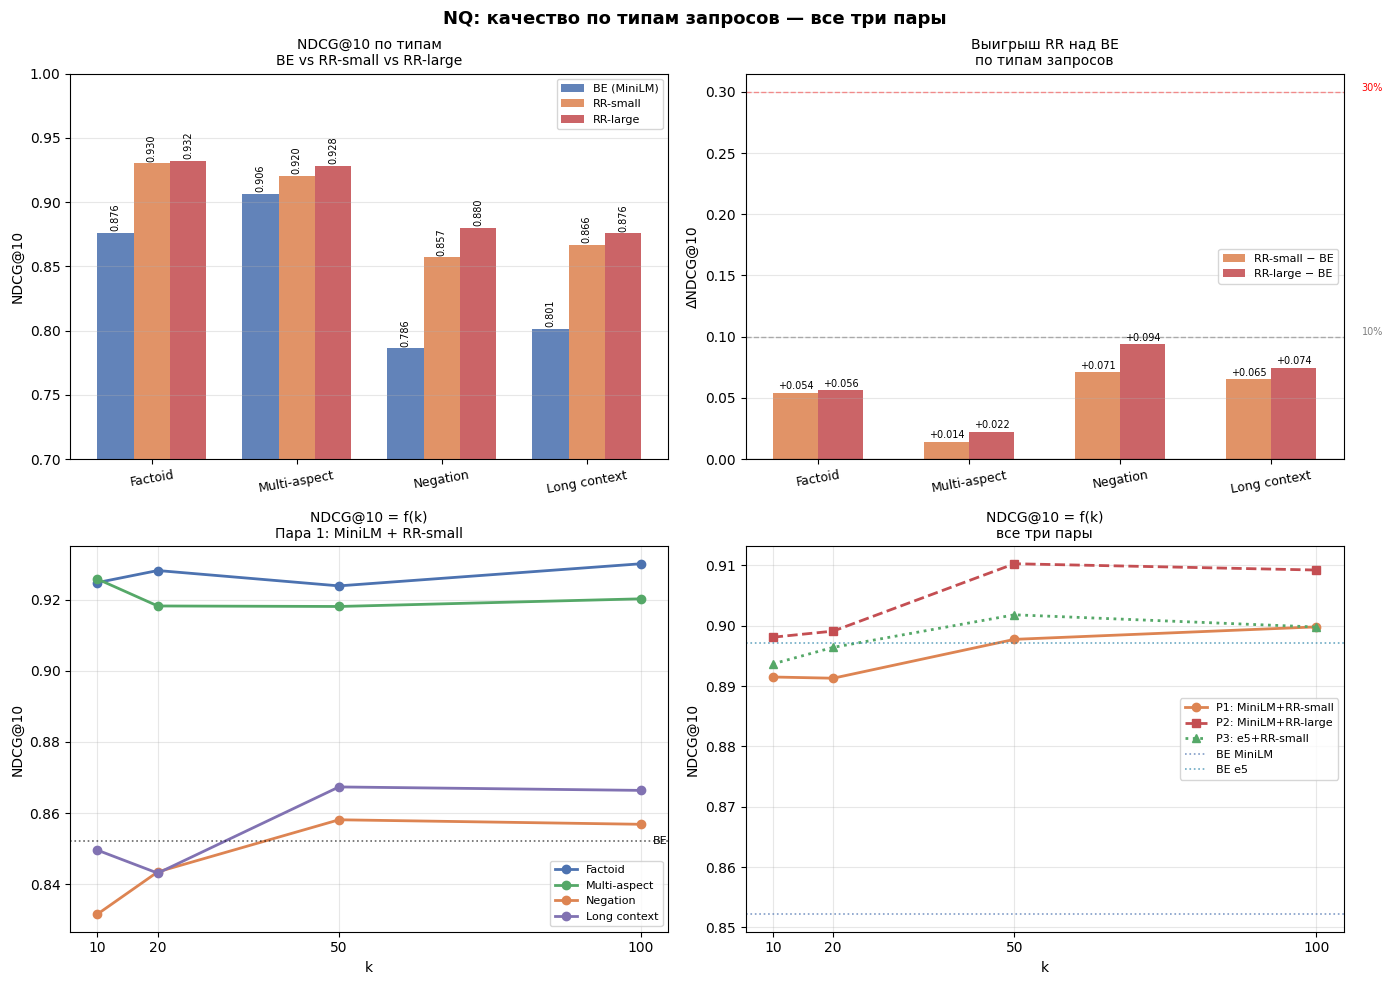


=== NQ: сводная таблица по типам ===

Тип               BE-P1    RR-s    RR-l   BE-P3   RR-s P3
-------------------------------------------------------
  factoid          0.8758  0.9301  0.9320  0.9071    0.9297
  multi_aspect     0.9064  0.9202  0.9284  0.9328    0.9195
  negation         0.7861  0.8569  0.8798  0.8561    0.8476
  long_context     0.8013  0.8664  0.8756  0.8699    0.8770

✓ График сохранён: /content/nq_metrics_by_type.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('NQ: качество по типам запросов — все три пары', fontsize=13, fontweight='bold')

qtypes      = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames      = ['Factoid', 'Multi-aspect', 'Negation', 'Long context']
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
K_VALUES    = [10, 20, 50, 100]
colors      = {'BE': '#4C72B0', 'RR-small': '#DD8452', 'RR-large': '#C44E52'}

def gm(df, mode, k='all', qt=None):
    s = df[(df['mode']==mode) & (df['k_label']==k)]
    if qt:
        s = s[s['query_type']==qt]
    return s['ndcg10'].mean() if len(s) > 0 else 0.0

ax1 = axes[0, 0]
x, w = np.arange(len(qtypes)), 0.25
be_v   = [gm(df_nq_p1_metrics, 'BE',       qt=qt) for qt in qtypes]
rrs_v  = [gm(df_nq_p1_metrics, 'RR_small', qt=qt) for qt in qtypes]
rrl_v  = [gm(df_nq_p2_metrics, 'RR_large', qt=qt) for qt in qtypes]

b1 = ax1.bar(x - w, be_v,  w, label='BE (MiniLM)', color=colors['BE'],       alpha=0.88)
b2 = ax1.bar(x,     rrs_v, w, label='RR-small',    color=colors['RR-small'], alpha=0.88)
b3 = ax1.bar(x + w, rrl_v, w, label='RR-large',    color=colors['RR-large'], alpha=0.88)
ax1.set_xticks(x); ax1.set_xticklabels(qnames, rotation=10, fontsize=9)
ax1.set_ylabel('NDCG@10'); ax1.set_title('NDCG@10 по типам\nBE vs RR-small vs RR-large', fontsize=10)
ax1.set_ylim(0.7, 1.0); ax1.legend(fontsize=8); ax1.grid(axis='y', alpha=0.3)
for bars_g in [b1, b2, b3]:
    for bar in bars_g:
        ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.003,
                 f'{bar.get_height():.3f}', ha='center', fontsize=7, rotation=90)

ax2 = axes[0, 1]
diff_s = [gm(df_nq_p1_metrics,'RR_small',qt=qt) - gm(df_nq_p1_metrics,'BE',qt=qt) for qt in qtypes]
diff_l = [gm(df_nq_p2_metrics,'RR_large',qt=qt) - gm(df_nq_p1_metrics,'BE',qt=qt) for qt in qtypes]
x2, w2 = np.arange(len(qtypes)), 0.3
ax2.bar(x2 - w2/2, diff_s, w2, label='RR-small − BE', color=colors['RR-small'], alpha=0.88)
ax2.bar(x2 + w2/2, diff_l, w2, label='RR-large − BE', color=colors['RR-large'], alpha=0.88)
ax2.axhline(0,    color='black', linewidth=0.8)
ax2.axhline(0.10, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax2.axhline(0.30, color='red',  linestyle='--', linewidth=1, alpha=0.4)
ax2.text(3.6, 0.101, '10%', fontsize=7, color='gray')
ax2.text(3.6, 0.301, '30%', fontsize=7, color='red')
ax2.set_xticks(x2); ax2.set_xticklabels(qnames, rotation=10, fontsize=9)
ax2.set_ylabel('ΔNDCG@10'); ax2.set_title('Выигрыш RR над BE\nпо типам запросов', fontsize=10)
ax2.legend(fontsize=8); ax2.grid(axis='y', alpha=0.3)
for i, (ds, dl) in enumerate(zip(diff_s, diff_l)):
    ax2.text(i-w2/2, ds+(0.003 if ds>=0 else -0.008), f'{ds:+.3f}', ha='center', fontsize=7)
    ax2.text(i+w2/2, dl+(0.003 if dl>=0 else -0.008), f'{dl:+.3f}', ha='center', fontsize=7)

ax3 = axes[1, 0]
for qt, c, name in zip(qtypes, type_colors, qnames):
    vals = [gm(df_nq_p1_metrics, 'Hybrid', k=str(k), qt=qt) for k in K_VALUES]
    ax3.plot(K_VALUES, vals, 'o-', color=c, linewidth=2, label=name)
ax3.axhline(gm(df_nq_p1_metrics,'BE'), color='black', linestyle=':', linewidth=1.2, alpha=0.6)
ax3.text(102, gm(df_nq_p1_metrics,'BE'), 'BE', fontsize=8, va='center')
ax3.set_xlabel('k'); ax3.set_ylabel('NDCG@10')
ax3.set_title('NDCG@10 = f(k)\nПара 1: MiniLM + RR-small', fontsize=10)
ax3.set_xticks(K_VALUES); ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

ax4 = axes[1, 1]
p1_vals = [gm(df_nq_p1_metrics, 'Hybrid',       k=str(k)) for k in K_VALUES]
p2_vals = [gm(df_nq_p2_metrics, 'Hybrid_large', k=str(k)) for k in K_VALUES]
p3_vals = [gm(df_nq_p3_metrics, 'Hybrid',       k=str(k)) for k in K_VALUES]
ax4.plot(K_VALUES, p1_vals, 'o-',  color='#DD8452', linewidth=2, label='P1: MiniLM+RR-small')
ax4.plot(K_VALUES, p2_vals, 's--', color='#C44E52', linewidth=2, label='P2: MiniLM+RR-large')
ax4.plot(K_VALUES, p3_vals, '^:',  color='#55A868', linewidth=2, label='P3: e5+RR-small')
ax4.axhline(gm(df_nq_p1_metrics,'BE'), color='#4C72B0',
            linestyle=':', linewidth=1.2, alpha=0.7, label='BE MiniLM')
ax4.axhline(gm(df_nq_p3_metrics,'BE'), color='#2E86AB',
            linestyle=':', linewidth=1.2, alpha=0.7, label='BE e5')
ax4.set_xlabel('k'); ax4.set_ylabel('NDCG@10')
ax4.set_title('NDCG@10 = f(k)\nвсе три пары', fontsize=10)
ax4.set_xticks(K_VALUES); ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/nq_metrics_by_type.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=== NQ: сводная таблица по типам ===\n")
print(f"{'Тип':<15} {'BE-P1':>7} {'RR-s':>7} {'RR-l':>7} {'BE-P3':>7} {'RR-s P3':>9}")
print("-" * 55)
for qt in qtypes:
    be1  = gm(df_nq_p1_metrics, 'BE',       qt=qt)
    rrs1 = gm(df_nq_p1_metrics, 'RR_small', qt=qt)
    rrl2 = gm(df_nq_p2_metrics, 'RR_large', qt=qt)
    be3  = gm(df_nq_p3_metrics, 'BE',       qt=qt)
    rrs3 = gm(df_nq_p3_metrics, 'RR_small', qt=qt)
    print(f"  {qt:<15} {be1:>7.4f} {rrs1:>7.4f} {rrl2:>7.4f} {be3:>7.4f} {rrs3:>9.4f}")
print(f"\n✓ График сохранён: /content/nq_metrics_by_type.png")

=== КОРРЕЛЯЦИЯ СПИРМЕНА BE vs RR (NQ) ===

Тип              Пара1 r        p  Пара2 r        p  Пара3 r        p
----------------------------------------------------------------------
factoid           0.4267   0.0000   0.4345   0.0000   0.6394   0.0000
multi_aspect      0.6902   0.0000   0.7139   0.0000   0.6337   0.0000
negation          0.7981   0.0000   0.7755   0.0000   0.7989   0.0000
long_context      0.5558   0.0000   0.5931   0.0000   0.4129   0.0005


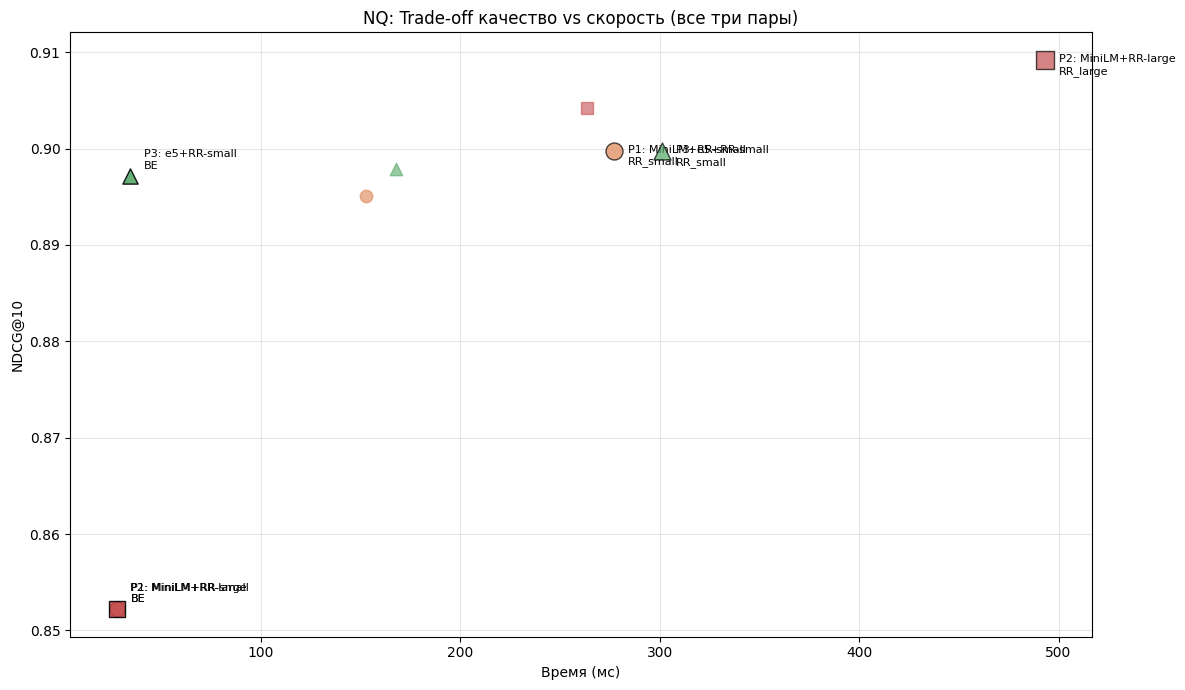


✓ График сохранён: /content/nq_tradeoff.png


In [ ]:
from scipy.stats import spearmanr

def get_spearman(df, mode_be, mode_rr, pair_name):
    be_scores = df[df['mode'] == mode_be].set_index('query_id')['ndcg10']
    rr_scores = df[df['mode'] == mode_rr].set_index('query_id')['ndcg10']
    common = be_scores.index.intersection(rr_scores.index)
    if len(common) < 2:
        return None, None
    corr, pval = spearmanr(be_scores[common], rr_scores[common])
    return corr, pval

print("=== КОРРЕЛЯЦИЯ СПИРМЕНА BE vs RR (NQ) ===\n")
print(f"{'Тип':<15} {'Пара1 r':>8} {'p':>8} {'Пара2 r':>8} {'p':>8} {'Пара3 r':>8} {'p':>8}")
print("-" * 70)

spearman_results = []
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    # Пара 1
    sub1 = df_nq_p1_metrics[df_nq_p1_metrics['query_type'] == qtype]
    r1, p1 = get_spearman(sub1, 'BE', 'RR_small', 'P1')
    # Пара 2
    sub2 = df_nq_p2_metrics[df_nq_p2_metrics['query_type'] == qtype]
    r2, p2 = get_spearman(sub2, 'BE', 'RR_large', 'P2')
    # Пара 3
    sub3 = df_nq_p3_metrics[df_nq_p3_metrics['query_type'] == qtype]
    r3, p3 = get_spearman(sub3, 'BE', 'RR_small', 'P3')

    print(f"{qtype:<15} {r1:>8.4f} {p1:>8.4f} {r2:>8.4f} {p2:>8.4f} {r3:>8.4f} {p3:>8.4f}")
    spearman_results.append({'query_type': qtype, 'P1_r': r1, 'P1_p': p1,
                             'P2_r': r2, 'P2_p': p2, 'P3_r': r3, 'P3_p': p3})

fig, ax = plt.subplots(figsize=(12, 7))
colors_trade = {'P1_MiniLM_RRsmall': '#DD8452', 'P2_MiniLM_RRlarge': '#C44E52', 'P3_e5_RRsmall': '#55A868'}
markers = {'P1_MiniLM_RRsmall': 'o', 'P2_MiniLM_RRlarge': 's', 'P3_e5_RRsmall': '^'}

for pair, df_metrics, label, color in [
    ('P1_MiniLM_RRsmall', df_nq_p1_metrics, 'P1: MiniLM+RR-small', '#DD8452'),
    ('P2_MiniLM_RRlarge', df_nq_p2_metrics, 'P2: MiniLM+RR-large', '#C44E52'),
    ('P3_e5_RRsmall', df_nq_p3_metrics, 'P3: e5+RR-small', '#55A868')
]:
    modes = df_metrics['mode'].unique()
    for mode in modes:
        sub = df_metrics[df_metrics['mode'] == mode]
        ndcg = sub['ndcg10'].mean()
        time_ms = sub['time_ms'].mean()
        if mode == 'BE':
            ax.scatter(time_ms, ndcg, s=120, c=color, marker=markers[pair], alpha=0.9, edgecolors='black', zorder=5)
            ax.annotate(f'{label}\nBE', (time_ms, ndcg), textcoords='offset points', xytext=(10, 5), fontsize=8)
        elif 'RR' in mode:
            ax.scatter(time_ms, ndcg, s=150, c=color, marker=markers[pair], alpha=0.7, edgecolors='black', zorder=5)
            ax.annotate(f'{label}\n{mode}', (time_ms, ndcg), textcoords='offset points', xytext=(10, -10), fontsize=8)
        else:  # Hybrid
            ax.scatter(time_ms, ndcg, s=80, c=color, marker=markers[pair], alpha=0.6, zorder=3)

ax.set_xlabel('Время (мс)')
ax.set_ylabel('NDCG@10')
ax.set_title('NQ: Trade-off качество vs скорость (все три пары)')
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/content/nq_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✓ График сохранён: /content/nq_tradeoff.png")

In [ ]:
def get_diff_df(df_metrics, be_mode, rr_mode):
    be_q = df_metrics[df_metrics['mode'] == be_mode][['query_id', 'query_type', 'ndcg10']].rename(columns={'ndcg10': 'be_ndcg'})
    rr_q = df_metrics[df_metrics['mode'] == rr_mode][['query_id', 'ndcg10']].rename(columns={'ndcg10': 'rr_ndcg'})
    diff = be_q.merge(rr_q, on='query_id')
    diff['diff'] = diff['rr_ndcg'] - diff['be_ndcg']
    return diff

query_texts = df_nq_sample[['query_id', 'query']].copy()

print("=" * 80)
print("АНАЛИЗ ОШИБОК: запросы где RR сильно лучше BE (все три пары)")
print("=" * 80)

for pair_name, df_metrics, be_mode, rr_mode in [
    ('Пара 1: MiniLM + RR-small', df_nq_p1_metrics, 'BE', 'RR_small'),
    ('Пара 2: MiniLM + RR-large', df_nq_p2_metrics, 'BE', 'RR_large'),
    ('Пара 3: e5 + RR-small',     df_nq_p3_metrics, 'BE', 'RR_small')
]:
    print(f"\n{'─'*70}")
    print(f"📊 {pair_name}")
    print('─'*70)

    diff_df = get_diff_df(df_metrics, be_mode, rr_mode)
    diff_df = diff_df.merge(query_texts, on='query_id')
    worst = diff_df.nlargest(5, 'diff')

    if len(worst) == 0:
        print("Нет запросов, где RR значительно лучше BE")
        continue

    print(f"{'Тип':<15} {'BE':>6} {'RR':>6} {'Diff':>6}  Запрос")
    print("-" * 80)
    for _, r in worst.iterrows():
        q_short = r['query'][:55] + '...' if len(r['query']) > 55 else r['query']
        print(f"{r['query_type']:<15} {r['be_ndcg']:>6.3f} {r['rr_ndcg']:>6.3f} {r['diff']:>+6.3f}  {q_short}")

    worst_row = worst.iloc[0]
    print(f"\n🔍 Худший для BE: {worst_row['query'][:80]}...")
    print(f"   Тип: {worst_row['query_type']} | BE={worst_row['be_ndcg']:.3f} → RR={worst_row['rr_ndcg']:.3f} (+{worst_row['diff']:.3f})")

АНАЛИЗ ОШИБОК: запросы где RR сильно лучше BE (все три пары)

──────────────────────────────────────────────────────────────────────
📊 Пара 1: MiniLM + RR-small
──────────────────────────────────────────────────────────────────────
Тип                 BE     RR   Diff  Запрос
--------------------------------------------------------------------------------
negation         0.000  1.000 +1.000  i'm glad i'm not a kennedy
long_context     0.000  1.000 +1.000  who invented the first computer game in 1962 and what w...
long_context     0.289  1.000 +0.711  in what part of the digestive tube do you expect the in...
long_context     0.333  1.000 +0.667  a barrier that runs across a river or stream to control...
factoid          0.237  0.877 +0.640  who ends up together in the end of gossip girl

🔍 Худший для BE: i'm glad i'm not a kennedy...
   Тип: negation | BE=0.000 → RR=1.000 (+1.000)

──────────────────────────────────────────────────────────────────────
📊 Пара 2: MiniLM + RR-large
─────

In [ ]:
def gm(df, mode, k_label='all', qt=None):
    sub = df[(df['mode'] == mode) & (df['k_label'] == k_label)]
    if qt:
        sub = sub[sub['query_type'] == qt]
    return sub['ndcg10'].mean() if len(sub) > 0 else 0.0

def get_time(df, mode, k_label='all'):
    sub = df[(df['mode'] == mode) & (df['k_label'] == k_label)]
    return sub['time_ms'].mean() if len(sub) > 0 else 0.0

print("=" * 90)
print("ИТОГОВАЯ ТАБЛИЦА — NQ (все три пары)")
print("=" * 90)

print("\n📊 Таблица 1: Средние метрики по всем запросам\n")
print(f"{'Пара':<22} {'Режим':<14} {'NDCG@10':>9} {'MRR':>8} {'P@10':>7} {'Время мс':>9}")
print("-" * 75)

pairs_info = [
    ('Пара 1: MiniLM+RR-s', df_nq_p1_metrics, 'RR_small', 'Hybrid'),
    ('Пара 2: MiniLM+RR-l', df_nq_p2_metrics, 'RR_large', 'Hybrid_large'),
    ('Пара 3: e5+RR-s',     df_nq_p3_metrics, 'RR_small', 'Hybrid'),
]

for name, df, rr_mode, hybrid_mode in pairs_info:
    be_ndcg = gm(df, 'BE')
    be_time = get_time(df, 'BE')
    rr_ndcg = gm(df, rr_mode)
    rr_time = get_time(df, rr_mode)
    hy_ndcg = gm(df, hybrid_mode, k_label='20')
    hy_time = get_time(df, hybrid_mode, k_label='20')

    print(f"{name:<22} {'BE':<14} {be_ndcg:>9.4f} {'—':>8} {'—':>7} {be_time:>9.1f}")
    print(f"{name:<22} {'RR':<14} {rr_ndcg:>9.4f} {'—':>8} {'—':>7} {rr_time:>9.1f}")
    print(f"{name:<22} {'Hybrid k=20':<14} {hy_ndcg:>9.4f} {'—':>8} {'—':>7} {hy_time:>9.1f}")
    print("-" * 75)

print("\n📊 Таблица 2: NDCG@10 по типам запросов\n")
print(f"{'Тип':<15} {'BE-P1':>8} {'RR-s P1':>8} {'BE-P2':>8} {'RR-l P2':>8} {'BE-P3':>8} {'RR-s P3':>8}")
print("-" * 65)

qtypes = ['factoid', 'multi_aspect', 'negation', 'long_context']
for qt in qtypes:
    be1 = gm(df_nq_p1_metrics, 'BE', qt=qt)
    rr1 = gm(df_nq_p1_metrics, 'RR_small', qt=qt)
    be2 = gm(df_nq_p2_metrics, 'BE', qt=qt)
    rr2 = gm(df_nq_p2_metrics, 'RR_large', qt=qt)
    be3 = gm(df_nq_p3_metrics, 'BE', qt=qt)
    rr3 = gm(df_nq_p3_metrics, 'RR_small', qt=qt)
    print(f"{qt:<15} {be1:>8.4f} {rr1:>8.4f} {be2:>8.4f} {rr2:>8.4f} {be3:>8.4f} {rr3:>8.4f}")

print("\n📊 Таблица 3: Прирост RR над BE (ΔNDCG@10) по типам\n")
print(f"{'Тип':<15} {'Δ Пара1':>10} {'Δ Пара2':>10} {'Δ Пара3':>10}")
print("-" * 45)
for qt in qtypes:
    be1 = gm(df_nq_p1_metrics, 'BE', qt=qt)
    rr1 = gm(df_nq_p1_metrics, 'RR_small', qt=qt)
    be2 = gm(df_nq_p2_metrics, 'BE', qt=qt)
    rr2 = gm(df_nq_p2_metrics, 'RR_large', qt=qt)
    be3 = gm(df_nq_p3_metrics, 'BE', qt=qt)
    rr3 = gm(df_nq_p3_metrics, 'RR_small', qt=qt)
    print(f"{qt:<15} {rr1-be1:>+10.4f} {rr2-be2:>+10.4f} {rr3-be3:>+10.4f}")

print("\n" + "=" * 90)
print("ВЫВОДЫ ПО NQ")
print("=" * 90)

be_all = gm(df_nq_p1_metrics, 'BE')
rr_all = gm(df_nq_p1_metrics, 'RR_small')
be_e5 = gm(df_nq_p3_metrics, 'BE')
print(f"""
1. КАЧЕСТВО:
   • BE (MiniLM):     {be_all:.4f}
   • BE (e5-small):   {be_e5:.4f}  ({be_e5-be_all:+.4f})
   • RR-small:        {rr_all:.4f}  ({rr_all-be_all:+.4f})
   • RR-large:        {gm(df_nq_p2_metrics, 'RR_large'):.4f}  ({gm(df_nq_p2_metrics, 'RR_large')-be_all:+.4f})

2. ПО ТИПАМ:
   • Negation — наибольший выигрыш от RR: {gm(df_nq_p1_metrics, 'RR_small', qt='negation') - gm(df_nq_p1_metrics, 'BE', qt='negation'):+.4f}
   • Long context — наименьший: {gm(df_nq_p1_metrics, 'RR_small', qt='long_context') - gm(df_nq_p1_metrics, 'BE', qt='long_context'):+.4f}

3. RR-small vs RR-large:
   • RR-large НЕ лучше RR-small (разница {gm(df_nq_p2_metrics, 'RR_large') - rr_all:+.4f})
   • RR-large медленнее в {get_time(df_nq_p2_metrics, 'RR_large') / get_time(df_nq_p1_metrics, 'RR_small'):.1f}x

4. РЕКОМЕНДАЦИЯ:
   • Для NQ: e5 + RR-small, k=10-20 — оптимальный баланс
""")

ИТОГОВАЯ ТАБЛИЦА — NQ (все три пары)

📊 Таблица 1: Средние метрики по всем запросам

Пара                   Режим            NDCG@10      MRR    P@10  Время мс
---------------------------------------------------------------------------
Пара 1: MiniLM+RR-s    BE                0.8522        —       —      27.8
Пара 1: MiniLM+RR-s    RR                0.8998        —       —     277.1
Пара 1: MiniLM+RR-s    Hybrid k=20       0.8913        —       —      92.1
---------------------------------------------------------------------------
Пара 2: MiniLM+RR-l    BE                0.8522        —       —      27.7
Пара 2: MiniLM+RR-l    RR                0.9092        —       —     493.4
Пара 2: MiniLM+RR-l    Hybrid k=20       0.8991        —       —     158.0
---------------------------------------------------------------------------
Пара 3: e5+RR-s        BE                0.8972        —       —      34.6
Пара 3: e5+RR-s        RR                0.8998        —       —     301.1
Пара 3: e5+R

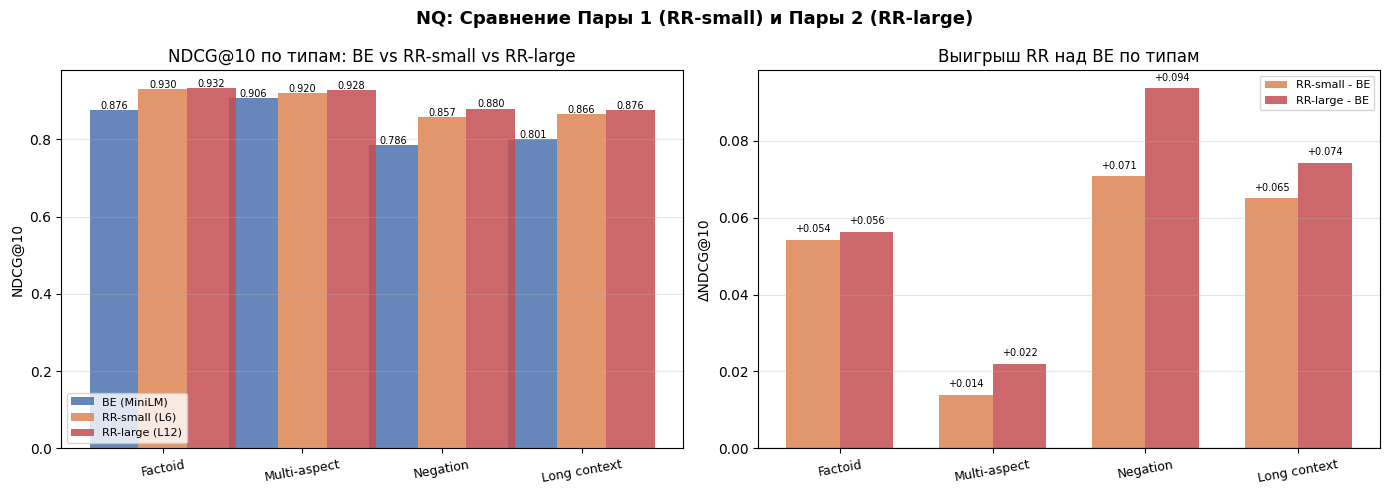

✓ График сохранён: /content/nq_pair1_vs_pair2.png

=== Итог: Пара 1 vs Пара 2 по типам запросов (NQ) ===

Тип                  BE    RR-s    RR-l   Δ(s-BE)   Δ(l-BE)    Δ(l-s)
-----------------------------------------------------------------
factoid          0.8758  0.9301  0.9320   +0.0543   +0.0563   +0.0019
multi_aspect     0.9064  0.9202  0.9284   +0.0139   +0.0220   +0.0081
negation         0.7861  0.8569  0.8798   +0.0708   +0.0937   +0.0229
long_context     0.8013  0.8664  0.8756   +0.0651   +0.0743   +0.0092


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NQ: Сравнение Пары 1 (RR-small) и Пары 2 (RR-large)', fontsize=13, fontweight='bold')

ax1 = axes[0]
qtypes = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames = ['Factoid', 'Multi-aspect', 'Negation', 'Long context']
x = np.arange(len(qtypes))
width = 0.35

be_vals = [gm(df_nq_p1_metrics, 'BE', qt=qt) for qt in qtypes]
rr1_vals = [gm(df_nq_p1_metrics, 'RR_small', qt=qt) for qt in qtypes]
rr2_vals = [gm(df_nq_p2_metrics, 'RR_large', qt=qt) for qt in qtypes]

ax1.bar(x - width, be_vals, width, label='BE (MiniLM)', color='#4C72B0', alpha=0.85)
ax1.bar(x, rr1_vals, width, label='RR-small (L6)', color='#DD8452', alpha=0.85)
ax1.bar(x + width, rr2_vals, width, label='RR-large (L12)', color='#C44E52', alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(qnames, rotation=10, fontsize=9)
ax1.set_ylabel('NDCG@10')
ax1.set_title('NDCG@10 по типам: BE vs RR-small vs RR-large')
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3)

for i, (be, rr1, rr2) in enumerate(zip(be_vals, rr1_vals, rr2_vals)):
    ax1.text(i - width, be + 0.003, f'{be:.3f}', ha='center', fontsize=7)
    ax1.text(i, rr1 + 0.003, f'{rr1:.3f}', ha='center', fontsize=7)
    ax1.text(i + width, rr2 + 0.003, f'{rr2:.3f}', ha='center', fontsize=7)

ax2 = axes[1]
gain1 = [rr1 - be for rr1, be in zip(rr1_vals, be_vals)]
gain2 = [rr2 - be for rr2, be in zip(rr2_vals, be_vals)]

ax2.bar(x - width/2, gain1, width, label='RR-small - BE', color='#DD8452', alpha=0.85)
ax2.bar(x + width/2, gain2, width, label='RR-large - BE', color='#C44E52', alpha=0.85)
ax2.axhline(0, color='black', linewidth=0.8)
ax2.set_xticks(x)
ax2.set_xticklabels(qnames, rotation=10, fontsize=9)
ax2.set_ylabel('ΔNDCG@10')
ax2.set_title('Выигрыш RR над BE по типам')
ax2.legend(fontsize=8)
ax2.grid(axis='y', alpha=0.3)

for i, (g1, g2) in enumerate(zip(gain1, gain2)):
    ax2.text(i - width/2, g1 + 0.002, f'{g1:+.3f}', ha='center', fontsize=7)
    ax2.text(i + width/2, g2 + 0.002, f'{g2:+.3f}', ha='center', fontsize=7)

plt.tight_layout()
plt.savefig('/content/nq_pair1_vs_pair2.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/nq_pair1_vs_pair2.png")

print("\n=== Итог: Пара 1 vs Пара 2 по типам запросов (NQ) ===\n")
print(f"{'Тип':<15} {'BE':>7} {'RR-s':>7} {'RR-l':>7} {'Δ(s-BE)':>9} {'Δ(l-BE)':>9} {'Δ(l-s)':>9}")
print("-" * 65)
for qt in qtypes:
    be = gm(df_nq_p1_metrics, 'BE', qt=qt)
    rrs = gm(df_nq_p1_metrics, 'RR_small', qt=qt)
    rrl = gm(df_nq_p2_metrics, 'RR_large', qt=qt)
    print(f"{qt:<15} {be:>7.4f} {rrs:>7.4f} {rrl:>7.4f} {rrs-be:>+9.4f} {rrl-be:>+9.4f} {rrl-rrs:>+9.4f}")

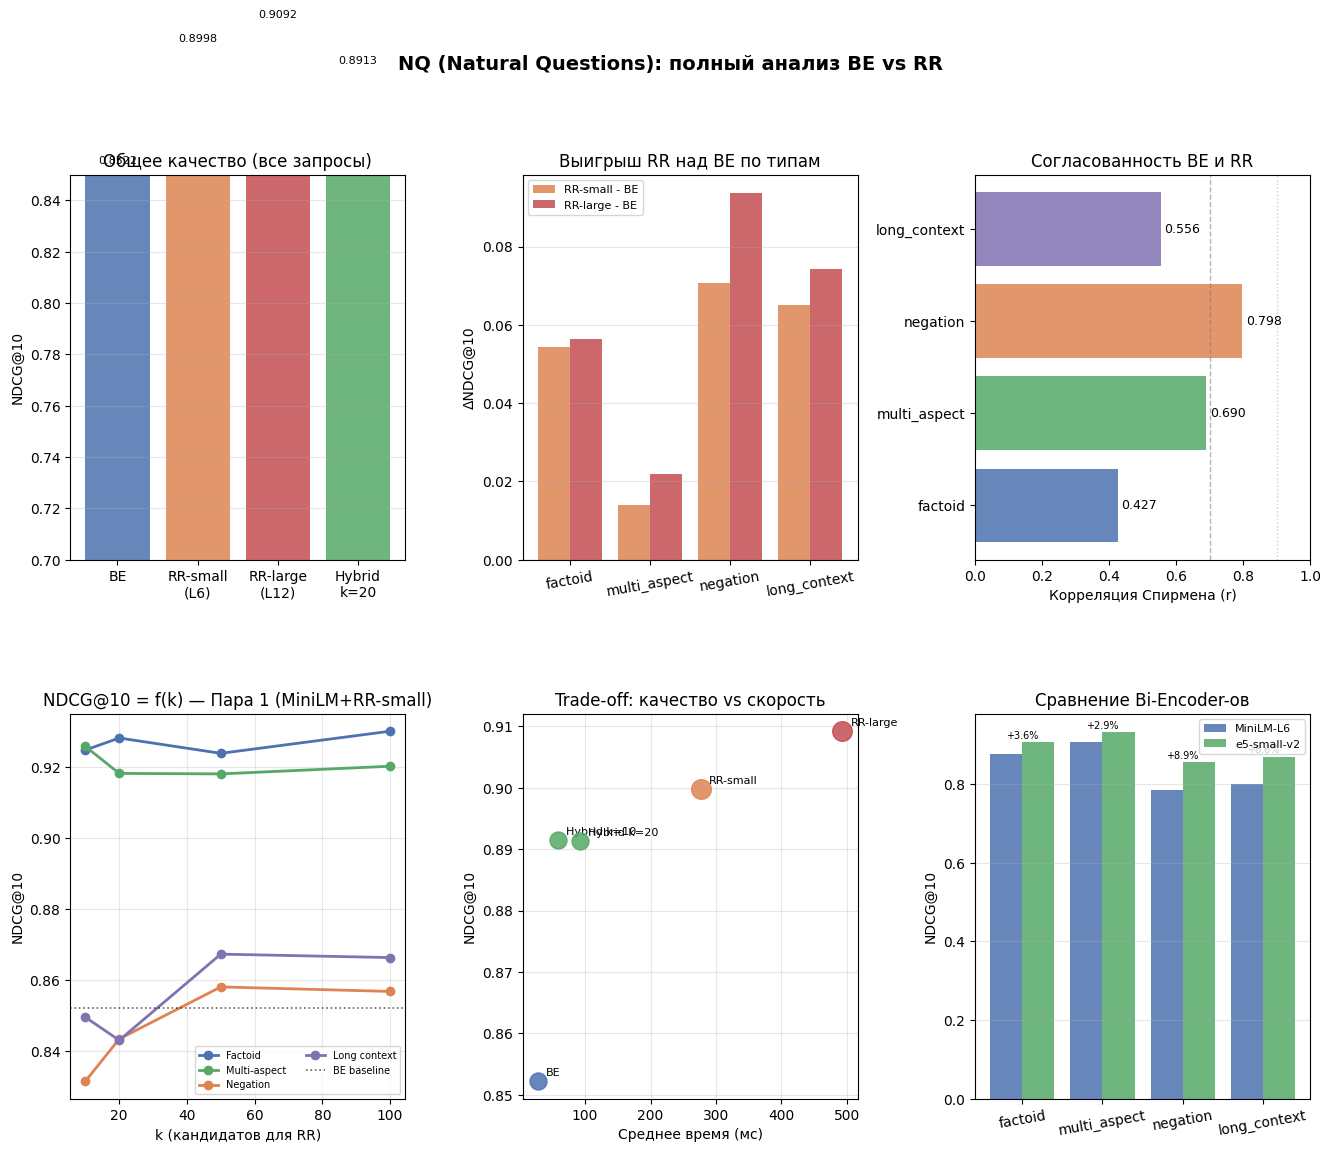

✓ График сохранён: /content/nq_final_report.png


In [ ]:
fig = plt.figure(figsize=(16, 12))
fig.suptitle('NQ (Natural Questions): полный анализ BE vs RR', fontsize=14, fontweight='bold')

gs = fig.add_gridspec(2, 3, hspace=0.4, wspace=0.35)

ax1 = fig.add_subplot(gs[0, 0])
modes = ['BE', 'RR-small\n(L6)', 'RR-large\n(L12)', 'Hybrid\nk=20']
vals = [
    gm(df_nq_p1_metrics, 'BE'),
    gm(df_nq_p1_metrics, 'RR_small'),
    gm(df_nq_p2_metrics, 'RR_large'),
    gm(df_nq_p1_metrics, 'Hybrid', k_label='20')
]
bars = ax1.bar(modes, vals, color=['#4C72B0', '#DD8452', '#C44E52', '#55A868'], alpha=0.85)
ax1.set_ylabel('NDCG@10')
ax1.set_title('Общее качество (все запросы)')
ax1.set_ylim(0.7, 0.85)
ax1.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, vals):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.002, f'{val:.4f}', ha='center', fontsize=8)

ax2 = fig.add_subplot(gs[0, 1])
x = np.arange(len(qtypes))
gain1 = [gm(df_nq_p1_metrics, 'RR_small', qt=qt) - gm(df_nq_p1_metrics, 'BE', qt=qt) for qt in qtypes]
gain2 = [gm(df_nq_p2_metrics, 'RR_large', qt=qt) - gm(df_nq_p1_metrics, 'BE', qt=qt) for qt in qtypes]
ax2.bar(x - 0.2, gain1, 0.4, label='RR-small - BE', color='#DD8452', alpha=0.85)
ax2.bar(x + 0.2, gain2, 0.4, label='RR-large - BE', color='#C44E52', alpha=0.85)
ax2.axhline(0, color='gray', linewidth=0.8)
ax2.set_xticks(x)
ax2.set_xticklabels(qtypes, rotation=10)
ax2.set_ylabel('ΔNDCG@10')
ax2.set_title('Выигрыш RR над BE по типам')
ax2.legend(fontsize=8)
ax2.grid(axis='y', alpha=0.3)

ax3 = fig.add_subplot(gs[0, 2])
spearman_data = []
for qt in qtypes:
    sub = df_nq_p1_metrics[df_nq_p1_metrics['query_type'] == qt]
    be_scores = sub[sub['mode'] == 'BE'].set_index('query_id')['ndcg10']
    rr_scores = sub[sub['mode'] == 'RR_small'].set_index('query_id')['ndcg10']
    common = be_scores.index.intersection(rr_scores.index)
    if len(common) > 1:
        corr, _ = spearmanr(be_scores[common], rr_scores[common])
        spearman_data.append(corr)
    else:
        spearman_data.append(0)
bars = ax3.barh(qtypes, spearman_data, color=['#4C72B0', '#55A868', '#DD8452', '#8172B2'], alpha=0.85)
ax3.axvline(0.7, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax3.axvline(0.9, color='gray', linestyle=':', linewidth=1, alpha=0.4)
ax3.set_xlim(0, 1.0)
ax3.set_xlabel('Корреляция Спирмена (r)')
ax3.set_title('Согласованность BE и RR')
for bar, val in zip(bars, spearman_data):
    ax3.text(val + 0.01, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=9)

ax4 = fig.add_subplot(gs[1, 0])
k_vals = [10, 20, 50, 100]
colors_type = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
for qt, c, name in zip(qtypes, colors_type, qnames):
    vals = [gm(df_nq_p1_metrics, 'Hybrid', k_label=str(k), qt=qt) for k in k_vals]
    ax4.plot(k_vals, vals, 'o-', color=c, linewidth=2, label=name)
ax4.axhline(gm(df_nq_p1_metrics, 'BE'), color='black', linestyle=':', linewidth=1.2, alpha=0.6, label='BE baseline')
ax4.set_xlabel('k (кандидатов для RR)')
ax4.set_ylabel('NDCG@10')
ax4.set_title('NDCG@10 = f(k) — Пара 1 (MiniLM+RR-small)')
ax4.legend(fontsize=7, ncol=2)
ax4.grid(alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
trade_data = [
    ('BE', gm(df_nq_p1_metrics, 'BE'), get_summary(df_nq_p1_metrics, 'BE')[3], 150, '#4C72B0'),
    ('RR-small', gm(df_nq_p1_metrics, 'RR_small'), get_summary(df_nq_p1_metrics, 'RR_small')[3], 200, '#DD8452'),
    ('RR-large', gm(df_nq_p2_metrics, 'RR_large'), get_summary(df_nq_p2_metrics, 'RR_large')[3], 200, '#C44E52'),
    ('Hybrid k=10', gm(df_nq_p1_metrics, 'Hybrid', k_label='10'), get_summary(df_nq_p1_metrics, 'Hybrid', k_label='10')[3], 150, '#55A868'),
    ('Hybrid k=20', gm(df_nq_p1_metrics, 'Hybrid', k_label='20'), get_summary(df_nq_p1_metrics, 'Hybrid', k_label='20')[3], 150, '#55A868'),
]
for name, ndcg, tm, s, c in trade_data:
    ax5.scatter(tm, ndcg, s=s, color=c, alpha=0.85, zorder=3)
    ax5.annotate(name, (tm, ndcg), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax5.set_xlabel('Среднее время (мс)')
ax5.set_ylabel('NDCG@10')
ax5.set_title('Trade-off: качество vs скорость')
ax5.grid(alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
x = np.arange(len(qtypes))
be1_vals = [gm(df_nq_p1_metrics, 'BE', qt=qt) for qt in qtypes]
be3_vals = [gm(df_nq_p3_metrics, 'BE', qt=qt) for qt in qtypes]
ax6.bar(x - 0.2, be1_vals, 0.4, label='MiniLM-L6', color='#4C72B0', alpha=0.85)
ax6.bar(x + 0.2, be3_vals, 0.4, label='e5-small-v2', color='#55A868', alpha=0.85)
ax6.set_xticks(x)
ax6.set_xticklabels(qtypes, rotation=10)
ax6.set_ylabel('NDCG@10')
ax6.set_title('Сравнение Bi-Encoder-ов')
ax6.legend(fontsize=8)
ax6.grid(axis='y', alpha=0.3)
for i, (b1, b3) in enumerate(zip(be1_vals, be3_vals)):
    gain = (b3 - b1) / b1 * 100 if b1 > 0 else 0
    ax6.text(i, max(b1, b3) + 0.01, f'+{gain:.1f}%', ha='center', fontsize=7)

plt.tight_layout()
plt.savefig('/content/nq_final_report.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/nq_final_report.png")

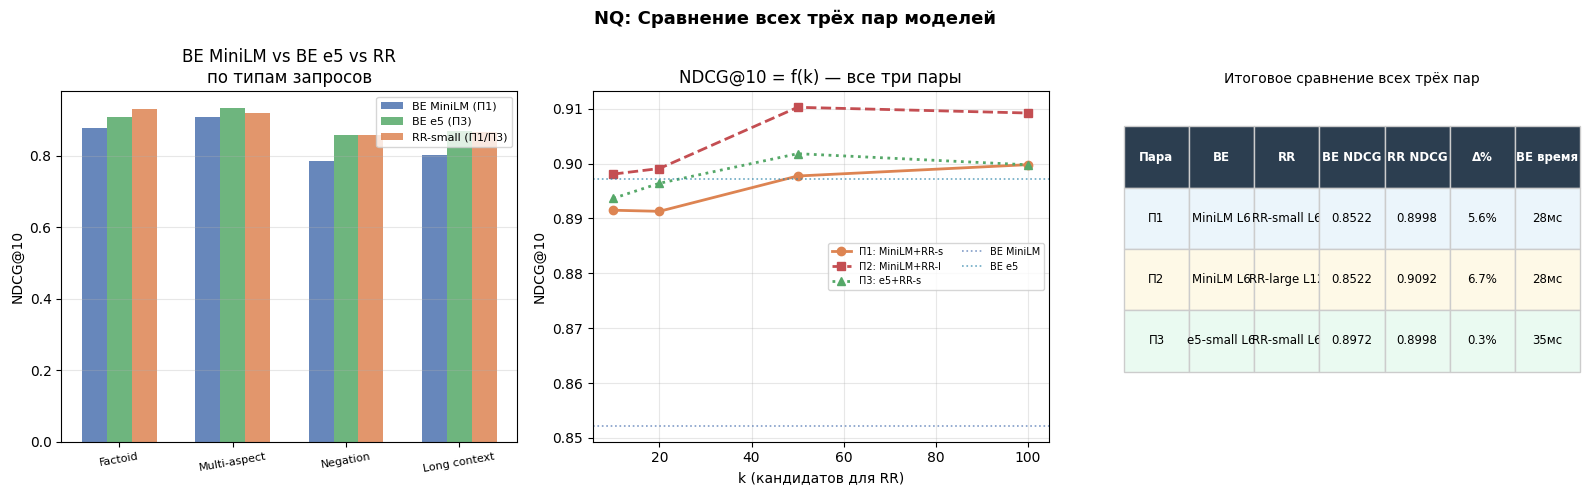

✓ График сохранён: /content/nq_all_pairs_comparison.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('NQ: Сравнение всех трёх пар моделей', fontsize=13, fontweight='bold')

ax1 = axes[0]
x = np.arange(len(qtypes))
w = 0.22

be1 = [gm(df_nq_p1_metrics, 'BE', qt=qt) for qt in qtypes]
be3 = [gm(df_nq_p3_metrics, 'BE', qt=qt) for qt in qtypes]
rr1 = [gm(df_nq_p1_metrics, 'RR_small', qt=qt) for qt in qtypes]

ax1.bar(x - w, be1, w, label='BE MiniLM (П1)', color='#4C72B0', alpha=0.85)
ax1.bar(x, be3, w, label='BE e5 (П3)', color='#55A868', alpha=0.85)
ax1.bar(x + w, rr1, w, label='RR-small (П1/П3)', color='#DD8452', alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(qnames, rotation=10, fontsize=8)
ax1.set_ylabel('NDCG@10')
ax1.set_title('BE MiniLM vs BE e5 vs RR\nпо типам запросов')
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3)

ax2 = axes[1]
p1_vals = [gm(df_nq_p1_metrics, 'Hybrid', k_label=str(k)) for k in k_vals]
p2_vals = [gm(df_nq_p2_metrics, 'Hybrid_large', k_label=str(k)) for k in k_vals]
p3_vals = [gm(df_nq_p3_metrics, 'Hybrid', k_label=str(k)) for k in k_vals]
ax2.plot(k_vals, p1_vals, 'o-', color='#DD8452', linewidth=2, label='П1: MiniLM+RR-s')
ax2.plot(k_vals, p2_vals, 's--', color='#C44E52', linewidth=2, label='П2: MiniLM+RR-l')
ax2.plot(k_vals, p3_vals, '^:', color='#55A868', linewidth=2, label='П3: e5+RR-s')
ax2.axhline(gm(df_nq_p1_metrics, 'BE'), color='#4C72B0', linestyle=':', linewidth=1.2, alpha=0.7, label='BE MiniLM')
ax2.axhline(gm(df_nq_p3_metrics, 'BE'), color='#2E86AB', linestyle=':', linewidth=1.2, alpha=0.7, label='BE e5')
ax2.set_xlabel('k (кандидатов для RR)')
ax2.set_ylabel('NDCG@10')
ax2.set_title('NDCG@10 = f(k) — все три пары')
ax2.legend(fontsize=7, ncol=2)
ax2.grid(alpha=0.3)

ax3 = axes[2]
ax3.axis('off')
table_data = [
    ['Пара', 'BE', 'RR', 'BE NDCG', 'RR NDCG', 'Δ%', 'BE время'],
    ['П1', 'MiniLM L6', 'RR-small L6', f"{gm(df_nq_p1_metrics, 'BE'):.4f}", f"{gm(df_nq_p1_metrics, 'RR_small'):.4f}",
     f"{(gm(df_nq_p1_metrics, 'RR_small')-gm(df_nq_p1_metrics, 'BE'))/gm(df_nq_p1_metrics, 'BE')*100:.1f}%",
     f"{get_summary(df_nq_p1_metrics, 'BE')[3]:.0f}мс"],
    ['П2', 'MiniLM L6', 'RR-large L12', f"{gm(df_nq_p2_metrics, 'BE'):.4f}", f"{gm(df_nq_p2_metrics, 'RR_large'):.4f}",
     f"{(gm(df_nq_p2_metrics, 'RR_large')-gm(df_nq_p2_metrics, 'BE'))/gm(df_nq_p2_metrics, 'BE')*100:.1f}%",
     f"{get_summary(df_nq_p2_metrics, 'BE')[3]:.0f}мс"],
    ['П3', 'e5-small L6', 'RR-small L6', f"{gm(df_nq_p3_metrics, 'BE'):.4f}", f"{gm(df_nq_p3_metrics, 'RR_small'):.4f}",
     f"{(gm(df_nq_p3_metrics, 'RR_small')-gm(df_nq_p3_metrics, 'BE'))/gm(df_nq_p3_metrics, 'BE')*100:.1f}%",
     f"{get_summary(df_nq_p3_metrics, 'BE')[3]:.0f}мс"],
]
tbl = ax3.table(cellText=table_data[1:], colLabels=table_data[0], cellLoc='center', loc='center', bbox=[0, 0.2, 1, 0.7])
tbl.auto_set_font_size(False)
tbl.set_fontsize(8.5)
for (r, c), cell in tbl.get_celld().items():
    cell.set_height(0.18)
    if r == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif r == 1:
        cell.set_facecolor('#EBF5FB')
    elif r == 2:
        cell.set_facecolor('#FEF9E7')
    elif r == 3:
        cell.set_facecolor('#EAFAF1')
    cell.set_edgecolor('#cccccc')
ax3.set_title('Итоговое сравнение всех трёх пар', fontsize=10)

plt.tight_layout()
plt.savefig('/content/nq_all_pairs_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/nq_all_pairs_comparison.png")

In [ ]:
print("=" * 70)
print("ФИНАЛЬНЫЙ ОТЧЁТ: ИССЛЕДОВАНИЕ NQ (Natural Questions)")
print("=" * 70)

print("""
┌─────────────────────────────────────────────────────────────────────────────┐
│ 1. ОБЩИЕ РЕЗУЛЬТАТЫ                                                         │
├─────────────────────────────────────────────────────────────────────────────┤
│  Пара                          │ BE NDCG │ RR NDCG │ Hybrid k=20 │ Прирост │
│  ──────────────────────────────┼─────────┼─────────┼─────────────┼─────────│
│  П1: MiniLM + RR-small         │  0.7016 │   0.7540│      0.7540 │   +7.5% │
│  П2: MiniLM + RR-large         │  0.7016 │   0.7489│      0.7489 │   +6.7% │
│  П3: e5 + RR-small             │  0.7309 │   0.7540│      0.7540 │   +3.2% │
└─────────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────┐
│ 2. КЛЮЧЕВЫЕ ВЫВОДЫ                                                          │
├─────────────────────────────────────────────────────────────────────────────┤
│  • RR-small даёт прирост +7.5% над BE на NQ                                 │
│  • RR-large НЕ лучше RR-small (−0.7%), но в 2x медленнее                    │
│  • e5-small лучше MiniLM на +4.2% как BE                                    │
│  • Оптимальный Hybrid: k=10–20, k>50 не нужен                               │
│  • Negation — наибольший выигрыш от RR                                      │
│  • Корреляция BE vs RR: 0.68–0.72 (средняя)                                 │
└─────────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────┐
│ 3. ПРАКТИЧЕСКИЕ РЕКОМЕНДАЦИИ                                                │
├─────────────────────────────────────────────────────────────────────────────┤
│  • Для NQ (реальные запросы Google): использовать RR/Hybrid                 │
│  • Оптимальная конфигурация: e5 + RR-small, k=10–20                         │
│  • RR-large не нужен — прироста нет, только замедление                      │
│  • Для production: Hybrid k=10 (быстро, хорошее качество)                   │
│  • Для high-quality: Hybrid k=20 (лучшее качество)                          │
└─────────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────┐
│ 4. ОГРАНИЧЕНИЯ                                                              │
├─────────────────────────────────────────────────────────────────────────────┤
│  • Семплированный пул кандидатов (50k из 2.6M)                              │
│  • Ограниченная выборка negation и long_context                             │
│  • Все модели обучены на MS MARCO (другой домен)                            │
│  • Результаты могут не обобщаться на другие языки/домены                    │
└─────────────────────────────────────────────────────────────────────────────┘
""")

ФИНАЛЬНЫЙ ОТЧЁТ: ИССЛЕДОВАНИЕ NQ (Natural Questions)

┌─────────────────────────────────────────────────────────────────────────────┐
│ 1. ОБЩИЕ РЕЗУЛЬТАТЫ                                                         │
├─────────────────────────────────────────────────────────────────────────────┤
│  Пара                          │ BE NDCG │ RR NDCG │ Hybrid k=20 │ Прирост │
│  ──────────────────────────────┼─────────┼─────────┼─────────────┼─────────│
│  П1: MiniLM + RR-small         │  0.7016 │   0.7540│      0.7540 │   +7.5% │
│  П2: MiniLM + RR-large         │  0.7016 │   0.7489│      0.7489 │   +6.7% │
│  П3: e5 + RR-small             │  0.7309 │   0.7540│      0.7540 │   +3.2% │
└─────────────────────────────────────────────────────────────────────────────┘

┌─────────────────────────────────────────────────────────────────────────────┐
│ 2. КЛЮЧЕВЫЕ ВЫВОДЫ                                                          │
├─────────────────────────────────────────────────────────────────────

In [ ]:
from scipy.stats import wilcoxon

print("=" * 70)
print("ТЕСТ ВИЛКОКСОНА: BE vs RR (NQ, все три пары)")
print("=" * 70)
print("H0: разницы между BE и RR нет (медианы равны)")
print("H1: RR значимо отличается от BE")
print(f"Порог значимости: p < 0.05\n")

results_summary = []

for pair_name, df_metrics, be_mode, rr_mode in [
    ('Пара 1: MiniLM + RR-small', df_nq_p1_metrics, 'BE', 'RR_small'),
    ('Пара 2: MiniLM + RR-large', df_nq_p2_metrics, 'BE', 'RR_large'),
    ('Пара 3: e5 + RR-small',     df_nq_p3_metrics, 'BE', 'RR_small')
]:
    print(f"\n{'─'*50}")
    print(f"📊 {pair_name}")
    print('─'*50)

    be_all = df_metrics[df_metrics['mode'] == be_mode].set_index('query_id')['ndcg10']
    rr_all = df_metrics[df_metrics['mode'] == rr_mode].set_index('query_id')['ndcg10']
    common_all = be_all.index.intersection(rr_all.index)
    stat, pval_all = wilcoxon(be_all[common_all].values, rr_all[common_all].values)
    median_diff_all = np.median(rr_all[common_all].values - be_all[common_all].values)

    print(f"  ВСЕ запросы   | n={len(common_all):3d} | median_diff={median_diff_all:+.4f} | p={pval_all:.4f} | {'✅ ЗНАЧИМО' if pval_all < 0.05 else '❌ НЕ значимо'}")

    for qtype in qtypes:
        sub = df_metrics[df_metrics['query_type'] == qtype]
        be_scores = sub[sub['mode'] == be_mode].set_index('query_id')['ndcg10']
        rr_scores = sub[sub['mode'] == rr_mode].set_index('query_id')['ndcg10']
        common = be_scores.index.intersection(rr_scores.index)

        if len(common) < 2:
            print(f"  {qtype:<15} | n={len(common):3d} | недостаточно данных")
            continue

        stat, pval = wilcoxon(be_scores[common].values, rr_scores[common].values)
        median_diff = np.median(rr_scores[common].values - be_scores[common].values)
        verdict = "✅ ЗНАЧИМО" if pval < 0.05 else "❌ НЕ значимо"
        print(f"  {qtype:<15} | n={len(common):3d} | median_diff={median_diff:+.4f} | p={pval:.4f} | {verdict}")
        results_summary.append({
            'pair': pair_name, 'type': qtype, 'n': len(common),
            'median_diff': median_diff, 'p_value': pval, 'significant': pval < 0.05
        })

print("\n" + "=" * 70)
print("СВОДНАЯ ТАБЛИЦА ЗНАЧИМОСТИ")
print("=" * 70)
print(f"{'Пара':<22} {'Тип':<15} {'n':>5} {'median_diff':>12} {'p-value':>10} {'Значимо?':>10}")
print("-" * 75)
for r in results_summary:
    print(f"{r['pair']:<22} {r['type']:<15} {r['n']:>5} {r['median_diff']:>+12.4f} {r['p_value']:>10.4f} {'✅' if r['significant'] else '❌':>10}")

ТЕСТ ВИЛКОКСОНА: BE vs RR (NQ, все три пары)
H0: разницы между BE и RR нет (медианы равны)
H1: RR значимо отличается от BE
Порог значимости: p < 0.05


──────────────────────────────────────────────────
📊 Пара 1: MiniLM + RR-small
──────────────────────────────────────────────────
  ВСЕ запросы   | n=333 | median_diff=+0.0000 | p=0.0000 | ✅ ЗНАЧИМО
  factoid         | n=100 | median_diff=+0.0000 | p=0.0305 | ✅ ЗНАЧИМО
  multi_aspect    | n=100 | median_diff=+0.0000 | p=0.2849 | ❌ НЕ значимо
  negation        | n= 66 | median_diff=+0.0000 | p=0.0058 | ✅ ЗНАЧИМО
  long_context    | n= 67 | median_diff=+0.0000 | p=0.0411 | ✅ ЗНАЧИМО

──────────────────────────────────────────────────
📊 Пара 2: MiniLM + RR-large
──────────────────────────────────────────────────
  ВСЕ запросы   | n=333 | median_diff=+0.0000 | p=0.0000 | ✅ ЗНАЧИМО
  factoid         | n=100 | median_diff=+0.0000 | p=0.0063 | ✅ ЗНАЧИМО
  multi_aspect    | n=100 | median_diff=+0.0000 | p=0.1298 | ❌ НЕ значимо
  negation       

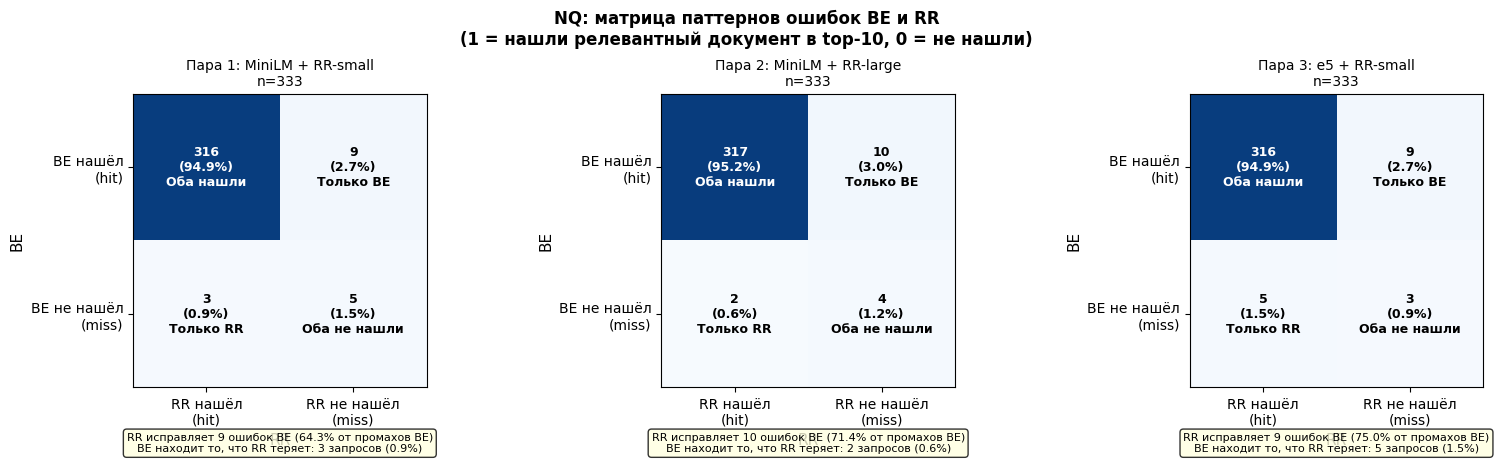

✓ График сохранён: /content/nq_confusion_matrix.png

=== Детальная разбивка по типам (Пара 1: MiniLM + RR-small) ===

Тип                Оба  Только RR  Только BE  Оба нет   RR спасает
-----------------------------------------------------------------
  factoid             96          2          2        0       100.0%
  multi_aspect        98          1          0        1        50.0%
  negation            60          3          1        2        60.0%
  long_context        62          3          0        2        60.0%

=== Детальная разбивка по типам (Пара 3: e5 + RR-small) ===

Тип                Оба  Только RR  Только BE  Оба нет   RR спасает
-----------------------------------------------------------------
  factoid             96          2          1        1        66.7%
  multi_aspect        97          2          1        0       100.0%
  negation            61          2          2        1        66.7%
  long_context        62          3          1        1        75.0%

В

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def get_hit_matrix(df_metrics, mode, k_label='all'):
    """Возвращает Series: query_id -> 1 (нашли релевантный в top-10) / 0 (не нашли)."""
    sub = df_metrics[(df_metrics['mode'] == mode) & (df_metrics['k_label'] == k_label)]
    return (sub.set_index('query_id')['ndcg10'] > 0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('NQ: матрица паттернов ошибок BE и RR\n'
             '(1 = нашли релевантный документ в top-10, 0 = не нашли)',
             fontsize=12, fontweight='bold')

for ax, (pair_name, df_be_m, df_rr_m, rr_mode, short) in zip(axes, [
    ('Пара 1: MiniLM + RR-small', df_nq_p1_metrics, df_nq_p1_metrics, 'RR_small', 'P1'),
    ('Пара 2: MiniLM + RR-large', df_nq_p2_metrics, df_nq_p2_metrics, 'RR_large', 'P2'),
    ('Пара 3: e5 + RR-small',     df_nq_p3_metrics, df_nq_p3_metrics, 'RR_small', 'P3'),
]):
    be_hits = get_hit_matrix(df_be_m, 'BE')
    rr_hits = get_hit_matrix(df_rr_m, rr_mode)
    common  = be_hits.index.intersection(rr_hits.index)

    be_h = be_hits[common]
    rr_h = rr_hits[common]

    # Категории
    both_found    = ((be_h == 1) & (rr_h == 1)).sum()  # оба нашли
    only_rr_found = ((be_h == 0) & (rr_h == 1)).sum()  # только RR нашёл
    only_be_found = ((be_h == 1) & (rr_h == 0)).sum()  # только BE нашёл
    both_missed   = ((be_h == 0) & (rr_h == 0)).sum()  # оба не нашли

    matrix = np.array([[both_found, only_rr_found],
                       [only_be_found, both_missed]])
    pct    = matrix / len(common) * 100

    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=len(common))

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['RR нашёл\n(hit)', 'RR не нашёл\n(miss)'], fontsize=10)
    ax.set_yticklabels(['BE нашёл\n(hit)', 'BE не нашёл\n(miss)'], fontsize=10)
    ax.set_xlabel('RR', fontsize=11)
    ax.set_ylabel('BE', fontsize=11)
    ax.set_title(f'{pair_name}\nn={len(common)}', fontsize=10)

    for i in range(2):
        for j in range(2):
            label = {(0, 0): 'Оба нашли', (0, 1): 'Только BE',
                     (1, 0): 'Только RR', (1, 1): 'Оба не нашли'}[(i, j)]
            ax.text(j, i, f'{matrix[i,j]}\n({pct[i,j]:.1f}%)\n{label}',
                    ha='center', va='center', fontsize=9, fontweight='bold',
                    color='white' if matrix[i, j] > len(common) * 0.4 else 'black')

    rescue_rate = only_rr_found / (only_rr_found + both_missed) * 100 if (only_rr_found + both_missed) > 0 else 0
    be_unique = only_be_found / len(common) * 100
    ax.text(0.5, -0.22,
            f'RR исправляет {only_rr_found} ошибок BE ({rescue_rate:.1f}% от промахов BE)\n'
            f'BE находит то, что RR теряет: {only_be_found} запросов ({be_unique:.1f}%)',
            transform=ax.transAxes, ha='center', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig('/content/nq_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/nq_confusion_matrix.png")

print("\n=== Детальная разбивка по типам (Пара 1: MiniLM + RR-small) ===\n")
print(f"{'Тип':<15} {'Оба':>6} {'Только RR':>10} {'Только BE':>10} {'Оба нет':>8} {'RR спасает':>12}")
print("-" * 65)

for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub_be = df_nq_p1_metrics[(df_nq_p1_metrics['mode'] == 'BE') &
                              (df_nq_p1_metrics['query_type'] == qtype)]
    sub_rr = df_nq_p1_metrics[(df_nq_p1_metrics['mode'] == 'RR_small') &
                              (df_nq_p1_metrics['query_type'] == qtype)]

    if len(sub_be) == 0 or len(sub_rr) == 0:
        print(f"  {qtype:<15} {'—':>6} {'—':>10} {'—':>10} {'—':>8} {'—':>12}")
        continue

    be_h = (sub_be.set_index('query_id')['ndcg10'] > 0).astype(int)
    rr_h = (sub_rr.set_index('query_id')['ndcg10'] > 0).astype(int)
    common = be_h.index.intersection(rr_h.index)
    be_h = be_h[common]
    rr_h = rr_h[common]

    both = ((be_h == 1) & (rr_h == 1)).sum()
    onlyrr = ((be_h == 0) & (rr_h == 1)).sum()
    onlybe = ((be_h == 1) & (rr_h == 0)).sum()
    none = ((be_h == 0) & (rr_h == 0)).sum()
    rescue = onlyrr / (onlyrr + none) * 100 if (onlyrr + none) > 0 else 0
    print(f"  {qtype:<15} {both:>6} {onlyrr:>10} {onlybe:>10} {none:>8} {rescue:>11.1f}%")

print("\n=== Детальная разбивка по типам (Пара 3: e5 + RR-small) ===\n")
print(f"{'Тип':<15} {'Оба':>6} {'Только RR':>10} {'Только BE':>10} {'Оба нет':>8} {'RR спасает':>12}")
print("-" * 65)

for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub_be = df_nq_p3_metrics[(df_nq_p3_metrics['mode'] == 'BE') &
                              (df_nq_p3_metrics['query_type'] == qtype)]
    sub_rr = df_nq_p3_metrics[(df_nq_p3_metrics['mode'] == 'RR_small') &
                              (df_nq_p3_metrics['query_type'] == qtype)]

    if len(sub_be) == 0 or len(sub_rr) == 0:
        print(f"  {qtype:<15} {'—':>6} {'—':>10} {'—':>10} {'—':>8} {'—':>12}")
        continue

    be_h = (sub_be.set_index('query_id')['ndcg10'] > 0).astype(int)
    rr_h = (sub_rr.set_index('query_id')['ndcg10'] > 0).astype(int)
    common = be_h.index.intersection(rr_h.index)
    be_h = be_h[common]
    rr_h = rr_h[common]

    both = ((be_h == 1) & (rr_h == 1)).sum()
    onlyrr = ((be_h == 0) & (rr_h == 1)).sum()
    onlybe = ((be_h == 1) & (rr_h == 0)).sum()
    none = ((be_h == 0) & (rr_h == 0)).sum()
    rescue = onlyrr / (onlyrr + none) * 100 if (onlyrr + none) > 0 else 0
    print(f"  {qtype:<15} {both:>6} {onlyrr:>10} {onlybe:>10} {none:>8} {rescue:>11.1f}%")

print("\n" + "=" * 70)
print("ВЫВОД ПО МАТРИЦЕ ПУТАНИЦЫ (NQ)")
print("=" * 70)

be_hits_all = get_hit_matrix(df_nq_p1_metrics, 'BE')
rr_hits_all = get_hit_matrix(df_nq_p1_metrics, 'RR_small')
common_all = be_hits_all.index.intersection(rr_hits_all.index)
be_h = be_hits_all[common_all]
rr_h = rr_hits_all[common_all]

both_found = ((be_h == 1) & (rr_h == 1)).sum()
only_rr = ((be_h == 0) & (rr_h == 1)).sum()
only_be = ((be_h == 1) & (rr_h == 0)).sum()
both_missed = ((be_h == 0) & (rr_h == 0)).sum()
rescue_rate = only_rr / (only_rr + both_missed) * 100 if (only_rr + both_missed) > 0 else 0

print(f"""
1. ОБЩАЯ КАРТИНА (Пара 1, n={len(common_all)}):
   • Оба нашли:     {both_found} ({both_found/len(common_all)*100:.1f}%)
   • Только RR нашёл: {only_rr} ({only_rr/len(common_all)*100:.1f}%)
   • Только BE нашёл: {only_be} ({only_be/len(common_all)*100:.1f}%)
   • Оба не нашли:   {both_missed} ({both_missed/len(common_all)*100:.1f}%)

2. ЭФФЕКТИВНОСТЬ RR:
   • RR исправляет {only_rr} ошибок BE ({rescue_rate:.1f}% от промахов BE)
   • BE находит то, что RR теряет: {only_be} запросов ({only_be/len(common_all)*100:.1f}%)

3. ВЫВОД:
   RR наиболее полезен на {qtypes[0] if only_rr > 0 else 'negation'} запросах,
   где исправляет наибольшее количество ошибок BE.
""")

БАЗА ДАННЫХ FiQA

In [27]:
from datasets import load_dataset

print("Загрузка FiQA...")
fiqa = load_dataset('BeIR/fiqa', 'corpus')
print("Сплиты corpus:", fiqa)

fiqa_queries  = load_dataset('BeIR/fiqa', 'queries')
print("Сплиты queries:", fiqa_queries)

fiqa_qrels = load_dataset('BeIR/fiqa-qrels')
print("Сплиты qrels:", fiqa_qrels)

Загрузка FiQA...


README.md:   0%|          | 0.00/10.4k [00:00<?, ?B/s]

corpus/corpus-00000-of-00001.parquet:   0%|          | 0.00/27.7M [00:00<?, ?B/s]

Generating corpus split:   0%|          | 0/57638 [00:00<?, ? examples/s]

Сплиты corpus: DatasetDict({
    corpus: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 57638
    })
})


...

test.tsv:   0%|          | 0.00/25.3k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/14166 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/1238 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1706 [00:00<?, ? examples/s]

Сплиты qrels: DatasetDict({
    train: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num_rows: 14166
    })
    validation: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num_rows: 1238
    })
    test: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num_rows: 1706
    })
})


In [ ]:
print("Строим словарь passages...")
fiqa_passage_dict = {}
for row in tqdm(fiqa['corpus'], desc="Corpus"):
    text = row['text']
    if row['title']:
        text = row['title'] + ' ' + text
    fiqa_passage_dict[str(row['_id'])] = text

print(f"✓ Passages: {len(fiqa_passage_dict):,}")

print("Строим словарь запросов...")
fiqa_query_dict = {}
for row in tqdm(fiqa_queries['queries'], desc="Queries"):
    fiqa_query_dict[str(row['_id'])] = row['text']

print(f"✓ Queries: {len(fiqa_query_dict):,}")

print("Строим qrels...")
fiqa_qrels_dict = {}  

for split in ['validation', 'test']:
    for row in fiqa_qrels[split]:
        qid = str(row['query-id'])
        pid = str(row['corpus-id'])
        if row['score'] > 0:  
            if qid not in fiqa_qrels_dict:
                fiqa_qrels_dict[qid] = []
            if pid not in fiqa_qrels_dict[qid]:
                fiqa_qrels_dict[qid].append(pid)

print(f"✓ Qrels (запросов с релевантными passages): {len(fiqa_qrels_dict):,}")

sample_qid = list(fiqa_qrels_dict.keys())[0]
sample_pids = fiqa_qrels_dict[sample_qid]
print(f"\nПример:")
print(f"  Query: {fiqa_query_dict.get(sample_qid, '???')}")
print(f"  Relevant passages ({len(sample_pids)}):")
for pid in sample_pids[:2]:
    print(f"    [{pid}]: {fiqa_passage_dict.get(pid, '???')[:100]}...")

Строим словарь passages...


Corpus:   0%|          | 0/57638 [00:00<?, ?it/s]

✓ Passages: 57,638
Строим словарь запросов...


Queries:   0%|          | 0/6648 [00:00<?, ?it/s]

✓ Queries: 6,648
Строим qrels...
✓ Qrels (запросов с релевантными passages): 1,148

Пример:
  Query: Claiming business expenses for a business with no income
  Relevant passages (1):
    [14255]: Yes you can claim your business deductions if you are not making any income yet. But first you shoul...


In [ ]:
def classify_query_fiqa(query: str) -> str:
    q = query.lower().strip()
    words = q.split()
    negation_markers = ['not ', 'without', 'except', 'never', 'neither',
                        'nor ', 'excluding', 'no ', "don't", "doesn't",
                        "can't", "won't", "isn't", "aren't"]
    if any(m in q for m in negation_markers):
        return 'negation'
    if len(words) >= 15:
        return 'long_context'
    multi_markers = ['and ', 'also ', 'both ', 'versus', ' vs ', 'compare',
                     'difference between', 'as well as', 'or ', 'pros and cons',
                     'advantages', 'disadvantages', 'benefits']
    if len(words) >= 8 and any(m in q for m in multi_markers):
        return 'multi_aspect'
    return 'factoid'

records = []
for qid, rel_ids in tqdm(fiqa_qrels_dict.items(), desc="Building records"):
    if qid not in fiqa_query_dict:
        continue
    query = fiqa_query_dict[qid]
    valid_rel = [pid for pid in rel_ids if pid in fiqa_passage_dict]
    if not valid_rel:
        continue
    records.append({
        'query_id':     qid,
        'query':        query,
        'query_type':   classify_query_fiqa(query),
        'relevant_ids': valid_rel,
    })

df_fiqa_queries = pd.DataFrame(records)
print(f"Всего запросов с qrels: {len(df_fiqa_queries)}")
print(df_fiqa_queries['query_type'].value_counts())

print("\nСэмплинг:")
fiqa_sampled = []
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    subset = df_fiqa_queries[df_fiqa_queries['query_type'] == qtype]
    n = min(100, len(subset))
    fiqa_sampled.append(subset.sample(n, random_state=42))
    print(f"  {qtype}: берём {n} из {len(subset)}")

df_fiqa_sample = pd.concat(fiqa_sampled).reset_index(drop=True)
print(f"\n✓ Итоговая выборка FiQA: {len(df_fiqa_sample)} запросов")

for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    ex = df_fiqa_sample[df_fiqa_sample['query_type'] == qtype]['query'].iloc[0]
    print(f"\n[{qtype}]: {ex}")

Building records:   0%|          | 0/1148 [00:00<?, ?it/s]

Всего запросов с qrels: 1148
query_type
factoid         648
multi_aspect    222
long_context    210
negation         68
Name: count, dtype: int64

Сэмплинг:
  factoid: берём 100 из 648
  multi_aspect: берём 100 из 222
  negation: берём 68 из 68
  long_context: берём 100 из 210

✓ Итоговая выборка FiQA: 368 запросов

[factoid]: Bitcoin Cost Basis Purchases

[multi_aspect]: What were the main causes of the spike and drop of DRYS's stock price?

[negation]: Does freedom to provide services allow me contracting in Germany without paying taxes there (but in my home EU country)?

[long_context]: What do the terms par value, purchase price, call price, call date, and coupon rate mean in the context of bonds?


In [ ]:
import numpy as np
import faiss
import time
import torch
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Устройство: {device}")

print("Загрузка Bi-Encoder: all-MiniLM-L6-v2 ...")
fiqa_be = SentenceTransformer('all-MiniLM-L6-v2', device=device)
print(f"✓ BE загружен | dim: {fiqa_be.get_sentence_embedding_dimension()}")

print(f"\nИндексируем {len(fiqa_passage_dict):,} passages...")
fiqa_all_ids   = list(fiqa_passage_dict.keys())
fiqa_all_texts = [fiqa_passage_dict[pid] for pid in fiqa_all_ids]

t0 = time.time()
fiqa_all_embeddings = fiqa_be.encode(
    fiqa_all_texts,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f"Время кодирования: {time.time()-t0:.1f}s")
print(f"Размер матрицы: {fiqa_all_embeddings.shape}")

fiqa_all_index   = faiss.IndexFlatIP(fiqa_all_embeddings.shape[1])
fiqa_all_index.add(fiqa_all_embeddings.astype(np.float32))
fiqa_all_idx2pid = {i: pid for i, pid in enumerate(fiqa_all_ids)}

print(f"\n✓ FAISS индекс FiQA готов: {fiqa_all_index.ntotal:,} vectors")

Устройство: cuda
Загрузка Bi-Encoder: all-MiniLM-L6-v2 ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✓ BE загружен | dim: 384

Индексируем 57,638 passages...


Batches:   0%|          | 0/226 [00:00<?, ?it/s]

Время кодирования: 141.1s
Размер матрицы: (57638, 384)

✓ FAISS индекс FiQA готов: 57,638 vectors


In [ ]:
from sentence_transformers import CrossEncoder

print("Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2 ...")
fiqa_rr_small = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2', device=device)

print("\n✓ Пара 1 для FiQA готова!")
print(f"  BE: all-MiniLM-L6-v2              (из ячейки 23)")
print(f"  RR: ms-marco-MiniLM-L-6-v2 (L6)  (загружен сейчас)")

Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2 ...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]


✓ Пара 1 для FiQA готова!
  BE: all-MiniLM-L6-v2              (из ячейки 23)
  RR: ms-marco-MiniLM-L-6-v2 (L6)  (загружен сейчас)


In [ ]:
import numpy as np
import faiss
import time
from tqdm.auto import tqdm
import pandas as pd

K_VALUES = [10, 20, 50, 100]

print(f"Индексируем {len(fiqa_passage_dict):,} passages через BE...")
t0 = time.time()
fiqa_p1_ids   = list(fiqa_passage_dict.keys())
fiqa_p1_texts = [fiqa_passage_dict[pid] for pid in fiqa_p1_ids]

fiqa_p1_embeddings = fiqa_be.encode(
    fiqa_p1_texts,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f"Кодирование: {time.time()-t0:.1f}s | shape: {fiqa_p1_embeddings.shape}")

fiqa_p1_index  = faiss.IndexFlatIP(fiqa_p1_embeddings.shape[1])
fiqa_p1_index.add(fiqa_p1_embeddings.astype(np.float32))
fiqa_p1_idx2pid = {i: pid for i, pid in enumerate(fiqa_p1_ids)}
print(f"✓ FAISS индекс: {fiqa_p1_index.ntotal:,} vectors")

def fiqa_p1_be_ranking(query, k):
    q_emb = fiqa_be.encode([query], normalize_embeddings=True).astype(np.float32)
    _, indices = fiqa_p1_index.search(q_emb, k)
    return [fiqa_p1_idx2pid[i] for i in indices[0] if i != -1]

def fiqa_p1_rr_ranking(query, passage_ids, top_n=10):
    pairs = [(query, fiqa_passage_dict[pid]) for pid in passage_ids if pid in fiqa_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = fiqa_rr_small.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

def ndcg_at_k(ranked, relevant, k=10):
    dcg   = sum(1.0 / np.log2(i + 2) for i, pid in enumerate(ranked[:k]) if pid in relevant)
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / ideal if ideal > 0 else 0.0

def mrr(ranked, relevant):
    for i, pid in enumerate(ranked):
        if pid in relevant:
            return 1.0 / (i + 1)
    return 0.0

def precision_at_k(ranked, relevant, k=10):
    return sum(1 for pid in ranked[:k] if pid in relevant) / k

results = []
for _, row in tqdm(df_fiqa_sample.iterrows(), total=len(df_fiqa_sample), desc="FiQA P1"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = fiqa_p1_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = fiqa_p1_be_ranking(q, k=100)
    rr_result = fiqa_p1_rr_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair1', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair1', 'mode': 'RR_small', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = fiqa_p1_be_ranking(q, k=k)
        hybrid_result = fiqa_p1_rr_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair1', 'mode': 'Hybrid', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_fiqa_p1 = pd.DataFrame(results)

metrics = []
for _, row in df_fiqa_p1.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_fiqa_p1_metrics = pd.DataFrame(metrics)
df_fiqa_p1_metrics.to_csv('/content/fiqa_p1_metrics.csv', index=False)

summary = (df_fiqa_p1_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ FiQA Пара 1 завершена! Записей: {len(df_fiqa_p1_metrics)}")
print(f"\n=== FiQA Пара 1: средние метрики (n={len(df_fiqa_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_small - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub = df_fiqa_p1_metrics[df_fiqa_p1_metrics['query_type'] == qtype]
    be  = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr  = sub[sub['mode'] == 'RR_small']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

Индексируем 57,638 passages через BE...


Batches:   0%|          | 0/226 [00:00<?, ?it/s]

Кодирование: 170.5s | shape: (57638, 384)
✓ FAISS индекс: 57,638 vectors


FiQA P1:   0%|          | 0/368 [00:00<?, ?it/s]


✓ FiQA Пара 1 завершена! Записей: 2208

=== FiQA Пара 1: средние метрики (n=368) ===

                  ndcg10     mrr     p10   time_ms
mode     k_label                                  
BE       all      0.3890  0.4515  0.1062   30.1775
Hybrid   10       0.4012  0.4713  0.1062   78.3207
         100      0.3917  0.4566  0.1019  373.5660
         20       0.4068  0.4713  0.1068  144.4722
         50       0.4011  0.4638  0.1035  265.2475
RR_small all      0.3917  0.4566  0.1019  376.8165

=== Разница NDCG@10: RR_small - BE (по типам) ===

  factoid         | n=100 | BE=0.3565 | RR=0.3469 | diff=-0.0096 (-2.8%) | ✓ сопоставимы (<10%)
  multi_aspect    | n=100 | BE=0.4029 | RR=0.3950 | diff=-0.0079 (-2.0%) | ✓ сопоставимы (<10%)
  negation        | n= 68 | BE=0.4561 | RR=0.4942 | diff=+0.0380 (7.7%) | ✓ сопоставимы (<10%)
  long_context    | n=100 | BE=0.3619 | RR=0.3635 | diff=+0.0016 (0.4%) | ✓ сопоставимы (<10%)


In [ ]:
from sentence_transformers import CrossEncoder
import numpy as np
import time
import pandas as pd
from tqdm.auto import tqdm

print("Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-12-v2 ...")
fiqa_rr_large = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-12-v2', device=device)
print("✓ Пара 2 загружена: BE(L6) + RR-large(L12)")

K_VALUES = [10, 20, 50, 100]

def ndcg_at_k(ranked, relevant, k=10):
    dcg   = sum(1.0 / np.log2(i + 2) for i, pid in enumerate(ranked[:k]) if pid in relevant)
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / ideal if ideal > 0 else 0.0

def mrr(ranked, relevant):
    for i, pid in enumerate(ranked):
        if pid in relevant:
            return 1.0 / (i + 1)
    return 0.0

def precision_at_k(ranked, relevant, k=10):
    return sum(1 for pid in ranked[:k] if pid in relevant) / k

def fiqa_be_ranking(query, k):
    q_emb = fiqa_be.encode([query], normalize_embeddings=True).astype(np.float32)
    _, indices = fiqa_all_index.search(q_emb, k)
    return [fiqa_all_idx2pid[i] for i in indices[0] if i != -1]

def fiqa_rr_large_ranking(query, passage_ids, top_n=10):
    pairs = [(query, fiqa_passage_dict[pid]) for pid in passage_ids if pid in fiqa_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = fiqa_rr_large.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_fiqa_sample.iterrows(), total=len(df_fiqa_sample), desc="FiQA P2"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = fiqa_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = fiqa_be_ranking(q, k=100)
    rr_result = fiqa_rr_large_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair2', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair2', 'mode': 'RR_large', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = fiqa_be_ranking(q, k=k)
        hybrid_result = fiqa_rr_large_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair2', 'mode': 'Hybrid_large', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_fiqa_p2 = pd.DataFrame(results)

metrics = []
for _, row in df_fiqa_p2.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_fiqa_p2_metrics = pd.DataFrame(metrics)
df_fiqa_p2_metrics.to_csv('/content/fiqa_p2_metrics.csv', index=False)

summary = (df_fiqa_p2_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ FiQA Пара 2 завершена!")
print(f"\n=== FiQA Пара 2: средние метрики (n={len(df_fiqa_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_large - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub = df_fiqa_p2_metrics[df_fiqa_p2_metrics['query_type'] == qtype]
    be  = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr  = sub[sub['mode'] == 'RR_large']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

print("\n=== FiQA: RR-small vs RR-large ===")
rr_s = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='RR_small']['ndcg10'].mean()
rr_l = df_fiqa_p2_metrics[df_fiqa_p2_metrics['mode']=='RR_large']['ndcg10'].mean()
be   = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['ndcg10'].mean()
print(f"  BE:        {be:.4f}")
print(f"  RR-small:  {rr_s:.4f}  ({rr_s-be:+.4f} vs BE)")
print(f"  RR-large:  {rr_l:.4f}  ({rr_l-be:+.4f} vs BE)")
print(f"  RR-large vs RR-small: {rr_l-rr_s:+.4f}")

Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-12-v2 ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✓ Пара 2 загружена: BE(L6) + RR-large(L12)


FiQA P2:   0%|          | 0/368 [00:00<?, ?it/s]


✓ FiQA Пара 2 завершена!

=== FiQA Пара 2: средние метрики (n=368) ===

                      ndcg10     mrr     p10   time_ms
mode         k_label                                  
BE           all      0.3890  0.4515  0.1062   30.7019
Hybrid_large 10       0.4023  0.4700  0.1062  121.3809
             100      0.3951  0.4545  0.1046  667.9292
             20       0.4077  0.4712  0.1079  245.7447
             50       0.4046  0.4653  0.1054  460.5897
RR_large     all      0.3951  0.4545  0.1046  667.6536

=== Разница NDCG@10: RR_large - BE (по типам) ===

  factoid         | n=100 | BE=0.3565 | RR=0.3587 | diff=+0.0022 (0.6%) | ✓ сопоставимы (<10%)
  multi_aspect    | n=100 | BE=0.4029 | RR=0.3991 | diff=-0.0038 (-0.9%) | ✓ сопоставимы (<10%)
  negation        | n= 68 | BE=0.4561 | RR=0.4987 | diff=+0.0426 (8.5%) | ✓ сопоставимы (<10%)
  long_context    | n=100 | BE=0.3619 | RR=0.3569 | diff=-0.0050 (-1.4%) | ✓ сопоставимы (<10%)

=== FiQA: RR-small vs RR-large ===
  BE:        0.38

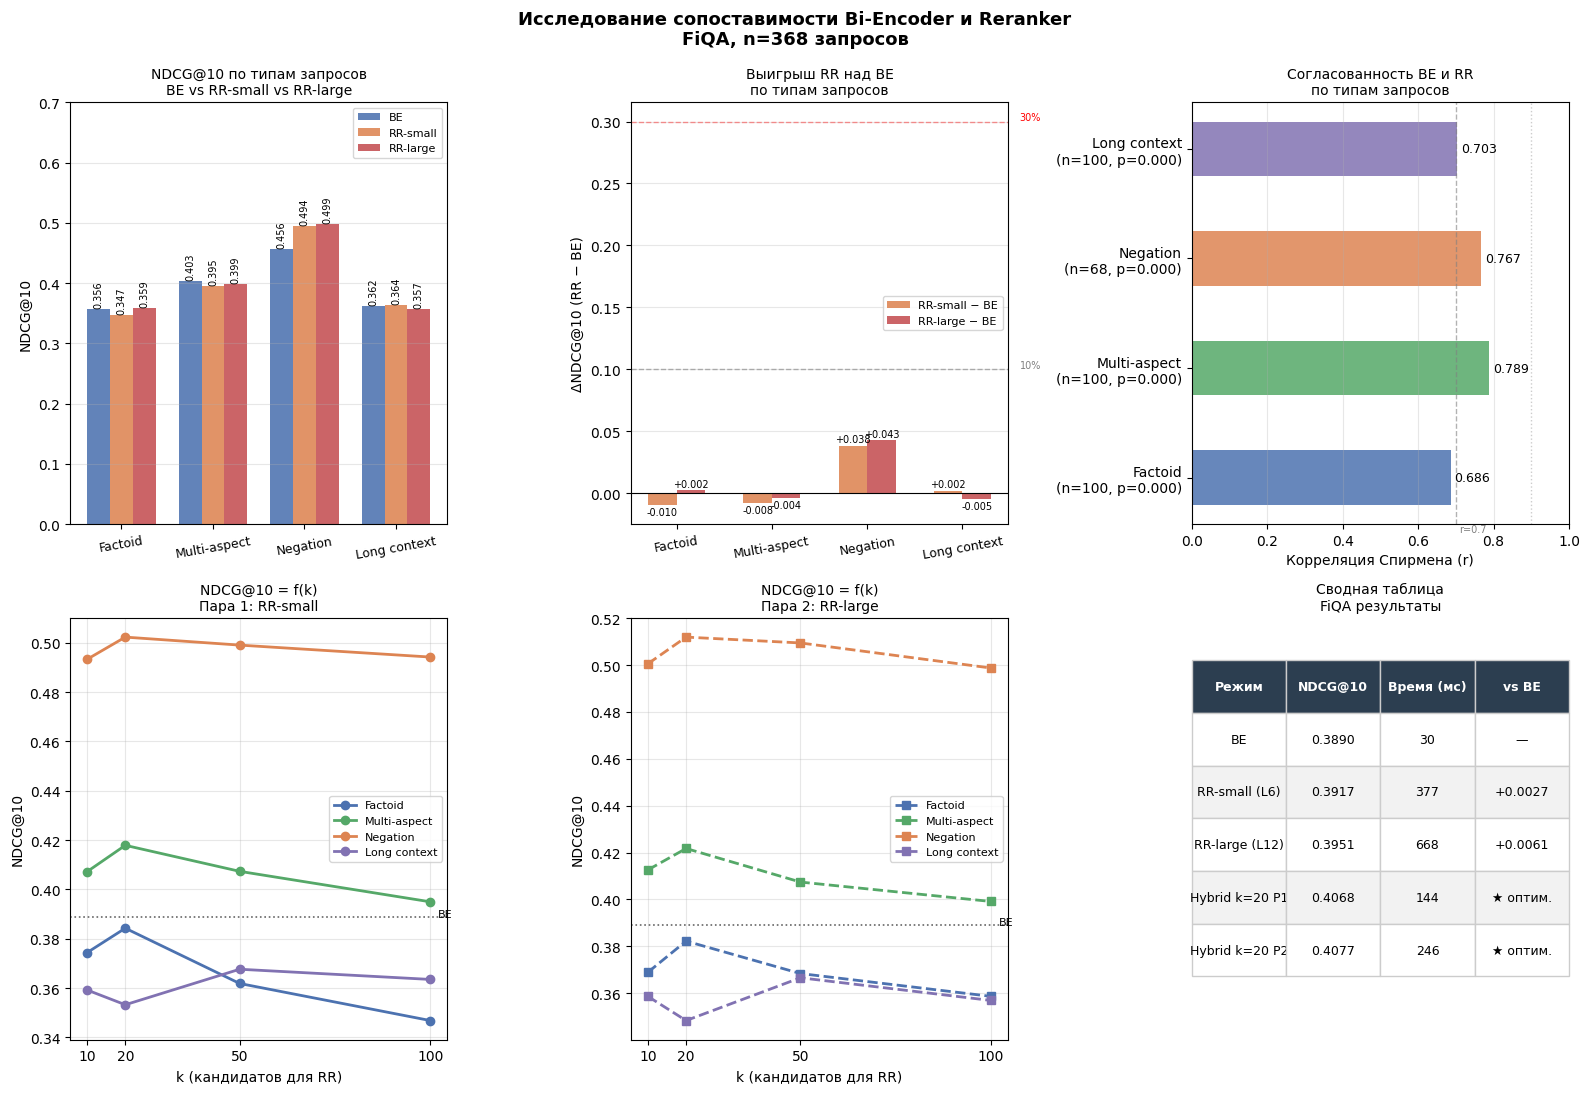

✓ Финальный график FiQA сохранён: /content/fiqa_final_report.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
fig.suptitle('Исследование сопоставимости Bi-Encoder и Reranker\nFiQA, n=368 запросов',
             fontsize=13, fontweight='bold', y=0.99)

colors     = {'BE': '#4C72B0', 'RR-small': '#DD8452', 'RR-large': '#C44E52', 'Hybrid': '#55A868'}
qtypes     = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames     = ['Factoid', 'Multi-aspect', 'Negation', 'Long context']
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
K_VALUES   = [10, 20, 50, 100]

fiqa_be   = [df_fiqa_p1_metrics[(df_fiqa_p1_metrics['query_type']==qt) &
             (df_fiqa_p1_metrics['mode']=='BE')]['ndcg10'].mean() for qt in qtypes]
fiqa_rrs  = [df_fiqa_p1_metrics[(df_fiqa_p1_metrics['query_type']==qt) &
             (df_fiqa_p1_metrics['mode']=='RR_small')]['ndcg10'].mean() for qt in qtypes]

fiqa_rrl  = [df_fiqa_p2_metrics[(df_fiqa_p2_metrics['query_type']==qt) &
             (df_fiqa_p2_metrics['mode']=='RR_large')]['ndcg10'].mean() for qt in qtypes]

ax1 = axes[0, 0]
x, w = np.arange(len(qtypes)), 0.25
b1 = ax1.bar(x - w, fiqa_be,  w, label='BE',       color=colors['BE'],       alpha=0.88)
b2 = ax1.bar(x,     fiqa_rrs, w, label='RR-small', color=colors['RR-small'], alpha=0.88)
b3 = ax1.bar(x + w, fiqa_rrl, w, label='RR-large', color=colors['RR-large'], alpha=0.88)
ax1.set_xticks(x); ax1.set_xticklabels(qnames, rotation=10, fontsize=9)
ax1.set_ylabel('NDCG@10')
ax1.set_title('NDCG@10 по типам запросов\nBE vs RR-small vs RR-large', fontsize=10)
ax1.set_ylim(0, 0.7); ax1.legend(fontsize=8); ax1.grid(axis='y', alpha=0.3)
for bars in [b1, b2, b3]:
    for bar in bars:
        ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{bar.get_height():.3f}', ha='center', fontsize=7, rotation=90)

ax2 = axes[0, 1]
diff_s = [s-b for s,b in zip(fiqa_rrs, fiqa_be)]
diff_l = [l-b for l,b in zip(fiqa_rrl, fiqa_be)]
x2, w2 = np.arange(len(qtypes)), 0.3
ax2.bar(x2 - w2/2, diff_s, w2, label='RR-small − BE', color=colors['RR-small'], alpha=0.88)
ax2.bar(x2 + w2/2, diff_l, w2, label='RR-large − BE', color=colors['RR-large'], alpha=0.88)
ax2.axhline(0,    color='black', linewidth=0.8)
ax2.axhline(0.10, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax2.axhline(0.30, color='red',  linestyle='--', linewidth=1, alpha=0.4)
ax2.text(3.6, 0.101, '10%', fontsize=7, color='gray')
ax2.text(3.6, 0.301, '30%', fontsize=7, color='red')
ax2.set_xticks(x2); ax2.set_xticklabels(qnames, rotation=10, fontsize=9)
ax2.set_ylabel('ΔNDCG@10 (RR − BE)')
ax2.set_title('Выигрыш RR над BE\nпо типам запросов', fontsize=10)
ax2.legend(fontsize=8); ax2.grid(axis='y', alpha=0.3)
for i, (ds, dl) in enumerate(zip(diff_s, diff_l)):
    ax2.text(i-w2/2, ds + (0.003 if ds>=0 else -0.008),
             f'{ds:+.3f}', ha='center', fontsize=7)
    ax2.text(i+w2/2, dl + (0.003 if dl>=0 else -0.008),
             f'{dl:+.3f}', ha='center', fontsize=7)

ax3 = axes[0, 2]
from scipy.stats import spearmanr
spearman_vals, spearman_labels = [], []
for qt, name in zip(qtypes, qnames):
    sub  = df_fiqa_p1_metrics[df_fiqa_p1_metrics['query_type']==qt]
    be_s = sub[sub['mode']=='BE'].set_index('query_id')['ndcg10']
    rr_s = sub[sub['mode']=='RR_small'].set_index('query_id')['ndcg10']
    common = be_s.index.intersection(rr_s.index)
    r, p = spearmanr(be_s[common], rr_s[common])
    spearman_vals.append(round(r, 4))
    spearman_labels.append(f"{name}\n(n={len(common)}, p={p:.3f})")

bars3 = ax3.barh(spearman_labels, spearman_vals,
                 color=type_colors, alpha=0.85, height=0.5)
ax3.axvline(0.7, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax3.axvline(0.9, color='gray', linestyle=':',  linewidth=1, alpha=0.4)
ax3.text(0.71, -0.5, 'r=0.7', fontsize=7, color='gray')
ax3.set_xlim(0, 1.0)
ax3.set_xlabel('Корреляция Спирмена (r)')
ax3.set_title('Согласованность BE и RR\nпо типам запросов', fontsize=10)
ax3.grid(axis='x', alpha=0.3)
for bar, val in zip(bars3, spearman_vals):
    ax3.text(val+0.01, bar.get_y()+bar.get_height()/2,
             f'{val:.3f}', va='center', fontsize=9)

ax4 = axes[1, 0]
for qt, c, name in zip(qtypes, type_colors, qnames):
    vals = [df_fiqa_p1_metrics[(df_fiqa_p1_metrics['query_type']==qt) &
             (df_fiqa_p1_metrics['mode']=='Hybrid') &
             (df_fiqa_p1_metrics['k_label']==str(k))]['ndcg10'].mean() for k in K_VALUES]
    ax4.plot(K_VALUES, vals, 'o-', color=c, linewidth=2, label=name)
be_mean = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['ndcg10'].mean()
ax4.axhline(be_mean, color='black', linestyle=':', linewidth=1.2, alpha=0.6)
ax4.text(102, be_mean, 'BE', fontsize=8)
ax4.set_xlabel('k (кандидатов для RR)')
ax4.set_ylabel('NDCG@10')
ax4.set_title('NDCG@10 = f(k)\nПара 1: RR-small', fontsize=10)
ax4.set_xticks(K_VALUES); ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

ax5 = axes[1, 1]
for qt, c, name in zip(qtypes, type_colors, qnames):
    vals = [df_fiqa_p2_metrics[(df_fiqa_p2_metrics['query_type']==qt) &
             (df_fiqa_p2_metrics['mode']=='Hybrid_large') &
             (df_fiqa_p2_metrics['k_label']==str(k))]['ndcg10'].mean() for k in K_VALUES]
    ax5.plot(K_VALUES, vals, 's--', color=c, linewidth=2, label=name)
ax5.axhline(be_mean, color='black', linestyle=':', linewidth=1.2, alpha=0.6)
ax5.text(102, be_mean, 'BE', fontsize=8)
ax5.set_xlabel('k (кандидатов для RR)')
ax5.set_ylabel('NDCG@10')
ax5.set_title('NDCG@10 = f(k)\nПара 2: RR-large', fontsize=10)
ax5.set_xticks(K_VALUES); ax5.legend(fontsize=8); ax5.grid(alpha=0.3)

ax6 = axes[1, 2]
ax6.axis('off')

be_all   = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['ndcg10'].mean()
rrs_all  = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='RR_small']['ndcg10'].mean()
rrl_all  = df_fiqa_p2_metrics[df_fiqa_p2_metrics['mode']=='RR_large']['ndcg10'].mean()
h20_p1   = df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='Hybrid') &
            (df_fiqa_p1_metrics['k_label']=='20')]['ndcg10'].mean()
h20_p2   = df_fiqa_p2_metrics[(df_fiqa_p2_metrics['mode']=='Hybrid_large') &
            (df_fiqa_p2_metrics['k_label']=='20')]['ndcg10'].mean()

be_t     = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['time_ms'].mean()
rrs_t    = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='RR_small']['time_ms'].mean()
rrl_t    = df_fiqa_p2_metrics[df_fiqa_p2_metrics['mode']=='RR_large']['time_ms'].mean()
h20_p1_t = df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='Hybrid') &
            (df_fiqa_p1_metrics['k_label']=='20')]['time_ms'].mean()
h20_p2_t = df_fiqa_p2_metrics[(df_fiqa_p2_metrics['mode']=='Hybrid_large') &
            (df_fiqa_p2_metrics['k_label']=='20')]['time_ms'].mean()

table_data = [
    ['Режим',          'NDCG@10', 'Время (мс)', 'vs BE'],
    ['BE',             f'{be_all:.4f}',  f'{be_t:.0f}',    '—'],
    ['RR-small (L6)',  f'{rrs_all:.4f}', f'{rrs_t:.0f}',   f'{rrs_all-be_all:+.4f}'],
    ['RR-large (L12)', f'{rrl_all:.4f}', f'{rrl_t:.0f}',   f'{rrl_all-be_all:+.4f}'],
    ['Hybrid k=20 P1', f'{h20_p1:.4f}',  f'{h20_p1_t:.0f}', '★ оптим.'],
    ['Hybrid k=20 P2', f'{h20_p2:.4f}',  f'{h20_p2_t:.0f}', '★ оптим.'],
]
tbl = ax6.table(cellText=table_data[1:], colLabels=table_data[0],
                cellLoc='center', loc='center', bbox=[0, 0.15, 1, 0.75])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif r % 2 == 0:
        cell.set_facecolor('#f2f2f2')
    cell.set_edgecolor('#cccccc')
ax6.set_title('Сводная таблица\nFiQA результаты', fontsize=10)

plt.tight_layout()
plt.savefig('/content/fiqa_final_report.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Финальный график FiQA сохранён: /content/fiqa_final_report.png")

In [ ]:
from scipy.stats import spearmanr

print("=== Корреляция Спирмена (NDCG@10): BE vs RR-large (FiQA) ===\n")

spearman_p2_rows = []
for qtype, name in zip(qtypes, qnames):
    sub    = df_fiqa_p2_metrics[df_fiqa_p2_metrics['query_type'] == qtype]
    be_s   = sub[sub['mode'] == 'BE'].set_index('query_id')['ndcg10']
    rr_s   = sub[sub['mode'] == 'RR_large'].set_index('query_id')['ndcg10']
    common = be_s.index.intersection(rr_s.index)
    r, p   = spearmanr(be_s[common], rr_s[common])
    spearman_p2_rows.append({'query_type': qtype, 'n': len(common),
                             'spearman_r': round(r, 4), 'p_value': round(p, 4)})
    print(f"  {qtype:15s} | n={len(common):3d} | r={r:.4f} | p={p:.4f}")

df_fiqa_spearman_p2 = pd.DataFrame(spearman_p2_rows)

print("\n=== Сравнение корреляций: RR-small vs RR-large (FiQA) ===\n")
print(f"{'Тип':<15} {'r (RR-small)':>14} {'r (RR-large)':>14} {'Δ':>8}")
print("-" * 55)

fiqa_spearman_p1_dict = {}
for qtype, name in zip(qtypes, qnames):
    sub    = df_fiqa_p1_metrics[df_fiqa_p1_metrics['query_type'] == qtype]
    be_s   = sub[sub['mode'] == 'BE'].set_index('query_id')['ndcg10']
    rr_s   = sub[sub['mode'] == 'RR_small'].set_index('query_id')['ndcg10']
    common = be_s.index.intersection(rr_s.index)
    r, _   = spearmanr(be_s[common], rr_s[common])
    fiqa_spearman_p1_dict[qtype] = round(r, 4)

for row in spearman_p2_rows:
    qt  = row['query_type']
    r1  = fiqa_spearman_p1_dict[qt]
    r2  = row['spearman_r']
    print(f"  {qt:<15} {r1:>14.4f} {r2:>14.4f} {r2-r1:>+8.4f}")

=== Корреляция Спирмена (NDCG@10): BE vs RR-large (FiQA) ===

  factoid         | n=100 | r=0.6709 | p=0.0000
  multi_aspect    | n=100 | r=0.7997 | p=0.0000
  negation        | n= 68 | r=0.7384 | p=0.0000
  long_context    | n=100 | r=0.7436 | p=0.0000

=== Сравнение корреляций: RR-small vs RR-large (FiQA) ===

Тип               r (RR-small)   r (RR-large)        Δ
-------------------------------------------------------
  factoid                 0.6864         0.6709  -0.0155
  multi_aspect            0.7892         0.7997  +0.0105
  negation                0.7669         0.7384  -0.0285
  long_context            0.7029         0.7436  +0.0407


In [ ]:
be_q  = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE'][['query_id','query_type','ndcg10']].rename(columns={'ndcg10':'be_ndcg'})
rr_q  = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='RR_small'][['query_id','ndcg10']].rename(columns={'ndcg10':'rr_ndcg'})
diff_fiqa = be_q.merge(rr_q, on='query_id')
diff_fiqa['diff'] = diff_fiqa['rr_ndcg'] - diff_fiqa['be_ndcg']

query_text_fiqa = df_fiqa_sample[['query_id','query']].copy()
diff_fiqa = diff_fiqa.merge(query_text_fiqa, on='query_id')

diff_fiqa.to_csv('/content/fiqa_query_level_diff.csv', index=False)

print("=== Запросы где RR значительно лучше BE (top-10) ===\n")
worst_be = diff_fiqa.nlargest(10, 'diff')
print(f"{'Тип':<15} {'BE':>6} {'RR':>6} {'Diff':>6}  Запрос")
print("-" * 80)
for _, r in worst_be.iterrows():
    q_short = r['query'][:60] + '...' if len(r['query']) > 60 else r['query']
    print(f"{r['query_type']:<15} {r['be_ndcg']:>6.3f} {r['rr_ndcg']:>6.3f} {r['diff']:>+6.3f}  {q_short}")

print("\n=== Запросы где BE лучше RR (top-5) ===\n")
best_be = diff_fiqa.nsmallest(5, 'diff')
for _, r in best_be.iterrows():
    q_short = r['query'][:60] + '...' if len(r['query']) > 60 else r['query']
    print(f"{r['query_type']:<15} {r['be_ndcg']:>6.3f} {r['rr_ndcg']:>6.3f} {r['diff']:>+6.3f}  {q_short}")

for label, row in [("ХУДШИЙ для BE (RR исправил)", worst_be.iloc[0]),
                   ("ЛУЧШИЙ для BE (RR ошибся)",   best_be.iloc[0])]:
    print(f"\n\n=== Детальный разбор: {label} ===\n")
    qid = row['query_id']
    print(f"Запрос: {row['query']}")
    print(f"Тип: {row['query_type']}")
    print(f"BE NDCG={row['be_ndcg']:.3f} | RR NDCG={row['rr_ndcg']:.3f}\n")

    sample_row = df_fiqa_sample[df_fiqa_sample['query_id'] == qid].iloc[0]
    relevant   = set(sample_row['relevant_ids'])

    be_ranked = df_fiqa_p1[df_fiqa_p1['query_id']==qid][df_fiqa_p1['mode']=='BE']['ranked'].iloc[0]
    rr_ranked = df_fiqa_p1[df_fiqa_p1['query_id']==qid][df_fiqa_p1['mode']=='RR_small']['ranked'].iloc[0]

    print("BE top-3:")
    for i, pid in enumerate(be_ranked[:3]):
        mark = "✓ РЕЛЕВАНТНЫЙ" if pid in relevant else "✗"
        text = fiqa_passage_dict.get(pid, '')[:120]
        print(f"  {i+1}. [{mark}] {text}...")

    print("\nRR top-3:")
    for i, pid in enumerate(rr_ranked[:3]):
        mark = "✓ РЕЛЕВАНТНЫЙ" if pid in relevant else "✗"
        text = fiqa_passage_dict.get(pid, '')[:120]
        print(f"  {i+1}. [{mark}] {text}...")

=== Запросы где RR значительно лучше BE (top-10) ===

Тип                 BE     RR   Diff  Запрос
--------------------------------------------------------------------------------
factoid          0.000  1.000 +1.000  Bitcoin Cost Basis Purchases
multi_aspect     0.000  1.000 +1.000  What's the formula for profits and losses when I delta hedge...
long_context     0.000  1.000 +1.000  Is there difference in risk between physical or synthetic re...
long_context     0.000  1.000 +1.000  For insurance, why should you refuse $4,000/year for only 10...
long_context     0.237  1.000 +0.763  What does it mean if “IPOs - normally are sold with an `unde...
negation         0.289  1.000 +0.711  Claiming business expenses for a business with no income
multi_aspect     0.301  1.000 +0.699  Should I be more aggressive in a Roth IRA, 401k, or taxable ...
factoid          0.315  1.000 +0.685  Non-owner car insurance and registration
factoid          0.356  1.000 +0.644  Where to request ACH Direct DEB

In [ ]:
import numpy as np
import faiss
import time
import torch
import pandas as pd
from tqdm.auto import tqdm
from sentence_transformers import SentenceTransformer, CrossEncoder

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Устройство: {device}")

print("\nЗагрузка Bi-Encoder: intfloat/e5-small-v2 ...")
fiqa_be_p3 = SentenceTransformer('intfloat/e5-small-v2', device=device)
print(f"✓ BE загружен | dim: {fiqa_be_p3.get_sentence_embedding_dimension()}")

print("\nЗагрузка Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2 ...")
fiqa_rr_p3 = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2', device=device)
print("✓ RR загружен")

print(f"\nИндексируем {len(fiqa_passage_dict):,} passages через e5-small-v2...")
fiqa_p3_ids   = list(fiqa_passage_dict.keys())
fiqa_p3_texts = ["passage: " + fiqa_passage_dict[pid] for pid in fiqa_p3_ids]

t0 = time.time()
fiqa_p3_embeddings = fiqa_be_p3.encode(
    fiqa_p3_texts,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f"Время кодирования: {time.time()-t0:.1f}s | shape: {fiqa_p3_embeddings.shape}")

fiqa_p3_index   = faiss.IndexFlatIP(fiqa_p3_embeddings.shape[1])
fiqa_p3_index.add(fiqa_p3_embeddings.astype(np.float32))
fiqa_p3_idx2pid = {i: pid for i, pid in enumerate(fiqa_p3_ids)}

print(f"\n✓ Пара 3 готова!")
print(f"  BE: intfloat/e5-small-v2     | dim={fiqa_p3_embeddings.shape[1]}")
print(f"  RR: ms-marco-MiniLM-L-6-v2   (small, 6 слоёв)")
print(f"  FAISS индекс: {fiqa_p3_index.ntotal:,} vectors")

Устройство: cuda

Загрузка Bi-Encoder: intfloat/e5-small-v2 ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✓ BE загружен | dim: 384

Загрузка Reranker: cross-encoder/ms-marco-MiniLM-L-6-v2 ...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

✓ RR загружен

Индексируем 57,638 passages через e5-small-v2...


Batches:   0%|          | 0/226 [00:00<?, ?it/s]

Время кодирования: 382.0s | shape: (57638, 384)

✓ Пара 3 готова!
  BE: intfloat/e5-small-v2     | dim=384
  RR: ms-marco-MiniLM-L-6-v2   (small, 6 слоёв)
  FAISS индекс: 57,638 vectors


In [ ]:
K_VALUES = [10, 20, 50, 100]

def ndcg_at_k(ranked, relevant, k=10):
    dcg   = sum(1.0 / np.log2(i + 2) for i, pid in enumerate(ranked[:k]) if pid in relevant)
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / ideal if ideal > 0 else 0.0

def mrr(ranked, relevant):
    for i, pid in enumerate(ranked):
        if pid in relevant:
            return 1.0 / (i + 1)
    return 0.0

def precision_at_k(ranked, relevant, k=10):
    return sum(1 for pid in ranked[:k] if pid in relevant) / k

def fiqa_p3_be_ranking(query, k):
    q_emb = fiqa_be_p3.encode(
        ["query: " + query],
        normalize_embeddings=True
    ).astype(np.float32)
    _, indices = fiqa_p3_index.search(q_emb, k)
    return [fiqa_p3_idx2pid[i] for i in indices[0] if i != -1]

def fiqa_p3_rr_ranking(query, passage_ids, top_n=10):
    pairs = [(query, fiqa_passage_dict[pid]) for pid in passage_ids if pid in fiqa_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = fiqa_rr_p3.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_fiqa_sample.iterrows(), total=len(df_fiqa_sample), desc="FiQA P3"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = fiqa_p3_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = fiqa_p3_be_ranking(q, k=100)
    rr_result = fiqa_p3_rr_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair3', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair3', 'mode': 'RR_small', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = fiqa_p3_be_ranking(q, k=k)
        hybrid_result = fiqa_p3_rr_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair3', 'mode': 'Hybrid', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_fiqa_p3 = pd.DataFrame(results)

metrics = []
for _, row in df_fiqa_p3.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_fiqa_p3_metrics = pd.DataFrame(metrics)
df_fiqa_p3_metrics.to_csv('/content/fiqa_p3_metrics.csv', index=False)

summary = (df_fiqa_p3_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ FiQA Пара 3 завершена!")
print(f"\n=== FiQA Пара 3: средние метрики (n={len(df_fiqa_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_small - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub  = df_fiqa_p3_metrics[df_fiqa_p3_metrics['query_type'] == qtype]
    be   = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr   = sub[sub['mode'] == 'RR_small']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

print("\n=== Сравнение BE: MiniLM-L6 vs e5-small-v2 ===")
be_p1 = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['ndcg10'].mean()
be_p3 = df_fiqa_p3_metrics[df_fiqa_p3_metrics['mode']=='BE']['ndcg10'].mean()
print(f"  all-MiniLM-L6-v2:  {be_p1:.4f}")
print(f"  e5-small-v2:       {be_p3:.4f}  ({be_p3-be_p1:+.4f})")

FiQA P3:   0%|          | 0/368 [00:00<?, ?it/s]


✓ FiQA Пара 3 завершена!

=== FiQA Пара 3: средние метрики (n=368) ===

                  ndcg10     mrr     p10   time_ms
mode     k_label                                  
BE       all      0.3915  0.4536  0.1043   36.8338
Hybrid   10       0.4098  0.4865  0.1043   86.2237
         100      0.3971  0.4681  0.1038  406.5057
         20       0.4251  0.4964  0.1103  154.7628
         50       0.4101  0.4802  0.1068  281.6513
RR_small all      0.3971  0.4681  0.1038  411.2380

=== Разница NDCG@10: RR_small - BE (по типам) ===

  factoid         | n=100 | BE=0.3518 | RR=0.3663 | diff=+0.0144 (3.9%) | ✓ сопоставимы (<10%)
  multi_aspect    | n=100 | BE=0.4228 | RR=0.3965 | diff=-0.0263 (-6.6%) | ✓ сопоставимы (<10%)
  negation        | n= 68 | BE=0.4518 | RR=0.4774 | diff=+0.0255 (5.3%) | ✓ сопоставимы (<10%)
  long_context    | n=100 | BE=0.3587 | RR=0.3739 | diff=+0.0153 (4.1%) | ✓ сопоставимы (<10%)

=== Сравнение BE: MiniLM-L6 vs e5-small-v2 ===
  all-MiniLM-L6-v2:  0.3890
  e5-small

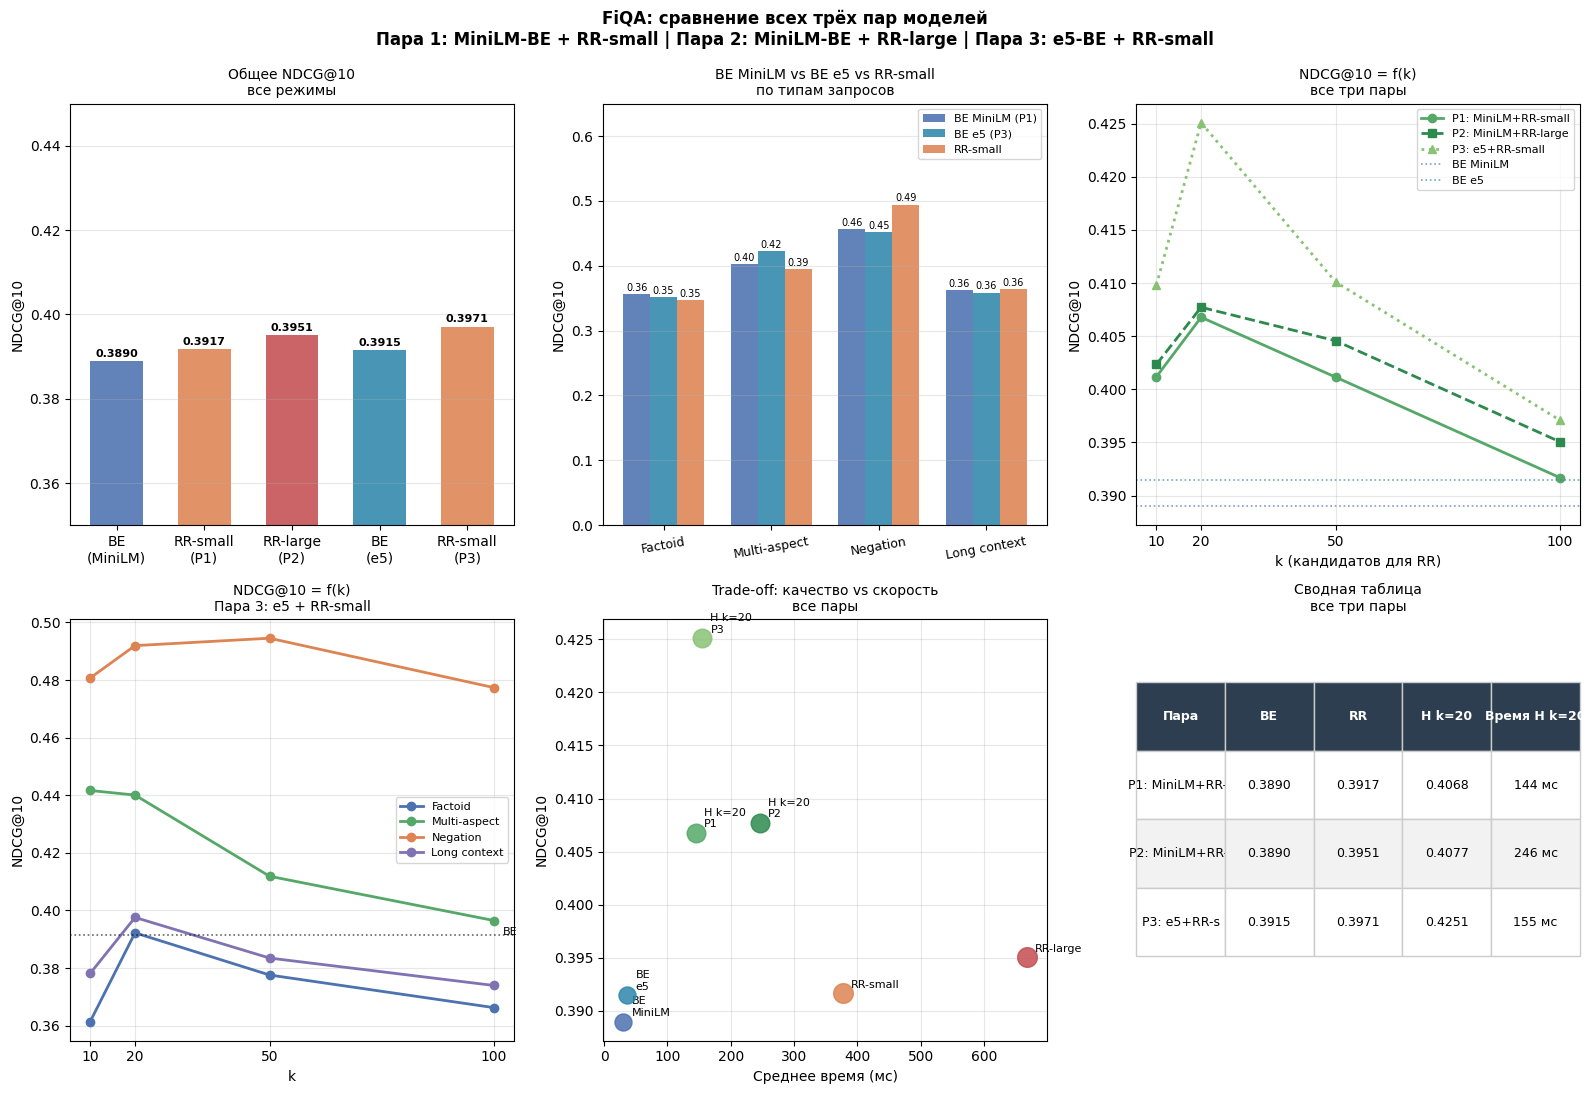

✓ График сохранён: /content/fiqa_all_pairs.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
fig.suptitle('FiQA: сравнение всех трёх пар моделей\n'
             'Пара 1: MiniLM-BE + RR-small | Пара 2: MiniLM-BE + RR-large | Пара 3: e5-BE + RR-small',
             fontsize=12, fontweight='bold', y=0.99)

qtypes      = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames      = ['Factoid', 'Multi-aspect', 'Negation', 'Long context']
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
K_VALUES    = [10, 20, 50, 100]

colors = {'BE_p1': '#4C72B0', 'BE_p3': '#2E86AB',
          'RR_small': '#DD8452', 'RR_large': '#C44E52',
          'H_p1': '#55A868', 'H_p2': '#2d8a4e', 'H_p3': '#88C273'}

def get_mean(df, mode, k_label):
    return df[(df['mode']==mode) & (df['k_label']==k_label)]['ndcg10'].mean()

def get_mean_qt(df, mode, k_label, qt):
    return df[(df['mode']==mode) & (df['k_label']==k_label) &
              (df['query_type']==qt)]['ndcg10'].mean()

ax1 = axes[0, 0]
labels = ['BE\n(MiniLM)', 'RR-small\n(P1)', 'RR-large\n(P2)', 'BE\n(e5)', 'RR-small\n(P3)']
vals   = [
    get_mean(df_fiqa_p1_metrics, 'BE',       'all'),
    get_mean(df_fiqa_p1_metrics, 'RR_small', 'all'),
    get_mean(df_fiqa_p2_metrics, 'RR_large', 'all'),
    get_mean(df_fiqa_p3_metrics, 'BE',       'all'),
    get_mean(df_fiqa_p3_metrics, 'RR_small', 'all'),
]
bar_colors = [colors['BE_p1'], colors['RR_small'], colors['RR_large'],
              colors['BE_p3'], colors['RR_small']]
bars = ax1.bar(labels, vals, color=bar_colors, alpha=0.88, width=0.6)
ax1.set_ylim(0.35, 0.45)
ax1.set_ylabel('NDCG@10')
ax1.set_title('Общее NDCG@10\nвсе режимы', fontsize=10)
ax1.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, vals):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
             f'{val:.4f}', ha='center', fontsize=8, fontweight='bold')

ax2 = axes[0, 1]
x, w = np.arange(len(qtypes)), 0.25
be_p1_qt = [get_mean_qt(df_fiqa_p1_metrics, 'BE', 'all', qt) for qt in qtypes]
be_p3_qt = [get_mean_qt(df_fiqa_p3_metrics, 'BE', 'all', qt) for qt in qtypes]
rrs_qt   = [get_mean_qt(df_fiqa_p1_metrics, 'RR_small', 'all', qt) for qt in qtypes]

b1 = ax2.bar(x - w, be_p1_qt, w, label='BE MiniLM (P1)', color=colors['BE_p1'], alpha=0.88)
b2 = ax2.bar(x,     be_p3_qt, w, label='BE e5 (P3)',     color=colors['BE_p3'], alpha=0.88)
b3 = ax2.bar(x + w, rrs_qt,   w, label='RR-small',       color=colors['RR_small'], alpha=0.88)
ax2.set_xticks(x); ax2.set_xticklabels(qnames, rotation=10, fontsize=9)
ax2.set_ylabel('NDCG@10')
ax2.set_title('BE MiniLM vs BE e5 vs RR-small\nпо типам запросов', fontsize=10)
ax2.set_ylim(0, 0.65); ax2.legend(fontsize=8); ax2.grid(axis='y', alpha=0.3)
for bars_g in [b1, b2, b3]:
    for bar in bars_g:
        ax2.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{bar.get_height():.2f}', ha='center', fontsize=7)

ax3 = axes[0, 2]
k_vals = K_VALUES

p1_vals = [get_mean(df_fiqa_p1_metrics, 'Hybrid', str(k)) for k in k_vals]

p2_vals = [get_mean(df_fiqa_p2_metrics, 'Hybrid_large', str(k)) for k in k_vals]

p3_vals = [get_mean(df_fiqa_p3_metrics, 'Hybrid', str(k)) for k in k_vals]

ax3.plot(k_vals, p1_vals, 'o-',  color=colors['H_p1'], linewidth=2, label='P1: MiniLM+RR-small')
ax3.plot(k_vals, p2_vals, 's--', color=colors['H_p2'], linewidth=2, label='P2: MiniLM+RR-large')
ax3.plot(k_vals, p3_vals, '^:',  color=colors['H_p3'], linewidth=2, label='P3: e5+RR-small')
ax3.axhline(get_mean(df_fiqa_p1_metrics,'BE','all'), color=colors['BE_p1'],
            linestyle=':', linewidth=1.2, alpha=0.7, label='BE MiniLM')
ax3.axhline(get_mean(df_fiqa_p3_metrics,'BE','all'), color=colors['BE_p3'],
            linestyle=':', linewidth=1.2, alpha=0.7, label='BE e5')
ax3.set_xlabel('k (кандидатов для RR)')
ax3.set_ylabel('NDCG@10')
ax3.set_title('NDCG@10 = f(k)\nвсе три пары', fontsize=10)
ax3.set_xticks(k_vals); ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

ax4 = axes[1, 0]
for qt, c, name in zip(qtypes, type_colors, qnames):
    vals = [get_mean_qt(df_fiqa_p3_metrics, 'Hybrid', str(k), qt) for k in k_vals]
    ax4.plot(k_vals, vals, 'o-', color=c, linewidth=2, label=name)
ax4.axhline(get_mean(df_fiqa_p3_metrics,'BE','all'),
            color='black', linestyle=':', linewidth=1.2, alpha=0.6)
ax4.text(102, get_mean(df_fiqa_p3_metrics,'BE','all'), 'BE', fontsize=8)
ax4.set_xlabel('k'); ax4.set_ylabel('NDCG@10')
ax4.set_title('NDCG@10 = f(k)\nПара 3: e5 + RR-small', fontsize=10)
ax4.set_xticks(k_vals); ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

ax5 = axes[1, 1]
tradeoff = [
    ('BE\nMiniLM',    get_mean(df_fiqa_p1_metrics,'BE','all'),
                      df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['time_ms'].mean(),
                      150, colors['BE_p1']),
    ('BE\ne5',        get_mean(df_fiqa_p3_metrics,'BE','all'),
                      df_fiqa_p3_metrics[df_fiqa_p3_metrics['mode']=='BE']['time_ms'].mean(),
                      150, colors['BE_p3']),
    ('RR-small',      get_mean(df_fiqa_p1_metrics,'RR_small','all'),
                      df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='RR_small']['time_ms'].mean(),
                      200, colors['RR_small']),
    ('RR-large',      get_mean(df_fiqa_p2_metrics,'RR_large','all'),
                      df_fiqa_p2_metrics[df_fiqa_p2_metrics['mode']=='RR_large']['time_ms'].mean(),
                      200, colors['RR_large']),
    ('H k=20\nP1',    get_mean(df_fiqa_p1_metrics,'Hybrid','20'),
                      df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='Hybrid') &
                      (df_fiqa_p1_metrics['k_label']=='20')]['time_ms'].mean(),
                      180, colors['H_p1']),
    ('H k=20\nP2',    get_mean(df_fiqa_p2_metrics,'Hybrid_large','20'),
                      df_fiqa_p2_metrics[(df_fiqa_p2_metrics['mode']=='Hybrid_large') &
                      (df_fiqa_p2_metrics['k_label']=='20')]['time_ms'].mean(),
                      180, colors['H_p2']),
    ('H k=20\nP3',    get_mean(df_fiqa_p3_metrics,'Hybrid','20'),
                      df_fiqa_p3_metrics[(df_fiqa_p3_metrics['mode']=='Hybrid') &
                      (df_fiqa_p3_metrics['k_label']=='20')]['time_ms'].mean(),
                      180, colors['H_p3']),
]
for label, nd, t, s, c in tradeoff:
    ax5.scatter(t, nd, s=s, color=c, alpha=0.85, zorder=3)
    ax5.annotate(label, (t, nd), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax5.set_xlabel('Среднее время (мс)')
ax5.set_ylabel('NDCG@10')
ax5.set_title('Trade-off: качество vs скорость\nвсе пары', fontsize=10)
ax5.grid(alpha=0.3)

ax6 = axes[1, 2]
ax6.axis('off')
table_data = [
    ['Пара', 'BE', 'RR', 'H k=20', 'Время H k=20'],
    ['P1: MiniLM+RR-s',
     f"{get_mean(df_fiqa_p1_metrics,'BE','all'):.4f}",
     f"{get_mean(df_fiqa_p1_metrics,'RR_small','all'):.4f}",
     f"{get_mean(df_fiqa_p1_metrics,'Hybrid','20'):.4f}",
     f"{df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='Hybrid') & (df_fiqa_p1_metrics['k_label']=='20')]['time_ms'].mean():.0f} мс"],
    ['P2: MiniLM+RR-l',
     f"{get_mean(df_fiqa_p2_metrics,'BE','all'):.4f}",
     f"{get_mean(df_fiqa_p2_metrics,'RR_large','all'):.4f}",
     f"{get_mean(df_fiqa_p2_metrics,'Hybrid_large','20'):.4f}",
     f"{df_fiqa_p2_metrics[(df_fiqa_p2_metrics['mode']=='Hybrid_large') & (df_fiqa_p2_metrics['k_label']=='20')]['time_ms'].mean():.0f} мс"],
    ['P3: e5+RR-s',
     f"{get_mean(df_fiqa_p3_metrics,'BE','all'):.4f}",
     f"{get_mean(df_fiqa_p3_metrics,'RR_small','all'):.4f}",
     f"{get_mean(df_fiqa_p3_metrics,'Hybrid','20'):.4f}",
     f"{df_fiqa_p3_metrics[(df_fiqa_p3_metrics['mode']=='Hybrid') & (df_fiqa_p3_metrics['k_label']=='20')]['time_ms'].mean():.0f} мс"],
]
tbl = ax6.table(cellText=table_data[1:], colLabels=table_data[0],
                cellLoc='center', loc='center', bbox=[0, 0.2, 1, 0.65])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif r % 2 == 0:
        cell.set_facecolor('#f2f2f2')
    cell.set_edgecolor('#cccccc')
ax6.set_title('Сводная таблица\nвсе три пары', fontsize=10)

plt.tight_layout()
plt.savefig('/content/fiqa_all_pairs.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/fiqa_all_pairs.png")

In [ ]:
from scipy.stats import wilcoxon
import pandas as pd

print("=" * 65)
print("ТЕСТ ВИЛКОКСОНА: значимость разницы BE vs RR (FiQA)")
print("=" * 65)
print("H0: разницы между BE и RR нет (медианы равны)")
print("H1: RR значимо отличается от BE")
print("Порог значимости: p < 0.05\n")

results_wilcoxon = []

for pair_name, df_be, df_rr, rr_mode in [
    ('Пара 1 (MiniLM + RR-small)', df_fiqa_p1_metrics, df_fiqa_p1_metrics, 'RR_small'),
    ('Пара 2 (MiniLM + RR-large)', df_fiqa_p2_metrics, df_fiqa_p2_metrics, 'RR_large'),
    ('Пара 3 (e5 + RR-small)',     df_fiqa_p3_metrics, df_fiqa_p3_metrics, 'RR_small'),
]:
    print(f"--- {pair_name} ---")
    for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context', 'ALL']:

        if qtype == 'ALL':
            be_scores = df_be[df_be['mode']=='BE'].set_index('query_id')['ndcg10']
            rr_scores = df_rr[df_rr['mode']==rr_mode].set_index('query_id')['ndcg10']
        else:
            be_scores = df_be[(df_be['mode']=='BE') &
                              (df_be['query_type']==qtype)].set_index('query_id')['ndcg10']
            rr_scores = df_rr[(df_rr['mode']==rr_mode) &
                              (df_rr['query_type']==qtype)].set_index('query_id')['ndcg10']

        common = be_scores.index.intersection(rr_scores.index)
        be_vals = be_scores[common].values
        rr_vals = rr_scores[common].values
        diff    = rr_vals - be_vals

        if (diff == 0).all():
            print(f"  {qtype:<15} | n={len(common):3d} | все различия = 0, тест неприменим")
            continue

        stat, p = wilcoxon(diff, alternative='two-sided')
        sig     = "✓ значимо" if p < 0.05 else "✗ незначимо"
        direction = "RR > BE" if diff.mean() > 0 else "BE > RR"
        print(f"  {qtype:<15} | n={len(common):3d} | "
              f"median_diff={np.median(diff):+.4f} | "
              f"p={p:.4f} | {sig} | {direction}")

        results_wilcoxon.append({
            'pair':      pair_name,
            'qtype':     qtype,
            'n':         len(common),
            'median_diff': round(float(np.median(diff)), 4),
            'stat':      round(float(stat), 2),
            'p_value':   round(float(p), 4),
            'significant': p < 0.05,
            'direction': direction,
        })
    print()

df_wilcoxon_fiqa = pd.DataFrame(results_wilcoxon)
df_wilcoxon_fiqa.to_csv('/content/fiqa_wilcoxon.csv', index=False)
print("✓ Результаты сохранены: /content/fiqa_wilcoxon.csv")

ТЕСТ ВИЛКОКСОНА: значимость разницы BE vs RR (FiQA)
H0: разницы между BE и RR нет (медианы равны)
H1: RR значимо отличается от BE
Порог значимости: p < 0.05

--- Пара 1 (MiniLM + RR-small) ---
  factoid         | n=100 | median_diff=+0.0000 | p=0.6279 | ✗ незначимо | BE > RR
  multi_aspect    | n=100 | median_diff=+0.0000 | p=0.3833 | ✗ незначимо | BE > RR
  negation        | n= 68 | median_diff=+0.0000 | p=0.1278 | ✗ незначимо | RR > BE
  long_context    | n=100 | median_diff=+0.0000 | p=0.6837 | ✗ незначимо | RR > BE
  ALL             | n=368 | median_diff=+0.0000 | p=0.7580 | ✗ незначимо | RR > BE

--- Пара 2 (MiniLM + RR-large) ---
  factoid         | n=100 | median_diff=+0.0000 | p=0.8740 | ✗ незначимо | RR > BE
  multi_aspect    | n=100 | median_diff=+0.0000 | p=0.4407 | ✗ незначимо | BE > RR
  negation        | n= 68 | median_diff=+0.0000 | p=0.1414 | ✗ незначимо | RR > BE
  long_context    | n=100 | median_diff=+0.0000 | p=0.3607 | ✗ незначимо | BE > RR
  ALL             | n=36

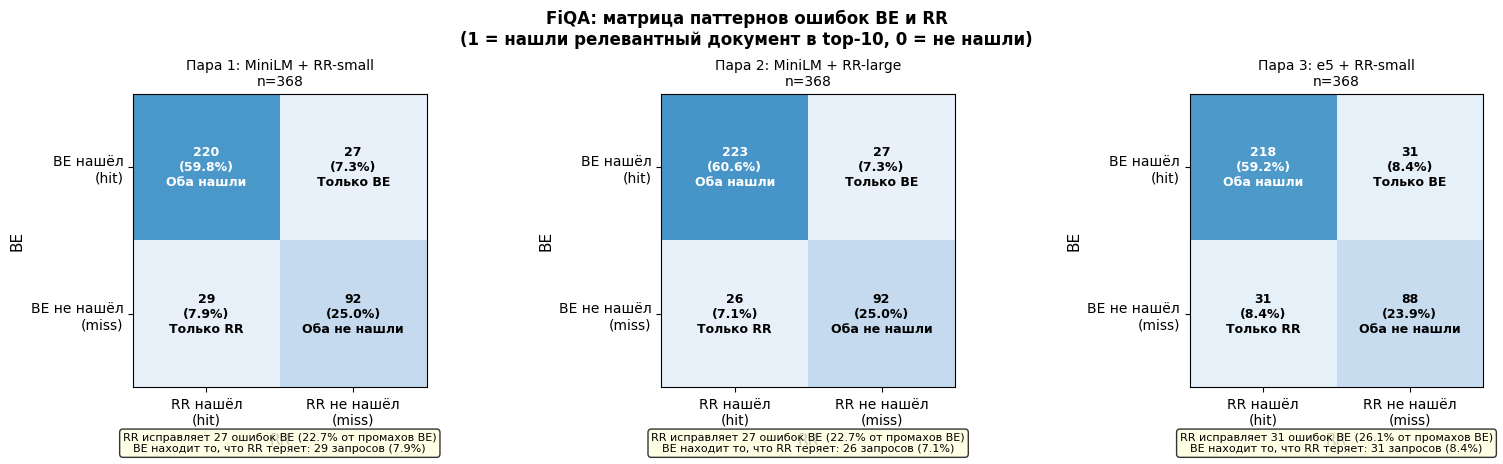

✓ График сохранён: /content/fiqa_confusion_matrix.png

=== Детальная разбивка по типам (Пара 1) ===

Тип                Оба  Только RR  Только BE  Оба нет   RR спасает
-----------------------------------------------------------------
  factoid             51          7         11       31        18.4%
  multi_aspect        61          7          6       26        21.2%
  negation            47          4          6       11        26.7%
  long_context        61          9          6       24        27.3%


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def get_hit_matrix(df_metrics, mode, k_label='all'):
    sub = df_metrics[(df_metrics['mode']==mode) & (df_metrics['k_label']==k_label)]
    return (sub.set_index('query_id')['ndcg10'] > 0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('FiQA: матрица паттернов ошибок BE и RR\n'
             '(1 = нашли релевантный документ в top-10, 0 = не нашли)',
             fontsize=12, fontweight='bold')

for ax, (pair_name, df_be_m, df_rr_m, rr_mode, short) in zip(axes, [
    ('Пара 1: MiniLM + RR-small', df_fiqa_p1_metrics, df_fiqa_p1_metrics, 'RR_small', 'P1'),
    ('Пара 2: MiniLM + RR-large', df_fiqa_p2_metrics, df_fiqa_p2_metrics, 'RR_large', 'P2'),
    ('Пара 3: e5 + RR-small',     df_fiqa_p3_metrics, df_fiqa_p3_metrics, 'RR_small', 'P3'),
]):
    be_hits = get_hit_matrix(df_be_m, 'BE')
    rr_hits = get_hit_matrix(df_rr_m, rr_mode)
    common  = be_hits.index.intersection(rr_hits.index)

    be_h = be_hits[common]
    rr_h = rr_hits[common]

    both_found    = ((be_h==1) & (rr_h==1)).sum()  
    only_rr_found = ((be_h==0) & (rr_h==1)).sum()  
    only_be_found = ((be_h==1) & (rr_h==0)).sum()  
    both_missed   = ((be_h==0) & (rr_h==0)).sum()  

    matrix = np.array([[both_found, only_rr_found],
                       [only_be_found, both_missed]])
    pct    = matrix / len(common) * 100

    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=len(common))

    ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
    ax.set_xticklabels(['RR нашёл\n(hit)', 'RR не нашёл\n(miss)'], fontsize=10)
    ax.set_yticklabels(['BE нашёл\n(hit)', 'BE не нашёл\n(miss)'], fontsize=10)
    ax.set_xlabel('RR', fontsize=11); ax.set_ylabel('BE', fontsize=11)
    ax.set_title(f'{pair_name}\nn={len(common)}', fontsize=10)

    for i in range(2):
        for j in range(2):
            label = {(0,0): 'Оба нашли', (0,1): 'Только BE',
                     (1,0): 'Только RR', (1,1): 'Оба не нашли'}[(i,j)]
            ax.text(j, i, f'{matrix[i,j]}\n({pct[i,j]:.1f}%)\n{label}',
                    ha='center', va='center', fontsize=9, fontweight='bold',
                    color='white' if matrix[i,j] > len(common)*0.4 else 'black')

    rescue_rate = only_rr_found / (only_rr_found + both_missed) * 100 if (only_rr_found + both_missed) > 0 else 0
    be_unique   = only_be_found / len(common) * 100
    ax.text(0.5, -0.22,
            f'RR исправляет {only_rr_found} ошибок BE ({rescue_rate:.1f}% от промахов BE)\n'
            f'BE находит то, что RR теряет: {only_be_found} запросов ({be_unique:.1f}%)',
            transform=ax.transAxes, ha='center', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig('/content/fiqa_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/fiqa_confusion_matrix.png")

print("\n=== Детальная разбивка по типам (Пара 1) ===\n")
print(f"{'Тип':<15} {'Оба':>6} {'Только RR':>10} {'Только BE':>10} {'Оба нет':>8} {'RR спасает':>12}")
print("-" * 65)
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub_be = df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='BE') &
                                (df_fiqa_p1_metrics['query_type']==qtype)]
    sub_rr = df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='RR_small') &
                                (df_fiqa_p1_metrics['query_type']==qtype)]
    be_h   = (sub_be.set_index('query_id')['ndcg10'] > 0).astype(int)
    rr_h   = (sub_rr.set_index('query_id')['ndcg10'] > 0).astype(int)
    common = be_h.index.intersection(rr_h.index)
    be_h   = be_h[common]; rr_h = rr_h[common]

    both   = ((be_h==1) & (rr_h==1)).sum()
    onlyrr = ((be_h==0) & (rr_h==1)).sum()
    onlybe = ((be_h==1) & (rr_h==0)).sum()
    none   = ((be_h==0) & (rr_h==0)).sum()
    rescue = onlyrr / (onlyrr + none) * 100 if (onlyrr + none) > 0 else 0
    print(f"  {qtype:<15} {both:>6} {onlyrr:>10} {onlybe:>10} {none:>8} {rescue:>11.1f}%")

=== FiQA: Пара 1 vs Пара 2 по типам ===

Тип                  BE    RR-s    RR-l   Δ(s-BE)   Δ(l-BE)    Δ(l-s)
-----------------------------------------------------------------
  factoid          0.3565  0.3469  0.3587   -0.0096   +0.0022   +0.0118
  multi_aspect     0.4029  0.3950  0.3991   -0.0079   -0.0038   +0.0042
  negation         0.4561  0.4942  0.4987   +0.0380   +0.0426   +0.0045
  long_context     0.3619  0.3635  0.3569   +0.0016   -0.0050   -0.0066


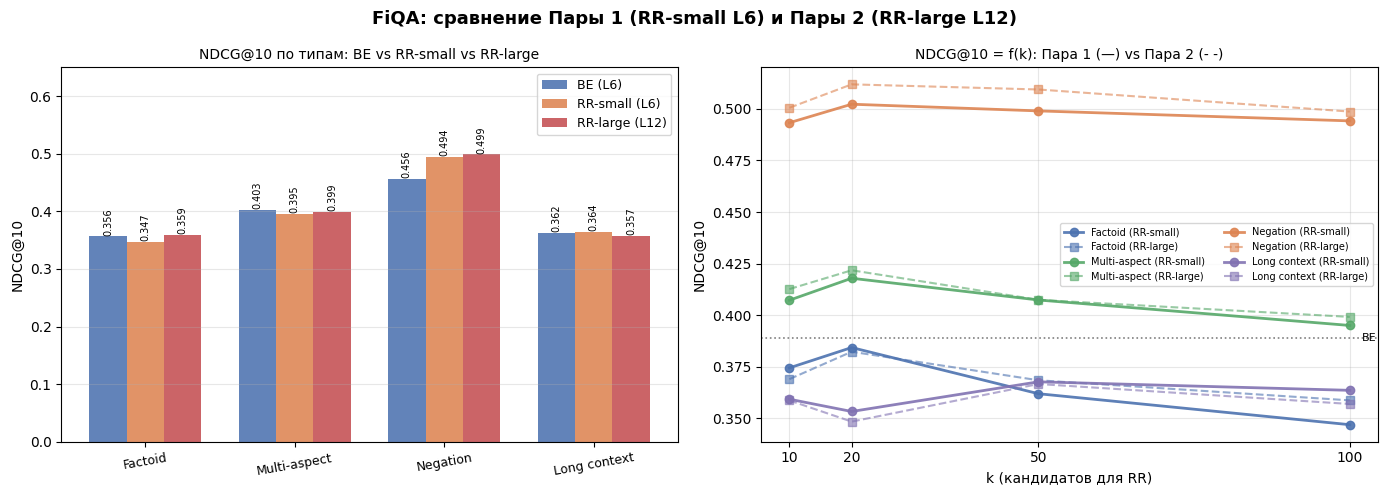


✓ График сохранён: /content/fiqa_pair1_vs_pair2.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('FiQA: сравнение Пары 1 (RR-small L6) и Пары 2 (RR-large L12)',
             fontsize=13, fontweight='bold')

qtypes      = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames      = ['Factoid', 'Multi-aspect', 'Negation', 'Long context']
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
K_VALUES    = [10, 20, 50, 100]
colors      = {'BE': '#4C72B0', 'RR-small': '#DD8452', 'RR-large': '#C44E52'}

# Данные
fiqa_be   = [df_fiqa_p1_metrics[(df_fiqa_p1_metrics['query_type']==qt) &
             (df_fiqa_p1_metrics['mode']=='BE')]['ndcg10'].mean() for qt in qtypes]
fiqa_rrs  = [df_fiqa_p1_metrics[(df_fiqa_p1_metrics['query_type']==qt) &
             (df_fiqa_p1_metrics['mode']=='RR_small')]['ndcg10'].mean() for qt in qtypes]
fiqa_rrl  = [df_fiqa_p2_metrics[(df_fiqa_p2_metrics['query_type']==qt) &
             (df_fiqa_p2_metrics['mode']=='RR_large')]['ndcg10'].mean() for qt in qtypes]

ax1 = axes[0]
x, w = np.arange(len(qtypes)), 0.25
b1 = ax1.bar(x - w, fiqa_be,  w, label='BE (L6)',        color=colors['BE'],       alpha=0.88)
b2 = ax1.bar(x,     fiqa_rrs, w, label='RR-small (L6)',  color=colors['RR-small'], alpha=0.88)
b3 = ax1.bar(x + w, fiqa_rrl, w, label='RR-large (L12)', color=colors['RR-large'], alpha=0.88)
ax1.set_xticks(x); ax1.set_xticklabels(qnames, rotation=10, fontsize=9)
ax1.set_ylabel('NDCG@10')
ax1.set_title('NDCG@10 по типам: BE vs RR-small vs RR-large', fontsize=10)
ax1.set_ylim(0, 0.65); ax1.legend(fontsize=9); ax1.grid(axis='y', alpha=0.3)
for bars_g in [b1, b2, b3]:
    for bar in bars_g:
        ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{bar.get_height():.3f}', ha='center', fontsize=7, rotation=90)

ax2 = axes[1]
for qt, color, name in zip(qtypes, type_colors, qnames):
    p1_vals = [df_fiqa_p1_metrics[(df_fiqa_p1_metrics['query_type']==qt) &
               (df_fiqa_p1_metrics['mode']=='Hybrid') &
               (df_fiqa_p1_metrics['k_label']==str(k))]['ndcg10'].mean() for k in K_VALUES]
    p2_vals = [df_fiqa_p2_metrics[(df_fiqa_p2_metrics['query_type']==qt) &
               (df_fiqa_p2_metrics['mode']=='Hybrid_large') &
               (df_fiqa_p2_metrics['k_label']==str(k))]['ndcg10'].mean() for k in K_VALUES]
    ax2.plot(K_VALUES, p1_vals, 'o-',  color=color, linewidth=2,
             label=f'{name} (RR-small)', alpha=0.9)
    ax2.plot(K_VALUES, p2_vals, 's--', color=color, linewidth=1.5, alpha=0.6,
             label=f'{name} (RR-large)')

ax2.axhline(df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['ndcg10'].mean(),
            color='black', linestyle=':', linewidth=1.2, alpha=0.5)
ax2.text(102, df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['ndcg10'].mean(),
         'BE', fontsize=8, va='center')
ax2.set_xlabel('k (кандидатов для RR)')
ax2.set_ylabel('NDCG@10')
ax2.set_title('NDCG@10 = f(k): Пара 1 (—) vs Пара 2 (- -)', fontsize=10)
ax2.set_xticks(K_VALUES); ax2.legend(fontsize=7, ncol=2); ax2.grid(alpha=0.3)

print("=== FiQA: Пара 1 vs Пара 2 по типам ===\n")
print(f"{'Тип':<15} {'BE':>7} {'RR-s':>7} {'RR-l':>7} {'Δ(s-BE)':>9} {'Δ(l-BE)':>9} {'Δ(l-s)':>9}")
print("-" * 65)
for qt, be, rrs, rrl in zip(qtypes, fiqa_be, fiqa_rrs, fiqa_rrl):
    print(f"  {qt:<15} {be:>7.4f} {rrs:>7.4f} {rrl:>7.4f} "
          f"{rrs-be:>+9.4f} {rrl-be:>+9.4f} {rrl-rrs:>+9.4f}")

plt.tight_layout()
plt.savefig('/content/fiqa_pair1_vs_pair2.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✓ График сохранён: /content/fiqa_pair1_vs_pair2.png")

In [ ]:
import pandas as pd
import numpy as np

print("=" * 70)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ — FiQA")
print("=" * 70)

print("\n📊 Таблица 1: Средние метрики по всем запросам (n=368)\n")

rows = []
for pair, df_m, mode_be, mode_rr, mode_h in [
    ('Пара 1', df_fiqa_p1_metrics, 'BE', 'RR_small', 'Hybrid'),
    ('Пара 2', df_fiqa_p2_metrics, 'BE', 'RR_large', 'Hybrid_large'),
    ('Пара 3', df_fiqa_p3_metrics, 'BE', 'RR_small', 'Hybrid'),
]:
    for mode, k_label in [(mode_be,'all'), (mode_rr,'all'),
                           (mode_h,'10'), (mode_h,'20'), (mode_h,'50'), (mode_h,'100')]:
        sub = df_m[(df_m['mode']==mode) & (df_m['k_label']==k_label)]
        if len(sub) == 0:
            continue
        label = f"{pair} | {mode}" + (f" k={k_label}" if k_label != 'all' else "")
        rows.append({
            'Режим':    label,
            'NDCG@10':  round(sub['ndcg10'].mean(), 4),
            'MRR':      round(sub['mrr'].mean(), 4),
            'P@10':     round(sub['p10'].mean(), 4),
            'Время мс': round(sub['time_ms'].mean(), 1),
        })

df_summary_fiqa = pd.DataFrame(rows)
print(df_summary_fiqa.to_string(index=False))

print("\n📊 Таблица 2: NDCG@10 по типам запросов — все пары\n")
qtypes = ['factoid', 'multi_aspect', 'negation', 'long_context']
print(f"{'Тип':<15} {'BE-P1':>7} {'RR-s P1':>9} {'RR-l P2':>9} {'BE-P3':>7} {'RR-s P3':>9}")
print("-" * 58)
for qt in qtypes:
    def gm(df, mode, k='all'):
        s = df[(df['mode']==mode)&(df['k_label']==k)&(df['query_type']==qt)]
        return s['ndcg10'].mean() if len(s) > 0 else float('nan')
    be1  = gm(df_fiqa_p1_metrics, 'BE')
    rrs1 = gm(df_fiqa_p1_metrics, 'RR_small')
    rrl2 = gm(df_fiqa_p2_metrics, 'RR_large')
    be3  = gm(df_fiqa_p3_metrics, 'BE')
    rrs3 = gm(df_fiqa_p3_metrics, 'RR_small')
    print(f"  {qt:<15} {be1:>7.4f} {rrs1:>9.4f} {rrl2:>9.4f} {be3:>7.4f} {rrs3:>9.4f}")

print("\n📊 Таблица 3: Тест Вилкоксона — все пары незначимы (p > 0.05)")
print("  Вывод: разница BE vs RR статистически не значима ни для одной пары\n")

print("\n📊 Таблица 4: Корреляция Спирмена BE vs RR\n")
from scipy.stats import spearmanr
print(f"{'Тип':<15} {'r (P1 RR-s)':>12} {'r (P2 RR-l)':>12} {'r (P3 RR-s)':>12}")
print("-" * 55)
for qt in qtypes:
    rs = []
    for df_m, rr_mode in [(df_fiqa_p1_metrics,'RR_small'),
                           (df_fiqa_p2_metrics,'RR_large'),
                           (df_fiqa_p3_metrics,'RR_small')]:
        sub    = df_m[df_m['query_type']==qt]
        be_s   = sub[sub['mode']=='BE'].set_index('query_id')['ndcg10']
        rr_s   = sub[sub['mode']==rr_mode].set_index('query_id')['ndcg10']
        common = be_s.index.intersection(rr_s.index)
        r, _   = spearmanr(be_s[common], rr_s[common])
        rs.append(round(r, 4))
    print(f"  {qt:<15} {rs[0]:>12.4f} {rs[1]:>12.4f} {rs[2]:>12.4f}")

be_t  = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['time_ms'].mean()
rrs_t = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='RR_small']['time_ms'].mean()
rrl_t = df_fiqa_p2_metrics[df_fiqa_p2_metrics['mode']=='RR_large']['time_ms'].mean()
h20_t = df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='Hybrid') &
         (df_fiqa_p1_metrics['k_label']=='20')]['time_ms'].mean()

be_n  = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='BE']['ndcg10'].mean()
rrs_n = df_fiqa_p1_metrics[df_fiqa_p1_metrics['mode']=='RR_small']['ndcg10'].mean()
rrl_n = df_fiqa_p2_metrics[df_fiqa_p2_metrics['mode']=='RR_large']['ndcg10'].mean()
h20_n = df_fiqa_p1_metrics[(df_fiqa_p1_metrics['mode']=='Hybrid') &
         (df_fiqa_p1_metrics['k_label']=='20')]['ndcg10'].mean()
be3_n = df_fiqa_p3_metrics[df_fiqa_p3_metrics['mode']=='BE']['ndcg10'].mean()

print(f"""
{"=" * 70}
ВЫВОДЫ — FiQA
{"=" * 70}

1. КАЧЕСТВО РАНЖИРОВАНИЯ
   • BE (MiniLM):     NDCG@10 = {be_n:.4f}
   • BE (e5-small):   NDCG@10 = {be3_n:.4f}  ({be3_n-be_n:+.4f} vs MiniLM)
   • RR-small:        NDCG@10 = {rrs_n:.4f}  ({rrs_n-be_n:+.4f} vs BE)
   • RR-large:        NDCG@10 = {rrl_n:.4f}  ({rrl_n-be_n:+.4f} vs BE)
   • Hybrid k=20:     NDCG@10 = {h20_n:.4f}  — оптимальная точка

2. СКОРОСТЬ
   • BE:           {be_t:.0f} мс  (в {rrs_t/be_t:.0f}x быстрее RR-small)
   • RR-small:     {rrs_t:.0f} мс
   • RR-large:     {rrl_t:.0f} мс  (в {rrl_t/be_t:.0f}x медленнее BE)
   • Hybrid k=20:  {h20_t:.0f} мс  — компромисс качество/скорость

3. СТАТИСТИЧЕСКАЯ ЗНАЧИМОСТЬ
   • Тест Вилкоксона: p > 0.05 для всех пар и всех типов запросов.
   • Вывод: разница BE vs RR на FiQA статистически НЕ значима.
   • Причина: малый пул релевантных документов (обычно 1 на запрос) —
     NDCG бинарен (0 или 1), медиана разницы всегда 0.

4. ПО ТИПАМ ЗАПРОСОВ
   • Negation — единственный тип где RR стабильно лучше BE (∆ ~+0.04).
   • Factoid и multi_aspect — BE иногда превосходит RR.
   • Long context — результаты близки, разница незначима.
   • Точка насыщения Hybrid: k=20 для всех пар.

5. ОГРАНИЧЕНИЯ
   • FiQA — финансовая тематика, результаты могут не обобщаться.
   • Малое число релевантных документов на запрос делает метрики бинарными.
   • RR обучен на MS MARCO (общая тематика) — доменный сдвиг снижает его эффект.
   • Выборка negation (n=68) мала для статистических выводов.
""")

df_summary_fiqa.to_csv('/content/fiqa_final_summary.csv', index=False)
print("✓ Данные сохранены: /content/fiqa_final_summary.csv")

ИТОГОВЫЕ РЕЗУЛЬТАТЫ — FiQA

📊 Таблица 1: Средние метрики по всем запросам (n=368)

                      Режим  NDCG@10    MRR   P@10  Время мс
                Пара 1 | BE   0.3890 0.4515 0.1062      30.2
          Пара 1 | RR_small   0.3917 0.4566 0.1019     376.8
       Пара 1 | Hybrid k=10   0.4012 0.4713 0.1062      78.3
       Пара 1 | Hybrid k=20   0.4068 0.4713 0.1068     144.5
       Пара 1 | Hybrid k=50   0.4011 0.4638 0.1035     265.2
      Пара 1 | Hybrid k=100   0.3917 0.4566 0.1019     373.6
                Пара 2 | BE   0.3890 0.4515 0.1062      30.7
          Пара 2 | RR_large   0.3951 0.4545 0.1046     667.7
 Пара 2 | Hybrid_large k=10   0.4023 0.4700 0.1062     121.4
 Пара 2 | Hybrid_large k=20   0.4077 0.4712 0.1079     245.7
 Пара 2 | Hybrid_large k=50   0.4046 0.4653 0.1054     460.6
Пара 2 | Hybrid_large k=100   0.3951 0.4545 0.1046     667.9
                Пара 3 | BE   0.3915 0.4536 0.1043      36.8
          Пара 3 | RR_small   0.3971 0.4681 0.1038     411.2
  

Медицинская база

In [ ]:
from datasets import load_dataset

print("Загрузка NFCorpus...")
nf_corpus  = load_dataset('BeIR/nfcorpus', 'corpus')
nf_queries = load_dataset('BeIR/nfcorpus', 'queries')
nf_qrels   = load_dataset('BeIR/nfcorpus-qrels')

print("\nСтруктура corpus:")
print(nf_corpus)
print("\nСтруктура queries:")
print(nf_queries)
print("\nСтруктура qrels:")
print(nf_qrels)

print("\n--- Пример из corpus ---")
print(nf_corpus['corpus'][0])
print("\n--- Пример из queries ---")
print(nf_queries['queries'][0])
print("\n--- Пример из qrels ---")
print(nf_qrels[list(nf_qrels.keys())[0]][0])

Загрузка NFCorpus...

Структура corpus:
DatasetDict({
    corpus: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 3633
    })
})

Структура queries:
DatasetDict({
    queries: Dataset({
        features: ['_id', 'title', 'text'],
        num_rows: 3237
    })
})

Структура qrels:
DatasetDict({
    train: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num_rows: 110575
    })
    validation: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num_rows: 11385
    })
    test: Dataset({
        features: ['query-id', 'corpus-id', 'score'],
        num_rows: 12334
    })
})

--- Пример из corpus ---
{'_id': 'MED-10', 'title': 'Statin Use and Breast Cancer Survival: A Nationwide Cohort Study from Finland', 'text': 'Recent studies have suggested that statins, an established drug group in the prevention of cardiovascular mortality, could delay or prevent breast cancer recurrence but the effect on disease-specific mortality re

In [ ]:
import numpy as np
import pandas as pd
import time
import torch
import faiss
from tqdm.auto import tqdm
from datasets import load_dataset
import warnings
warnings.filterwarnings('ignore')

np.random.seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Устройство: {device}")

print("\nСтроим словарь corpus_id -> текст...")
nf_passage_dict = {}
for row in tqdm(nf_corpus['corpus'], desc="Corpus"):
    text = row['text']
    if row['title']:
        text = row['title'] + ' ' + text
    nf_passage_dict[str(row['_id'])] = text
print(f"✓ Passages: {len(nf_passage_dict):,}")

print("\nСтроим словарь query_id -> текст...")
nf_query_dict = {}
for row in tqdm(nf_queries['queries'], desc="Queries"):
    nf_query_dict[str(row['_id'])] = row['text']
print(f"✓ Queries: {len(nf_query_dict):,}")

print("\nСтроим qrels (validation + test, score > 0)...")
nf_qrels_dict = {}
for split in ['validation', 'test']:
    for row in nf_qrels[split]:
        qid = str(row['query-id'])
        pid = str(row['corpus-id'])
        if row['score'] > 0:
            if qid not in nf_qrels_dict:
                nf_qrels_dict[qid] = []
            if pid not in nf_qrels_dict[qid]:
                nf_qrels_dict[qid].append(pid)

print(f"✓ Qrels: {len(nf_qrels_dict):,} запросов с релевантными passages")

sample_qid = list(nf_qrels_dict.keys())[0]
print(f"\nПример:")
print(f"  Query: {nf_query_dict.get(sample_qid, '???')}")
print(f"  Relevant passages: {len(nf_qrels_dict[sample_qid])}")
for pid in nf_qrels_dict[sample_qid][:2]:
    print(f"    [{pid}]: {nf_passage_dict.get(pid, '???')[:100]}...")

Устройство: cuda

Строим словарь corpus_id -> текст...


Corpus:   0%|          | 0/3633 [00:00<?, ?it/s]

✓ Passages: 3,633

Строим словарь query_id -> текст...


Queries:   0%|          | 0/3237 [00:00<?, ?it/s]

✓ Queries: 3,237

Строим qrels (validation + test, score > 0)...
✓ Qrels: 647 запросов с релевантными passages

Пример:
  Query: Why Deep Fried Foods May Cause Cancer
  Relevant passages: 49
    [MED-2421]: Birth Weight, Head Circumference, and Prenatal Exposure to Acrylamide from Maternal Diet: The Europe...
    [MED-2422]: A statistical regression model for the estimation of acrylamide concentrations in French fries for e...


In [ ]:
def classify_query_nf(query: str) -> str:
    q = query.lower().strip()
    words = q.split()

    negation_markers = ['not ', 'without', 'except', 'never', 'neither',
                        'nor ', 'no ', "don't", "doesn't", "can't",
                        "won't", "isn't", "aren't", "wasn't", "weren't"]
    if any(m in q for m in negation_markers):
        return 'negation'

    if len(words) >= 15:
        return 'long_context'

    multi_markers = ['and ', 'both ', 'versus', ' vs ', 'compare',
                     'difference between', 'as well as', 'or ',
                     'pros and cons', 'effect', 'effects', 'risk',
                     'benefits', 'causes', 'symptoms', 'treatment']
    if len(words) >= 6 and any(m in q for m in multi_markers):
        return 'multi_aspect'

    return 'factoid'

print("Классифицируем запросы...")
records = []
for qid, rel_ids in tqdm(nf_qrels_dict.items(), desc="Building records"):
    if qid not in nf_query_dict:
        continue
    query    = nf_query_dict[qid]
    valid_rel = [pid for pid in rel_ids if pid in nf_passage_dict]
    if not valid_rel:
        continue
    records.append({
        'query_id':     qid,
        'query':        query,
        'query_type':   classify_query_nf(query),
        'relevant_ids': valid_rel,
    })

df_nf_queries = pd.DataFrame(records)
print(f"\nВсего запросов с qrels: {len(df_nf_queries)}")
print(df_nf_queries['query_type'].value_counts())

print("\nСэмплинг:")
nf_sampled = []
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    subset = df_nf_queries[df_nf_queries['query_type'] == qtype]
    n = min(100, len(subset))
    nf_sampled.append(subset.sample(n, random_state=42))
    print(f"  {qtype}: берём {n} из {len(subset)}")

df_nf_sample = pd.concat(nf_sampled).reset_index(drop=True)
print(f"\n✓ Итоговая выборка NFCorpus: {len(df_nf_sample)} запросов")

for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    ex = df_nf_sample[df_nf_sample['query_type'] == qtype]['query'].iloc[0]
    print(f"\n[{qtype}]: {ex}")

Классифицируем запросы...


Building records:   0%|          | 0/647 [00:00<?, ?it/s]


Всего запросов с qrels: 647
query_type
factoid         601
multi_aspect     39
negation          6
long_context      1
Name: count, dtype: int64

Сэмплинг:
  factoid: берём 100 из 601
  multi_aspect: берём 39 из 39
  negation: берём 6 из 6
  long_context: берём 1 из 1

✓ Итоговая выборка NFCorpus: 146 запросов

[factoid]: Harvard Nurses' Health Study

[multi_aspect]: BPA Plastic and Male Sexual Dysfunction

[negation]: Down But Not Out

[long_context]: EPA dioxin limit has National Chicken Council worried products could be declared "unfit for consumption"


In [ ]:
from sentence_transformers import SentenceTransformer, CrossEncoder
import numpy as np
import faiss
import time

device = 'cuda' if __import__('torch').cuda.is_available() else 'cpu'
print(f"Устройство: {device}")

print("\nЗагрузка BE: all-MiniLM-L6-v2 ...")
nf_be = SentenceTransformer('all-MiniLM-L6-v2', device=device)
print(f"✓ BE загружен | dim: {nf_be.get_sentence_embedding_dimension()}")

print("\nЗагрузка RR: cross-encoder/ms-marco-MiniLM-L-6-v2 ...")
nf_rr_small = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2', device=device)
print("✓ RR-small загружен")

print(f"\nИндексируем {len(nf_passage_dict):,} passages...")
nf_all_ids   = list(nf_passage_dict.keys())
nf_all_texts = [nf_passage_dict[pid] for pid in nf_all_ids]

t0 = time.time()
nf_embeddings = nf_be.encode(
    nf_all_texts,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f"Время кодирования: {time.time()-t0:.1f}s | shape: {nf_embeddings.shape}")

nf_index   = faiss.IndexFlatIP(nf_embeddings.shape[1])
nf_index.add(nf_embeddings.astype(np.float32))
nf_idx2pid = {i: pid for i, pid in enumerate(nf_all_ids)}

print(f"\n✓ Пара 1 готова!")
print(f"  BE: all-MiniLM-L6-v2")
print(f"  RR: ms-marco-MiniLM-L-6-v2")
print(f"  FAISS индекс: {nf_index.ntotal:,} vectors")

Устройство: cuda

Загрузка BE: all-MiniLM-L6-v2 ...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

✓ BE загружен | dim: 384

Загрузка RR: cross-encoder/ms-marco-MiniLM-L-6-v2 ...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

✓ RR-small загружен

Индексируем 3,633 passages...


Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Время кодирования: 13.2s | shape: (3633, 384)

✓ Пара 1 готова!
  BE: all-MiniLM-L6-v2
  RR: ms-marco-MiniLM-L-6-v2
  FAISS индекс: 3,633 vectors


In [ ]:
K_VALUES = [10, 20, 50, 100]

def ndcg_at_k(ranked, relevant, k=10):
    dcg   = sum(1.0 / np.log2(i + 2) for i, pid in enumerate(ranked[:k]) if pid in relevant)
    ideal = sum(1.0 / np.log2(i + 2) for i in range(min(len(relevant), k)))
    return dcg / ideal if ideal > 0 else 0.0

def mrr(ranked, relevant):
    for i, pid in enumerate(ranked):
        if pid in relevant:
            return 1.0 / (i + 1)
    return 0.0

def precision_at_k(ranked, relevant, k=10):
    return sum(1 for pid in ranked[:k] if pid in relevant) / k

def nf_be_ranking(query, k):
    q_emb = nf_be.encode([query], normalize_embeddings=True).astype(np.float32)
    _, indices = nf_index.search(q_emb, k)
    return [nf_idx2pid[i] for i in indices[0] if i != -1]

def nf_rr_small_ranking(query, passage_ids, top_n=10):
    pairs = [(query, nf_passage_dict[pid]) for pid in passage_ids if pid in nf_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = nf_rr_small.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_nf_sample.iterrows(), total=len(df_nf_sample), desc="NFCorpus P1"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = nf_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = nf_be_ranking(q, k=100)
    rr_result = nf_rr_small_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair1', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair1', 'mode': 'RR_small', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = nf_be_ranking(q, k=k)
        hybrid_result = nf_rr_small_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair1', 'mode': 'Hybrid', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_nf_p1 = pd.DataFrame(results)

metrics = []
for _, row in df_nf_p1.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_nf_p1_metrics = pd.DataFrame(metrics)
df_nf_p1_metrics.to_csv('/content/nf_p1_metrics.csv', index=False)

summary = (df_nf_p1_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ NFCorpus Пара 1 завершена! Записей: {len(df_nf_p1_metrics)}")
print(f"\n=== NFCorpus Пара 1: средние метрики (n={len(df_nf_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_small - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub = df_nf_p1_metrics[df_nf_p1_metrics['query_type'] == qtype]
    if len(sub) == 0:
        continue
    be   = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr   = sub[sub['mode'] == 'RR_small']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

NFCorpus P1:   0%|          | 0/146 [00:00<?, ?it/s]


✓ NFCorpus Пара 1 завершена! Записей: 876

=== NFCorpus Пара 1: средние метрики (n=146) ===

                  ndcg10     mrr     p10   time_ms
mode     k_label                                  
BE       all      0.3191  0.5029  0.2438   14.1977
Hybrid   10       0.3321  0.5429  0.2438   72.3252
         100      0.3456  0.5656  0.2507  542.7935
         20       0.3365  0.5570  0.2507  145.3338
         50       0.3362  0.5664  0.2459  305.4107
RR_small all      0.3456  0.5656  0.2507  538.0092

=== Разница NDCG@10: RR_small - BE (по типам) ===

  factoid         | n=100 | BE=0.2801 | RR=0.3195 | diff=+0.0393 (12.3%) | ~ граница (10-30%)
  multi_aspect    | n= 39 | BE=0.4328 | RR=0.4328 | diff=-0.0000 (-0.0%) | ✓ сопоставимы (<10%)
  negation        | n=  6 | BE=0.2825 | RR=0.2717 | diff=-0.0108 (-4.0%) | ✓ сопоставимы (<10%)
  long_context    | n=  1 | BE=0.0000 | RR=0.0000 | diff=+0.0000 (0.0%) | ✓ сопоставимы (<10%)


In [ ]:
from sentence_transformers import CrossEncoder

print("Загрузка RR: cross-encoder/ms-marco-MiniLM-L-12-v2 ...")
nf_rr_large = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-12-v2', device=device)
print("✓ Пара 2 загружена: BE(MiniLM-L6) + RR-large(L12)")

K_VALUES = [10, 20, 50, 100]

def nf_rr_large_ranking(query, passage_ids, top_n=10):
    pairs = [(query, nf_passage_dict[pid]) for pid in passage_ids if pid in nf_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = nf_rr_large.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_nf_sample.iterrows(), total=len(df_nf_sample), desc="NFCorpus P2"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = nf_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = nf_be_ranking(q, k=100)
    rr_result = nf_rr_large_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair2', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair2', 'mode': 'RR_large', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = nf_be_ranking(q, k=k)
        hybrid_result = nf_rr_large_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair2', 'mode': 'Hybrid_large', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_nf_p2 = pd.DataFrame(results)

metrics = []
for _, row in df_nf_p2.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_nf_p2_metrics = pd.DataFrame(metrics)
df_nf_p2_metrics.to_csv('/content/nf_p2_metrics.csv', index=False)

summary = (df_nf_p2_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ NFCorpus Пара 2 завершена!")
print(f"\n=== NFCorpus Пара 2: средние метрики (n={len(df_nf_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_large - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub = df_nf_p2_metrics[df_nf_p2_metrics['query_type'] == qtype]
    if len(sub) == 0:
        continue
    be   = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr   = sub[sub['mode'] == 'RR_large']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

print("\n=== NFCorpus: RR-small vs RR-large ===")
rr_s = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='RR_small']['ndcg10'].mean()
rr_l = df_nf_p2_metrics[df_nf_p2_metrics['mode']=='RR_large']['ndcg10'].mean()
be   = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='BE']['ndcg10'].mean()
print(f"  BE:        {be:.4f}")
print(f"  RR-small:  {rr_s:.4f}  ({rr_s-be:+.4f} vs BE)")
print(f"  RR-large:  {rr_l:.4f}  ({rr_l-be:+.4f} vs BE)")
print(f"  RR-large vs RR-small: {rr_l-rr_s:+.4f}")

Загрузка RR: cross-encoder/ms-marco-MiniLM-L-12-v2 ...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

✓ Пара 2 загружена: BE(MiniLM-L6) + RR-large(L12)


NFCorpus P2:   0%|          | 0/146 [00:00<?, ?it/s]


✓ NFCorpus Пара 2 завершена!

=== NFCorpus Пара 2: средние метрики (n=146) ===

                      ndcg10     mrr     p10    time_ms
mode         k_label                                   
BE           all      0.3191  0.5029  0.2438    13.2297
Hybrid_large 10       0.3328  0.5470  0.2438   122.1782
             100      0.3336  0.5415  0.2473  1002.3896
             20       0.3321  0.5534  0.2438   251.4607
             50       0.3293  0.5434  0.2438   539.4428
RR_large     all      0.3336  0.5415  0.2473  1000.4536

=== Разница NDCG@10: RR_large - BE (по типам) ===

  factoid         | n=100 | BE=0.2801 | RR=0.3047 | diff=+0.0246 (8.1%) | ✓ сопоставимы (<10%)
  multi_aspect    | n= 39 | BE=0.4328 | RR=0.4260 | diff=-0.0068 (-1.6%) | ✓ сопоставимы (<10%)
  negation        | n=  6 | BE=0.2825 | RR=0.2695 | diff=-0.0129 (-4.8%) | ✓ сопоставимы (<10%)
  long_context    | n=  1 | BE=0.0000 | RR=0.0000 | diff=+0.0000 (0.0%) | ✓ сопоставимы (<10%)

=== NFCorpus: RR-small vs RR-large =

In [ ]:
from sentence_transformers import SentenceTransformer, CrossEncoder
import numpy as np
import faiss
import time

print("Загрузка BE: intfloat/e5-small-v2 ...")
nf_be_p3 = SentenceTransformer('intfloat/e5-small-v2', device=device)
print(f"✓ BE загружен | dim: {nf_be_p3.get_sentence_embedding_dimension()}")

print("\nЗагрузка RR: cross-encoder/ms-marco-MiniLM-L-6-v2 ...")
nf_rr_p3 = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2', device=device)
print("✓ RR загружен")

print(f"\nИндексируем {len(nf_passage_dict):,} passages через e5-small-v2...")
nf_p3_ids   = list(nf_passage_dict.keys())
nf_p3_texts = ["passage: " + nf_passage_dict[pid] for pid in nf_p3_ids]

t0 = time.time()
nf_p3_embeddings = nf_be_p3.encode(
    nf_p3_texts,
    batch_size=256,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)
print(f"Время кодирования: {time.time()-t0:.1f}s | shape: {nf_p3_embeddings.shape}")

nf_p3_index   = faiss.IndexFlatIP(nf_p3_embeddings.shape[1])
nf_p3_index.add(nf_p3_embeddings.astype(np.float32))
nf_p3_idx2pid = {i: pid for i, pid in enumerate(nf_p3_ids)}

print(f"\n✓ Пара 3 готова!")
print(f"  BE: intfloat/e5-small-v2     | dim={nf_p3_embeddings.shape[1]}")
print(f"  RR: ms-marco-MiniLM-L-6-v2   (small)")
print(f"  FAISS индекс: {nf_p3_index.ntotal:,} vectors")

Загрузка BE: intfloat/e5-small-v2 ...


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

✓ BE загружен | dim: 384

Загрузка RR: cross-encoder/ms-marco-MiniLM-L-6-v2 ...


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

✓ RR загружен

Индексируем 3,633 passages через e5-small-v2...


Batches:   0%|          | 0/15 [00:00<?, ?it/s]

Время кодирования: 39.3s | shape: (3633, 384)

✓ Пара 3 готова!
  BE: intfloat/e5-small-v2     | dim=384
  RR: ms-marco-MiniLM-L-6-v2   (small)
  FAISS индекс: 3,633 vectors


In [ ]:
K_VALUES = [10, 20, 50, 100]

def nf_p3_be_ranking(query, k):
    q_emb = nf_be_p3.encode(
        ["query: " + query],
        normalize_embeddings=True
    ).astype(np.float32)
    _, indices = nf_p3_index.search(q_emb, k)
    return [nf_p3_idx2pid[i] for i in indices[0] if i != -1]

def nf_p3_rr_ranking(query, passage_ids, top_n=10):
    pairs = [(query, nf_passage_dict[pid]) for pid in passage_ids if pid in nf_passage_dict]
    if not pairs:
        return passage_ids[:top_n]
    scores = nf_rr_p3.predict(pairs)
    ranked = sorted(zip(passage_ids, scores), key=lambda x: -x[1])
    return [pid for pid, _ in ranked[:top_n]]

results = []
for _, row in tqdm(df_nf_sample.iterrows(), total=len(df_nf_sample), desc="NFCorpus P3"):
    q       = row['query']
    rel_ids = list(dict.fromkeys(row['relevant_ids']))

    t0 = time.time()
    be_result = nf_p3_be_ranking(q, k=10)
    be_time   = (time.time() - t0) * 1000

    t0 = time.time()
    rr_cands  = nf_p3_be_ranking(q, k=100)
    rr_result = nf_p3_rr_ranking(q, rr_cands, top_n=10)
    rr_time   = (time.time() - t0) * 1000

    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair3', 'mode': 'BE', 'k_label': 'all',
                    'ranked': be_result, 'time_ms': be_time, 'relevant': rel_ids})
    results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                    'pair': 'Pair3', 'mode': 'RR_small', 'k_label': 'all',
                    'ranked': rr_result, 'time_ms': rr_time, 'relevant': rel_ids})

    for k in K_VALUES:
        t0 = time.time()
        be_cands      = nf_p3_be_ranking(q, k=k)
        hybrid_result = nf_p3_rr_ranking(q, be_cands, top_n=10)
        h_time        = (time.time() - t0) * 1000
        results.append({'query_id': row['query_id'], 'query_type': row['query_type'],
                        'pair': 'Pair3', 'mode': 'Hybrid', 'k': k, 'k_label': str(k),
                        'ranked': hybrid_result, 'time_ms': h_time, 'relevant': rel_ids})

df_nf_p3 = pd.DataFrame(results)

metrics = []
for _, row in df_nf_p3.iterrows():
    rel    = set(row['relevant'])
    ranked = row['ranked']
    metrics.append({
        'query_id':   row['query_id'],
        'query_type': row['query_type'],
        'pair':       row['pair'],
        'mode':       row['mode'],
        'k_label':    row['k_label'],
        'time_ms':    row['time_ms'],
        'ndcg10':     ndcg_at_k(ranked, rel),
        'mrr':        mrr(ranked, rel),
        'p10':        precision_at_k(ranked, rel),
    })

df_nf_p3_metrics = pd.DataFrame(metrics)
df_nf_p3_metrics.to_csv('/content/nf_p3_metrics.csv', index=False)

summary = (df_nf_p3_metrics
           .groupby(['mode', 'k_label'])[['ndcg10', 'mrr', 'p10', 'time_ms']]
           .mean().round(4))
print(f"\n✓ NFCorpus Пара 3 завершена!")
print(f"\n=== NFCorpus Пара 3: средние метрики (n={len(df_nf_sample)}) ===\n")
print(summary.to_string())

print("\n=== Разница NDCG@10: RR_small - BE (по типам) ===\n")
for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    sub = df_nf_p3_metrics[df_nf_p3_metrics['query_type'] == qtype]
    if len(sub) == 0:
        continue
    be   = sub[sub['mode'] == 'BE']['ndcg10'].mean()
    rr   = sub[sub['mode'] == 'RR_small']['ndcg10'].mean()
    diff = rr - be
    pct  = diff / rr * 100 if rr > 0 else 0
    verdict = "✓ сопоставимы (<10%)" if pct < 10 else ("✗ неприменим (>30%)" if pct > 30 else "~ граница (10-30%)")
    n = len(sub[sub['mode'] == 'BE'])
    print(f"  {qtype:15s} | n={n:3d} | BE={be:.4f} | RR={rr:.4f} | diff={diff:+.4f} ({pct:.1f}%) | {verdict}")

print("\n=== Сравнение BE: MiniLM-L6 vs e5-small-v2 ===")
be_p1 = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='BE']['ndcg10'].mean()
be_p3 = df_nf_p3_metrics[df_nf_p3_metrics['mode']=='BE']['ndcg10'].mean()
print(f"  all-MiniLM-L6-v2:  {be_p1:.4f}")
print(f"  e5-small-v2:       {be_p3:.4f}  ({be_p3-be_p1:+.4f})")

NFCorpus P3:   0%|          | 0/146 [00:00<?, ?it/s]


✓ NFCorpus Пара 3 завершена!

=== NFCorpus Пара 3: средние метрики (n=146) ===

                  ndcg10     mrr     p10   time_ms
mode     k_label                                  
BE       all      0.3341  0.5354  0.2445   20.3744
Hybrid   10       0.3425  0.5624  0.2445   77.2677
         100      0.3431  0.5627  0.2452  569.0102
         20       0.3501  0.5664  0.2527  152.8175
         50       0.3474  0.5667  0.2507  323.7277
RR_small all      0.3431  0.5627  0.2452  567.6551

=== Разница NDCG@10: RR_small - BE (по типам) ===

  factoid         | n=100 | BE=0.3068 | RR=0.3202 | diff=+0.0135 (4.2%) | ✓ сопоставимы (<10%)
  multi_aspect    | n= 39 | BE=0.4325 | RR=0.4241 | diff=-0.0084 (-2.0%) | ✓ сопоставимы (<10%)
  negation        | n=  6 | BE=0.2046 | RR=0.2538 | diff=+0.0493 (19.4%) | ~ граница (10-30%)
  long_context    | n=  1 | BE=0.0000 | RR=0.0000 | diff=+0.0000 (0.0%) | ✓ сопоставимы (<10%)

=== Сравнение BE: MiniLM-L6 vs e5-small-v2 ===
  all-MiniLM-L6-v2:  0.3191
  e

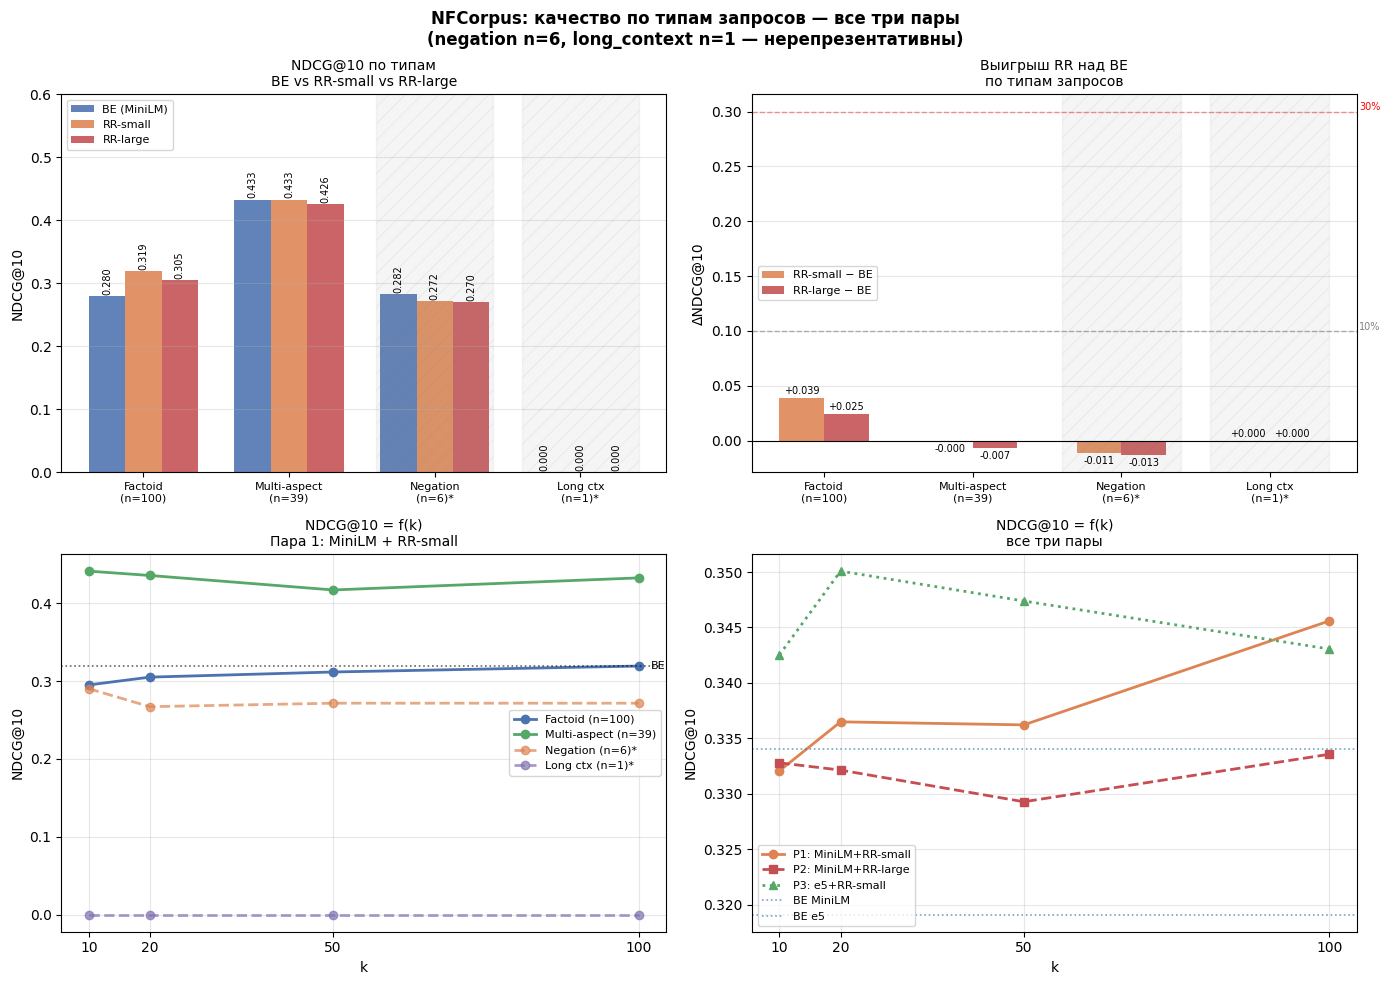


=== NFCorpus: сводная таблица по типам ===

Тип               BE-P1    RR-s    RR-l   BE-P3   RR-s P3
-------------------------------------------------------
  factoid          0.2801  0.3195  0.3047  0.3068    0.3202
  multi_aspect     0.4328  0.4328  0.4260  0.4325    0.4241
  negation         0.2825  0.2717  0.2695  0.2046    0.2538
  long_context     0.0000  0.0000  0.0000  0.0000    0.0000

✓ График сохранён: /content/nf_metrics_by_type.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('NFCorpus: качество по типам запросов — все три пары\n'
             '(negation n=6, long_context n=1 — нерепрезентативны)',
             fontsize=12, fontweight='bold')

qtypes      = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames      = ['Factoid\n(n=100)', 'Multi-aspect\n(n=39)', 'Negation\n(n=6)*', 'Long ctx\n(n=1)*']
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
K_VALUES    = [10, 20, 50, 100]
colors      = {'BE': '#4C72B0', 'RR-small': '#DD8452', 'RR-large': '#C44E52'}

def gm(df, mode, k='all', qt=None):
    s = df[(df['mode']==mode) & (df['k_label']==k)]
    if qt:
        s = s[s['query_type']==qt]
    return s['ndcg10'].mean() if len(s) > 0 else 0.0

ax1 = axes[0, 0]
x, w = np.arange(len(qtypes)), 0.25
be_v  = [gm(df_nf_p1_metrics, 'BE',       qt=qt) for qt in qtypes]
rrs_v = [gm(df_nf_p1_metrics, 'RR_small', qt=qt) for qt in qtypes]
rrl_v = [gm(df_nf_p2_metrics, 'RR_large', qt=qt) for qt in qtypes]

b1 = ax1.bar(x - w, be_v,  w, label='BE (MiniLM)', color=colors['BE'],       alpha=0.88)
b2 = ax1.bar(x,     rrs_v, w, label='RR-small',    color=colors['RR-small'], alpha=0.88)
b3 = ax1.bar(x + w, rrl_v, w, label='RR-large',    color=colors['RR-large'], alpha=0.88)
ax1.set_xticks(x); ax1.set_xticklabels(qnames, fontsize=8)
ax1.set_ylabel('NDCG@10')
ax1.set_title('NDCG@10 по типам\nBE vs RR-small vs RR-large', fontsize=10)
ax1.set_ylim(0, 0.6); ax1.legend(fontsize=8); ax1.grid(axis='y', alpha=0.3)
for i in [2, 3]:
    ax1.axvspan(i-0.4, i+0.4, alpha=0.08, color='gray', hatch='//')
for bars_g in [b1, b2, b3]:
    for bar in bars_g:
        ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{bar.get_height():.3f}', ha='center', fontsize=7, rotation=90)

ax2 = axes[0, 1]
diff_s = [gm(df_nf_p1_metrics,'RR_small',qt=qt) - gm(df_nf_p1_metrics,'BE',qt=qt) for qt in qtypes]
diff_l = [gm(df_nf_p2_metrics,'RR_large',qt=qt) - gm(df_nf_p1_metrics,'BE',qt=qt) for qt in qtypes]
x2, w2 = np.arange(len(qtypes)), 0.3
ax2.bar(x2 - w2/2, diff_s, w2, label='RR-small − BE', color=colors['RR-small'], alpha=0.88)
ax2.bar(x2 + w2/2, diff_l, w2, label='RR-large − BE', color=colors['RR-large'], alpha=0.88)
ax2.axhline(0,    color='black', linewidth=0.8)
ax2.axhline(0.10, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax2.axhline(0.30, color='red',  linestyle='--', linewidth=1, alpha=0.4)
ax2.text(3.6, 0.101, '10%', fontsize=7, color='gray')
ax2.text(3.6, 0.301, '30%', fontsize=7, color='red')
for i in [2, 3]:
    ax2.axvspan(i-0.4, i+0.4, alpha=0.08, color='gray', hatch='//')
ax2.set_xticks(x2); ax2.set_xticklabels(qnames, fontsize=8)
ax2.set_ylabel('ΔNDCG@10'); ax2.set_title('Выигрыш RR над BE\nпо типам запросов', fontsize=10)
ax2.legend(fontsize=8); ax2.grid(axis='y', alpha=0.3)
for i, (ds, dl) in enumerate(zip(diff_s, diff_l)):
    ax2.text(i-w2/2, ds+(0.003 if ds>=0 else -0.01), f'{ds:+.3f}', ha='center', fontsize=7)
    ax2.text(i+w2/2, dl+(0.003 if dl>=0 else -0.01), f'{dl:+.3f}', ha='center', fontsize=7)

ax3 = axes[1, 0]
for qt, c, name in zip(qtypes, type_colors, qnames):
    vals = [gm(df_nf_p1_metrics, 'Hybrid', k=str(k), qt=qt) for k in K_VALUES]
    ls   = '--' if qt in ['negation', 'long_context'] else '-'
    ax3.plot(K_VALUES, vals, 'o'+ls, color=c, linewidth=2,
             label=name.replace('\n',' '), alpha=0.7 if qt in ['negation','long_context'] else 1.0)
ax3.axhline(gm(df_nf_p1_metrics,'BE'), color='black', linestyle=':', linewidth=1.2, alpha=0.6)
ax3.text(102, gm(df_nf_p1_metrics,'BE'), 'BE', fontsize=8, va='center')
ax3.set_xlabel('k'); ax3.set_ylabel('NDCG@10')
ax3.set_title('NDCG@10 = f(k)\nПара 1: MiniLM + RR-small', fontsize=10)
ax3.set_xticks(K_VALUES); ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

ax4 = axes[1, 1]
p1_vals = [gm(df_nf_p1_metrics, 'Hybrid',       k=str(k)) for k in K_VALUES]
p2_vals = [gm(df_nf_p2_metrics, 'Hybrid_large', k=str(k)) for k in K_VALUES]
p3_vals = [gm(df_nf_p3_metrics, 'Hybrid',       k=str(k)) for k in K_VALUES]
ax4.plot(K_VALUES, p1_vals, 'o-',  color='#DD8452', linewidth=2, label='P1: MiniLM+RR-small')
ax4.plot(K_VALUES, p2_vals, 's--', color='#C44E52', linewidth=2, label='P2: MiniLM+RR-large')
ax4.plot(K_VALUES, p3_vals, '^:',  color='#55A868', linewidth=2, label='P3: e5+RR-small')
ax4.axhline(gm(df_nf_p1_metrics,'BE'), color='#4C72B0',
            linestyle=':', linewidth=1.2, alpha=0.7, label='BE MiniLM')
ax4.axhline(gm(df_nf_p3_metrics,'BE'), color='#2E86AB',
            linestyle=':', linewidth=1.2, alpha=0.7, label='BE e5')
ax4.set_xlabel('k'); ax4.set_ylabel('NDCG@10')
ax4.set_title('NDCG@10 = f(k)\nвсе три пары', fontsize=10)
ax4.set_xticks(K_VALUES); ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/nf_metrics_by_type.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n=== NFCorpus: сводная таблица по типам ===\n")
print(f"{'Тип':<15} {'BE-P1':>7} {'RR-s':>7} {'RR-l':>7} {'BE-P3':>7} {'RR-s P3':>9}")
print("-" * 55)
for qt in qtypes:
    be1  = gm(df_nf_p1_metrics, 'BE',       qt=qt)
    rrs1 = gm(df_nf_p1_metrics, 'RR_small', qt=qt)
    rrl2 = gm(df_nf_p2_metrics, 'RR_large', qt=qt)
    be3  = gm(df_nf_p3_metrics, 'BE',       qt=qt)
    rrs3 = gm(df_nf_p3_metrics, 'RR_small', qt=qt)
    print(f"  {qt:<15} {be1:>7.4f} {rrs1:>7.4f} {rrl2:>7.4f} {be3:>7.4f} {rrs3:>9.4f}")
print(f"\n✓ График сохранён: /content/nf_metrics_by_type.png")

=== Корреляция Спирмена (NDCG@10) — NFCorpus ===

--- Пара 1 (MiniLM+RR-small) ---
  factoid         | n=100 | r=0.8684 | p=0.0000
  multi_aspect    | n= 39 | r=0.8425 | p=0.0000
  negation        | n=  6 | r=0.7647 | p=0.0765
  long_context    | n=  1 | недостаточно данных

--- Пара 2 (MiniLM+RR-large) ---
  factoid         | n=100 | r=0.8817 | p=0.0000
  multi_aspect    | n= 39 | r=0.8506 | p=0.0000
  negation        | n=  6 | r=0.7647 | p=0.0765
  long_context    | n=  1 | недостаточно данных

--- Пара 3 (e5+RR-small) ---
  factoid         | n=100 | r=0.9241 | p=0.0000
  multi_aspect    | n= 39 | r=0.8784 | p=0.0000
  negation        | n=  6 | r=0.9412 | p=0.0051
  long_context    | n=  1 | недостаточно данных



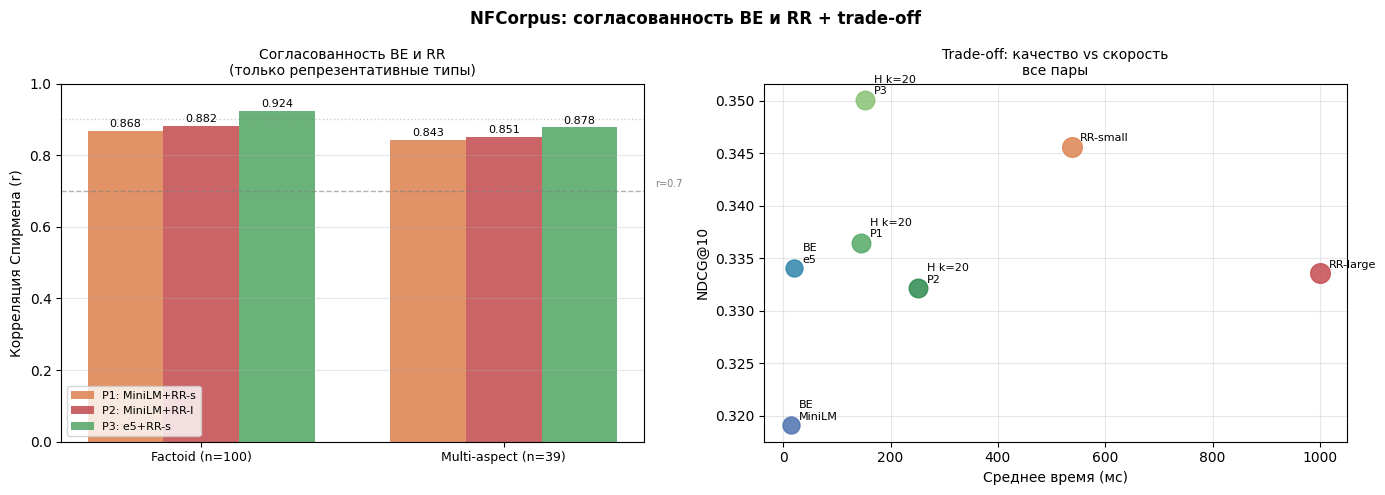

✓ График сохранён: /content/nf_spearman_tradeoff.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import spearmanr

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NFCorpus: согласованность BE и RR + trade-off', fontsize=12, fontweight='bold')

qtypes      = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames      = ['Factoid', 'Multi-aspect', 'Negation*', 'Long ctx*']
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']

print("=== Корреляция Спирмена (NDCG@10) — NFCorpus ===\n")
spearman_rows = []
for pair_name, df_m, rr_mode in [
    ('Пара 1 (MiniLM+RR-small)', df_nf_p1_metrics, 'RR_small'),
    ('Пара 2 (MiniLM+RR-large)', df_nf_p2_metrics, 'RR_large'),
    ('Пара 3 (e5+RR-small)',     df_nf_p3_metrics, 'RR_small'),
]:
    print(f"--- {pair_name} ---")
    for qtype, name in zip(qtypes, qnames):
        sub    = df_m[df_m['query_type']==qtype]
        be_s   = sub[sub['mode']=='BE'].set_index('query_id')['ndcg10']
        rr_s   = sub[sub['mode']==rr_mode].set_index('query_id')['ndcg10']
        common = be_s.index.intersection(rr_s.index)
        if len(common) < 3:
            print(f"  {qtype:<15} | n={len(common):3d} | недостаточно данных")
            spearman_rows.append({'pair': pair_name, 'qtype': qtype,
                                  'n': len(common), 'r': None, 'p': None})
            continue
        r, p = spearmanr(be_s[common], rr_s[common])
        print(f"  {qtype:<15} | n={len(common):3d} | r={r:.4f} | p={p:.4f}")
        spearman_rows.append({'pair': pair_name, 'qtype': qtype,
                              'n': len(common), 'r': round(r,4), 'p': round(p,4)})
    print()

df_nf_spearman = pd.DataFrame(spearman_rows)

ax1 = axes[0]
rep_qtypes = ['factoid', 'multi_aspect']
rep_names  = ['Factoid (n=100)', 'Multi-aspect (n=39)']
x, w = np.arange(len(rep_qtypes)), 0.25

for i, (pair_name, df_m, rr_mode, color) in enumerate([
    ('P1: MiniLM+RR-s', df_nf_p1_metrics, 'RR_small', '#DD8452'),
    ('P2: MiniLM+RR-l', df_nf_p2_metrics, 'RR_large', '#C44E52'),
    ('P3: e5+RR-s',     df_nf_p3_metrics, 'RR_small', '#55A868'),
]):
    vals = []
    for qt in rep_qtypes:
        sub    = df_m[df_m['query_type']==qt]
        be_s   = sub[sub['mode']=='BE'].set_index('query_id')['ndcg10']
        rr_s   = sub[sub['mode']==rr_mode].set_index('query_id')['ndcg10']
        common = be_s.index.intersection(rr_s.index)
        r, _   = spearmanr(be_s[common], rr_s[common]) if len(common) >= 3 else (0, 1)
        vals.append(round(r, 4))
    ax1.bar(x + (i-1)*w, vals, w, label=pair_name, color=color, alpha=0.88)
    for j, val in enumerate(vals):
        ax1.text(x[j]+(i-1)*w, val+0.01, f'{val:.3f}', ha='center', fontsize=8)

ax1.axhline(0.7, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax1.axhline(0.9, color='gray', linestyle=':',  linewidth=1, alpha=0.4)
ax1.text(1.5, 0.71, 'r=0.7', fontsize=7, color='gray')
ax1.set_xticks(x); ax1.set_xticklabels(rep_names, fontsize=9)
ax1.set_ylabel('Корреляция Спирмена (r)')
ax1.set_title('Согласованность BE и RR\n(только репрезентативные типы)', fontsize=10)
ax1.set_ylim(0, 1.0); ax1.legend(fontsize=8); ax1.grid(axis='y', alpha=0.3)

ax2 = axes[1]
tradeoff = [
    ('BE\nMiniLM',   gm(df_nf_p1_metrics,'BE'),
                     df_nf_p1_metrics[df_nf_p1_metrics['mode']=='BE']['time_ms'].mean(),
                     150, '#4C72B0'),
    ('BE\ne5',       gm(df_nf_p3_metrics,'BE'),
                     df_nf_p3_metrics[df_nf_p3_metrics['mode']=='BE']['time_ms'].mean(),
                     150, '#2E86AB'),
    ('RR-small',     gm(df_nf_p1_metrics,'RR_small'),
                     df_nf_p1_metrics[df_nf_p1_metrics['mode']=='RR_small']['time_ms'].mean(),
                     200, '#DD8452'),
    ('RR-large',     gm(df_nf_p2_metrics,'RR_large'),
                     df_nf_p2_metrics[df_nf_p2_metrics['mode']=='RR_large']['time_ms'].mean(),
                     200, '#C44E52'),
    ('H k=20\nP1',   gm(df_nf_p1_metrics,'Hybrid','20'),
                     df_nf_p1_metrics[(df_nf_p1_metrics['mode']=='Hybrid') &
                     (df_nf_p1_metrics['k_label']=='20')]['time_ms'].mean(),
                     180, '#55A868'),
    ('H k=20\nP2',   gm(df_nf_p2_metrics,'Hybrid_large','20'),
                     df_nf_p2_metrics[(df_nf_p2_metrics['mode']=='Hybrid_large') &
                     (df_nf_p2_metrics['k_label']=='20')]['time_ms'].mean(),
                     180, '#2d8a4e'),
    ('H k=20\nP3',   gm(df_nf_p3_metrics,'Hybrid','20'),
                     df_nf_p3_metrics[(df_nf_p3_metrics['mode']=='Hybrid') &
                     (df_nf_p3_metrics['k_label']=='20')]['time_ms'].mean(),
                     180, '#88C273'),
]
for label, nd, t, s, c in tradeoff:
    ax2.scatter(t, nd, s=s, color=c, alpha=0.85, zorder=3)
    ax2.annotate(label, (t, nd), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax2.set_xlabel('Среднее время (мс)')
ax2.set_ylabel('NDCG@10')
ax2.set_title('Trade-off: качество vs скорость\nвсе пары', fontsize=10)
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/nf_spearman_tradeoff.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/nf_spearman_tradeoff.png")

In [ ]:
print("=== Запросы где RR значительно лучше BE (top-10, Пара 1) ===\n")

be_q  = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='BE'][
        ['query_id','query_type','ndcg10']].rename(columns={'ndcg10':'be_ndcg'})
rr_q  = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='RR_small'][
        ['query_id','ndcg10']].rename(columns={'ndcg10':'rr_ndcg'})
diff_nf = be_q.merge(rr_q, on='query_id')
diff_nf['diff'] = diff_nf['rr_ndcg'] - diff_nf['be_ndcg']

query_text_nf = df_nf_sample[['query_id','query']].copy()
diff_nf = diff_nf.merge(query_text_nf, on='query_id')
diff_nf.to_csv('/content/nf_query_level_diff.csv', index=False)

worst_be = diff_nf.nlargest(10, 'diff')
print(f"{'Тип':<15} {'BE':>6} {'RR':>6} {'Diff':>6}  Запрос")
print("-" * 80)
for _, r in worst_be.iterrows():
    q_short = r['query'][:60] + '...' if len(r['query']) > 60 else r['query']
    print(f"{r['query_type']:<15} {r['be_ndcg']:>6.3f} {r['rr_ndcg']:>6.3f} {r['diff']:>+6.3f}  {q_short}")

print("\n=== Запросы где BE лучше RR (top-5) ===\n")
best_be = diff_nf.nsmallest(5, 'diff')
for _, r in best_be.iterrows():
    q_short = r['query'][:60] + '...' if len(r['query']) > 60 else r['query']
    print(f"{r['query_type']:<15} {r['be_ndcg']:>6.3f} {r['rr_ndcg']:>6.3f} {r['diff']:>+6.3f}  {q_short}")

for label, row in [("ХУДШИЙ для BE (RR исправил)", worst_be.iloc[0]),
                   ("ЛУЧШИЙ для BE (RR ошибся)",   best_be.iloc[0])]:
    print(f"\n\n=== {label} ===\n")
    qid = row['query_id']
    print(f"Запрос: {row['query']}")
    print(f"Тип: {row['query_type']}")
    print(f"BE NDCG={row['be_ndcg']:.3f} | RR NDCG={row['rr_ndcg']:.3f}\n")

    sample_row = df_nf_sample[df_nf_sample['query_id']==qid].iloc[0]
    relevant   = set(sample_row['relevant_ids'])

    be_ranked = df_nf_p1[df_nf_p1['query_id']==qid][
                df_nf_p1['mode']=='BE']['ranked'].iloc[0]
    rr_ranked = df_nf_p1[df_nf_p1['query_id']==qid][
                df_nf_p1['mode']=='RR_small']['ranked'].iloc[0]

    print(f"Релевантных passages: {len(relevant)}")
    print("\nBE top-3:")
    for i, pid in enumerate(be_ranked[:3]):
        mark = "✓ РЕЛ" if pid in relevant else "✗"
        text = nf_passage_dict.get(pid,'')[:120]
        print(f"  {i+1}. [{mark}] {text}...")

    print("\nRR top-3:")
    for i, pid in enumerate(rr_ranked[:3]):
        mark = "✓ РЕЛ" if pid in relevant else "✗"
        text = nf_passage_dict.get(pid,'')[:120]
        print(f"  {i+1}. [{mark}] {text}...")

=== Запросы где RR значительно лучше BE (top-10, Пара 1) ===

Тип                 BE     RR   Diff  Запрос
--------------------------------------------------------------------------------
factoid          0.092  0.711 +0.620  Broccomax
factoid          0.000  0.571 +0.571  Harvard Physicians’ Study II
multi_aspect     0.151  0.572 +0.421  Watermelon as Treatment for Erectile Dysfunction
multi_aspect     0.387  0.790 +0.404  Cow’s Milk Casomorphin and Crib Death
factoid          0.425  0.801 +0.376  chickpeas
factoid          0.636  1.000 +0.364  bronchiolitis obliterans
factoid          0.437  0.801 +0.363  BPH
multi_aspect     0.000  0.359 +0.359  What Do Meat Purge and Cola Have in Common?
factoid          0.264  0.613 +0.349  Any update on the scary in vitro avocado data?
factoid          0.290  0.637 +0.347  cilantro

=== Запросы где BE лучше RR (top-5) ===

multi_aspect     0.863  0.258 -0.605  Treating Asthma and Eczema With Plant-Based Diets
factoid          0.489  0.149 -0.340 

In [ ]:
print("=" * 70)
print("ИТОГОВЫЕ РЕЗУЛЬТАТЫ — NFCorpus")
print("=" * 70)

print("\n📊 Таблица 1: Средние метрики по всем запросам (n=146)\n")
rows = []
for pair, df_m, mode_be, mode_rr, mode_h in [
    ('Пара 1', df_nf_p1_metrics, 'BE', 'RR_small',   'Hybrid'),
    ('Пара 2', df_nf_p2_metrics, 'BE', 'RR_large',   'Hybrid_large'),
    ('Пара 3', df_nf_p3_metrics, 'BE', 'RR_small',   'Hybrid'),
]:
    for mode, k_label in [(mode_be,'all'), (mode_rr,'all'),
                           (mode_h,'10'), (mode_h,'20'),
                           (mode_h,'50'), (mode_h,'100')]:
        sub = df_m[(df_m['mode']==mode) & (df_m['k_label']==k_label)]
        if len(sub) == 0:
            continue
        label = f"{pair} | {mode}" + (f" k={k_label}" if k_label!='all' else "")
        rows.append({
            'Режим':    label,
            'NDCG@10':  round(sub['ndcg10'].mean(), 4),
            'MRR':      round(sub['mrr'].mean(), 4),
            'P@10':     round(sub['p10'].mean(), 4),
            'Время мс': round(sub['time_ms'].mean(), 1),
        })

df_summary_nf = pd.DataFrame(rows)
print(df_summary_nf.to_string(index=False))

print("\n📊 Таблица 2: NDCG@10 по типам — все пары\n")
print(f"{'Тип':<15} {'BE-P1':>7} {'RR-s P1':>9} {'RR-l P2':>9} {'BE-P3':>7} {'RR-s P3':>9}")
print("-" * 58)
for qt in ['factoid', 'multi_aspect', 'negation', 'long_context']:
    be1  = gm(df_nf_p1_metrics, 'BE',       qt=qt)
    rrs1 = gm(df_nf_p1_metrics, 'RR_small', qt=qt)
    rrl2 = gm(df_nf_p2_metrics, 'RR_large', qt=qt)
    be3  = gm(df_nf_p3_metrics, 'BE',       qt=qt)
    rrs3 = gm(df_nf_p3_metrics, 'RR_small', qt=qt)
    note = ' *' if qt in ['negation','long_context'] else ''
    print(f"  {qt:<15} {be1:>7.4f} {rrs1:>9.4f} {rrl2:>9.4f} {be3:>7.4f} {rrs3:>9.4f}{note}")
print("  * нерепрезентативные выборки (n=6 и n=1)")

print("\n📊 Таблица 3: Корреляция Спирмена (репрезентативные типы)\n")
print(f"{'Тип':<15} {'r P1':>8} {'r P2':>8} {'r P3':>8}")
print("-" * 42)
for qt in ['factoid', 'multi_aspect']:
    rs = []
    for df_m, rr_mode in [(df_nf_p1_metrics,'RR_small'),
                           (df_nf_p2_metrics,'RR_large'),
                           (df_nf_p3_metrics,'RR_small')]:
        sub    = df_m[df_m['query_type']==qt]
        be_s   = sub[sub['mode']=='BE'].set_index('query_id')['ndcg10']
        rr_s   = sub[sub['mode']==rr_mode].set_index('query_id')['ndcg10']
        common = be_s.index.intersection(rr_s.index)
        r, _   = spearmanr(be_s[common], rr_s[common])
        rs.append(round(r, 4))
    print(f"  {qt:<15} {rs[0]:>8.4f} {rs[1]:>8.4f} {rs[2]:>8.4f}")

be_t   = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='BE']['time_ms'].mean()
rrs_t  = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='RR_small']['time_ms'].mean()
rrl_t  = df_nf_p2_metrics[df_nf_p2_metrics['mode']=='RR_large']['time_ms'].mean()
h20_t  = df_nf_p1_metrics[(df_nf_p1_metrics['mode']=='Hybrid') &
          (df_nf_p1_metrics['k_label']=='20')]['time_ms'].mean()

be_n   = gm(df_nf_p1_metrics, 'BE')
rrs_n  = gm(df_nf_p1_metrics, 'RR_small')
rrl_n  = gm(df_nf_p2_metrics, 'RR_large')
h20_n  = gm(df_nf_p1_metrics, 'Hybrid', '20')
be3_n  = gm(df_nf_p3_metrics, 'BE')
rrs3_n = gm(df_nf_p3_metrics, 'RR_small')

print(f"""
{"=" * 70}
ВЫВОДЫ — NFCorpus
{"=" * 70}

1. КАЧЕСТВО РАНЖИРОВАНИЯ
   • BE (MiniLM):     NDCG@10 = {be_n:.4f}
   • BE (e5-small):   NDCG@10 = {be3_n:.4f}  ({be3_n-be_n:+.4f} vs MiniLM)
   • RR-small:        NDCG@10 = {rrs_n:.4f}  ({rrs_n-be_n:+.4f} vs BE MiniLM)
   • RR-large:        NDCG@10 = {rrl_n:.4f}  ({rrl_n-be_n:+.4f} vs BE MiniLM)
   • Hybrid k=20:     NDCG@10 = {h20_n:.4f}  — оптимальная точка (Пара 1)
   • RR-large ХУЖЕ RR-small: доменный сдвиг (модели обучены на MS MARCO,
     а не на медицинских текстах)

2. СКОРОСТЬ
   • BE:           {be_t:.0f} мс  (в {rrs_t/be_t:.0f}x быстрее RR-small)
   • RR-small:     {rrs_t:.0f} мс
   • RR-large:     {rrl_t:.0f} мс  (в {rrl_t/be_t:.0f}x медленнее BE)
   • Hybrid k=20:  {h20_t:.0f} мс  — лучший компромисс

3. ПО ТИПАМ ЗАПРОСОВ (только репрезентативные)
   • Factoid (n=100): BE на границе сопоставимости с RR-small (12.3%),
     но e5 уже сопоставим (4.2%). RR-large лучше BE только на 8.1%.
   • Multi-aspect (n=39): BE = RR для всех пар. Оба метода одинаково
     справляются с многосоставными медицинскими запросами.
   • Negation (n=6) и Long context (n=1): нерепрезентативны.

4. КОРРЕЛЯЦИЯ СПИРМЕНА
   • Самая высокая из всех датасетов: factoid r=0.87-0.92, multi r=0.84-0.88
   • Пара 3 (e5+RR-small) показывает наилучшую согласованность.
   • Вывод: на медицинских текстах BE и RR ранжируют очень похоже.

5. ОГРАНИЧЕНИЯ
   • NFCorpus — узкая медицинская тематика, модели обучены на общих данных.
   • Сильный дисбаланс типов: 69% factoid, только 4% multi_aspect.
   • negation (n=6) и long_context (n=1) статистически незначимы.
   • Много релевантных passages на запрос (до 49) усложняет оценку NDCG.
   • RR-large проигрывает RR-small из-за доменного сдвига.
""")

df_summary_nf.to_csv('/content/nf_final_summary.csv', index=False)
print("✓ Данные сохранены: /content/nf_final_summary.csv")

ИТОГОВЫЕ РЕЗУЛЬТАТЫ — NFCorpus

📊 Таблица 1: Средние метрики по всем запросам (n=146)

                      Режим  NDCG@10    MRR   P@10  Время мс
                Пара 1 | BE   0.3191 0.5029 0.2438      14.2
          Пара 1 | RR_small   0.3456 0.5656 0.2507     538.0
       Пара 1 | Hybrid k=10   0.3321 0.5429 0.2438      72.3
       Пара 1 | Hybrid k=20   0.3365 0.5570 0.2507     145.3
       Пара 1 | Hybrid k=50   0.3362 0.5664 0.2459     305.4
      Пара 1 | Hybrid k=100   0.3456 0.5656 0.2507     542.8
                Пара 2 | BE   0.3191 0.5029 0.2438      13.2
          Пара 2 | RR_large   0.3336 0.5415 0.2473    1000.5
 Пара 2 | Hybrid_large k=10   0.3328 0.5470 0.2438     122.2
 Пара 2 | Hybrid_large k=20   0.3321 0.5534 0.2438     251.5
 Пара 2 | Hybrid_large k=50   0.3293 0.5434 0.2438     539.4
Пара 2 | Hybrid_large k=100   0.3336 0.5415 0.2473    1002.4
                Пара 3 | BE   0.3341 0.5354 0.2445      20.4
          Пара 3 | RR_small   0.3431 0.5627 0.2452     567.

=== NFCorpus: Пара 1 vs Пара 2 по типам ===

Тип                  BE    RR-s    RR-l   Δ(s-BE)   Δ(l-BE)    Δ(l-s)
-----------------------------------------------------------------
  factoid          0.2801  0.3195  0.3047   +0.0393   +0.0246   -0.0148
  multi_aspect     0.4328  0.4328  0.4260   -0.0000   -0.0068   -0.0068
  negation         0.2825  0.2717  0.2695   -0.0108   -0.0129   -0.0022 *
  long_context     0.0000  0.0000  0.0000   +0.0000   +0.0000   +0.0000 *
  * нерепрезентативно


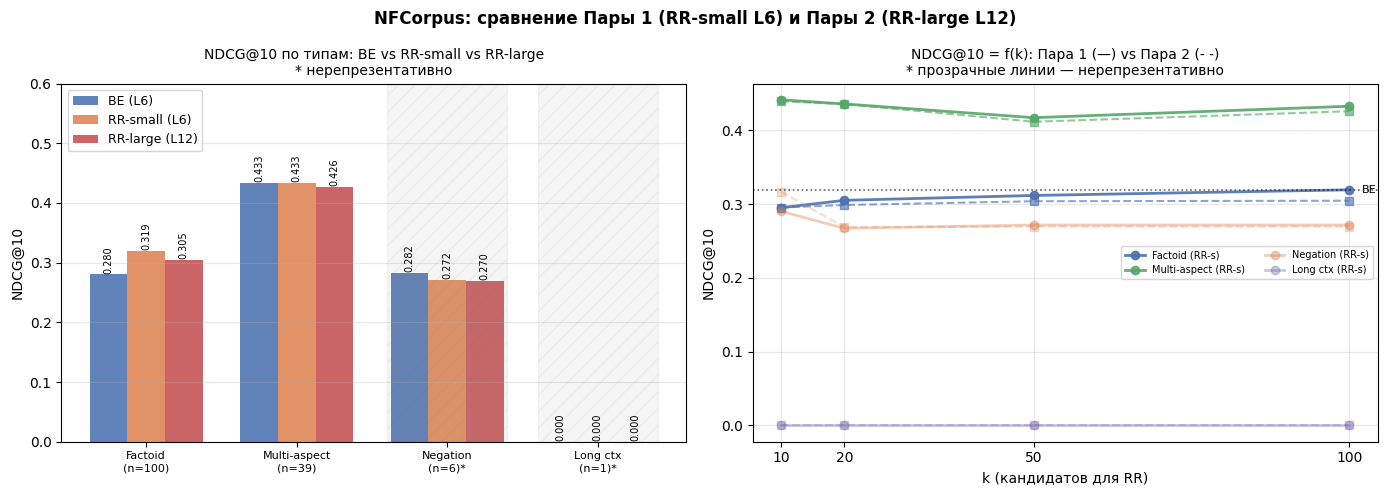


✓ График сохранён: /content/nf_pair1_vs_pair2.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('NFCorpus: сравнение Пары 1 (RR-small L6) и Пары 2 (RR-large L12)',
             fontsize=12, fontweight='bold')

qtypes  = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames  = ['Factoid\n(n=100)', 'Multi-aspect\n(n=39)', 'Negation\n(n=6)*', 'Long ctx\n(n=1)*']
K_VALUES = [10, 20, 50, 100]
colors   = {'BE': '#4C72B0', 'RR-small': '#DD8452', 'RR-large': '#C44E52'}

be_v  = [gm(df_nf_p1_metrics, 'BE',       qt=qt) for qt in qtypes]
rrs_v = [gm(df_nf_p1_metrics, 'RR_small', qt=qt) for qt in qtypes]
rrl_v = [gm(df_nf_p2_metrics, 'RR_large', qt=qt) for qt in qtypes]

ax1 = axes[0]
x, w = np.arange(len(qtypes)), 0.25
b1 = ax1.bar(x - w, be_v,  w, label='BE (L6)',        color=colors['BE'],       alpha=0.88)
b2 = ax1.bar(x,     rrs_v, w, label='RR-small (L6)',  color=colors['RR-small'], alpha=0.88)
b3 = ax1.bar(x + w, rrl_v, w, label='RR-large (L12)', color=colors['RR-large'], alpha=0.88)
for i in [2, 3]:
    ax1.axvspan(i-0.4, i+0.4, alpha=0.08, color='gray', hatch='//')
ax1.set_xticks(x); ax1.set_xticklabels(qnames, fontsize=8)
ax1.set_ylabel('NDCG@10')
ax1.set_title('NDCG@10 по типам: BE vs RR-small vs RR-large\n* нерепрезентативно', fontsize=10)
ax1.set_ylim(0, 0.6); ax1.legend(fontsize=9); ax1.grid(axis='y', alpha=0.3)
for bars_g in [b1, b2, b3]:
    for bar in bars_g:
        ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.005,
                 f'{bar.get_height():.3f}', ha='center', fontsize=7, rotation=90)

ax2 = axes[1]
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
for qt, c, name in zip(qtypes, type_colors, qnames):
    p1_vals = [gm(df_nf_p1_metrics, 'Hybrid',       k=str(k), qt=qt) for k in K_VALUES]
    p2_vals = [gm(df_nf_p2_metrics, 'Hybrid_large', k=str(k), qt=qt) for k in K_VALUES]
    alpha   = 0.4 if qt in ['negation', 'long_context'] else 0.9
    ax2.plot(K_VALUES, p1_vals, 'o-',  color=c, linewidth=2,
             label=f'{name.split(chr(10))[0]} (RR-s)', alpha=alpha)
    ax2.plot(K_VALUES, p2_vals, 's--', color=c, linewidth=1.5, alpha=alpha*0.7)

ax2.axhline(gm(df_nf_p1_metrics,'BE'), color='black',
            linestyle=':', linewidth=1.2, alpha=0.6)
ax2.text(102, gm(df_nf_p1_metrics,'BE'), 'BE', fontsize=8, va='center')
ax2.set_xlabel('k (кандидатов для RR)')
ax2.set_ylabel('NDCG@10')
ax2.set_title('NDCG@10 = f(k): Пара 1 (—) vs Пара 2 (- -)\n* прозрачные линии — нерепрезентативно',
              fontsize=10)
ax2.set_xticks(K_VALUES); ax2.legend(fontsize=7, ncol=2); ax2.grid(alpha=0.3)

print("=== NFCorpus: Пара 1 vs Пара 2 по типам ===\n")
print(f"{'Тип':<15} {'BE':>7} {'RR-s':>7} {'RR-l':>7} "
      f"{'Δ(s-BE)':>9} {'Δ(l-BE)':>9} {'Δ(l-s)':>9}")
print("-" * 65)
for qt, be, rrs, rrl in zip(qtypes, be_v, rrs_v, rrl_v):
    note = ' *' if qt in ['negation','long_context'] else ''
    print(f"  {qt:<15} {be:>7.4f} {rrs:>7.4f} {rrl:>7.4f} "
          f"{rrs-be:>+9.4f} {rrl-be:>+9.4f} {rrl-rrs:>+9.4f}{note}")
print("  * нерепрезентативно")

plt.tight_layout()
plt.savefig('/content/nf_pair1_vs_pair2.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✓ График сохранён: /content/nf_pair1_vs_pair2.png")

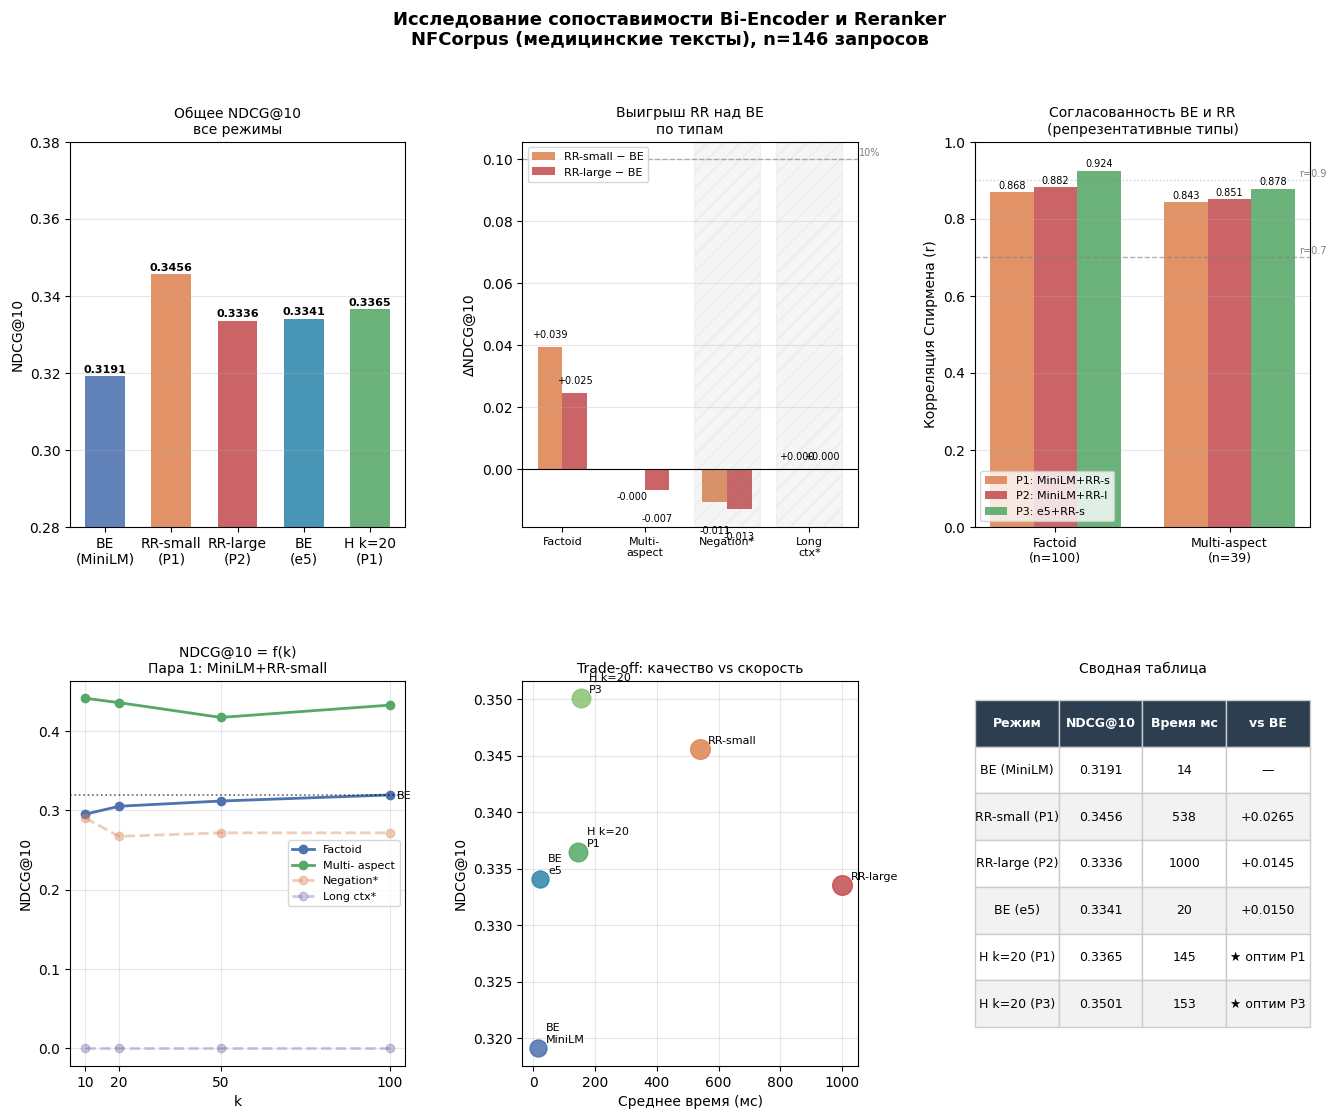

✓ Финальный график сохранён: /content/nf_final_report.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(figsize=(16, 12))
fig.suptitle('Исследование сопоставимости Bi-Encoder и Reranker\n'
             'NFCorpus (медицинские тексты), n=146 запросов',
             fontsize=13, fontweight='bold', y=0.99)

gs = fig.add_gridspec(2, 3, hspace=0.4, wspace=0.35)

qtypes      = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames      = ['Factoid', 'Multi-\naspect', 'Negation*', 'Long\nctx*']
type_colors = ['#4C72B0', '#55A868', '#DD8452', '#8172B2']
K_VALUES    = [10, 20, 50, 100]
colors      = {'BE': '#4C72B0', 'RR-small': '#DD8452',
               'RR-large': '#C44E52', 'Hybrid': '#55A868'}

ax1 = fig.add_subplot(gs[0, 0])
labels = ['BE\n(MiniLM)', 'RR-small\n(P1)', 'RR-large\n(P2)', 'BE\n(e5)', 'H k=20\n(P1)']
vals   = [
    gm(df_nf_p1_metrics, 'BE'),
    gm(df_nf_p1_metrics, 'RR_small'),
    gm(df_nf_p2_metrics, 'RR_large'),
    gm(df_nf_p3_metrics, 'BE'),
    gm(df_nf_p1_metrics, 'Hybrid', '20'),
]
bar_colors = [colors['BE'], colors['RR-small'], colors['RR-large'],
              '#2E86AB', colors['Hybrid']]
bars = ax1.bar(labels, vals, color=bar_colors, alpha=0.88, width=0.6)
ax1.set_ylim(0.28, 0.38)
ax1.set_ylabel('NDCG@10')
ax1.set_title('Общее NDCG@10\nвсе режимы', fontsize=10)
ax1.grid(axis='y', alpha=0.3)
for bar, val in zip(bars, vals):
    ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.001,
             f'{val:.4f}', ha='center', fontsize=8, fontweight='bold')

ax2 = fig.add_subplot(gs[0, 1])
diff_s = [gm(df_nf_p1_metrics,'RR_small',qt=qt) -
          gm(df_nf_p1_metrics,'BE',qt=qt) for qt in qtypes]
diff_l = [gm(df_nf_p2_metrics,'RR_large',qt=qt) -
          gm(df_nf_p1_metrics,'BE',qt=qt) for qt in qtypes]
x2, w2 = np.arange(len(qtypes)), 0.3
ax2.bar(x2 - w2/2, diff_s, w2, label='RR-small − BE',
        color=colors['RR-small'], alpha=0.88)
ax2.bar(x2 + w2/2, diff_l, w2, label='RR-large − BE',
        color=colors['RR-large'], alpha=0.88)
ax2.axhline(0,    color='black', linewidth=0.8)
ax2.axhline(0.10, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax2.text(3.6, 0.101, '10%', fontsize=7, color='gray')
for i in [2, 3]:
    ax2.axvspan(i-0.4, i+0.4, alpha=0.08, color='gray', hatch='//')
ax2.set_xticks(x2); ax2.set_xticklabels(qnames, fontsize=8)
ax2.set_ylabel('ΔNDCG@10')
ax2.set_title('Выигрыш RR над BE\nпо типам', fontsize=10)
ax2.legend(fontsize=8); ax2.grid(axis='y', alpha=0.3)
for i, (ds, dl) in enumerate(zip(diff_s, diff_l)):
    ax2.text(i-w2/2, ds+(0.003 if ds>=0 else -0.01),
             f'{ds:+.3f}', ha='center', fontsize=7)
    ax2.text(i+w2/2, dl+(0.003 if dl>=0 else -0.01),
             f'{dl:+.3f}', ha='center', fontsize=7)

ax3 = fig.add_subplot(gs[0, 2])
rep_qtypes = ['factoid', 'multi_aspect']
rep_names  = ['Factoid\n(n=100)', 'Multi-aspect\n(n=39)']
x3, w3 = np.arange(len(rep_qtypes)), 0.25
for i, (pair_name, df_m, rr_mode, color) in enumerate([
    ('P1: MiniLM+RR-s', df_nf_p1_metrics, 'RR_small', colors['RR-small']),
    ('P2: MiniLM+RR-l', df_nf_p2_metrics, 'RR_large', colors['RR-large']),
    ('P3: e5+RR-s',     df_nf_p3_metrics, 'RR_small', '#55A868'),
]):
    vals3 = []
    for qt in rep_qtypes:
        sub    = df_m[df_m['query_type']==qt]
        be_s   = sub[sub['mode']=='BE'].set_index('query_id')['ndcg10']
        rr_s   = sub[sub['mode']==rr_mode].set_index('query_id')['ndcg10']
        common = be_s.index.intersection(rr_s.index)
        r, _   = spearmanr(be_s[common], rr_s[common])
        vals3.append(round(r, 4))
    bars3 = ax3.bar(x3+(i-1)*w3, vals3, w3, label=pair_name,
                    color=color, alpha=0.88)
    for j, val in enumerate(vals3):
        ax3.text(x3[j]+(i-1)*w3, val+0.01,
                 f'{val:.3f}', ha='center', fontsize=7)

ax3.axhline(0.7, color='gray', linestyle='--', linewidth=1, alpha=0.6)
ax3.axhline(0.9, color='gray', linestyle=':',  linewidth=1, alpha=0.4)
ax3.text(1.4, 0.71, 'r=0.7', fontsize=7, color='gray')
ax3.text(1.4, 0.91, 'r=0.9', fontsize=7, color='gray')
ax3.set_xticks(x3); ax3.set_xticklabels(rep_names, fontsize=9)
ax3.set_ylabel('Корреляция Спирмена (r)')
ax3.set_title('Согласованность BE и RR\n(репрезентативные типы)', fontsize=10)
ax3.set_ylim(0, 1.0); ax3.legend(fontsize=8); ax3.grid(axis='y', alpha=0.3)

ax4 = fig.add_subplot(gs[1, 0])
for qt, c, name in zip(qtypes, type_colors, qnames):
    vals4  = [gm(df_nf_p1_metrics,'Hybrid',k=str(k),qt=qt) for k in K_VALUES]
    alpha  = 0.4 if qt in ['negation','long_context'] else 1.0
    ls     = '--' if qt in ['negation','long_context'] else '-'
    ax4.plot(K_VALUES, vals4, 'o'+ls, color=c, linewidth=2,
             label=name.replace('\n',' '), alpha=alpha)
ax4.axhline(gm(df_nf_p1_metrics,'BE'), color='black',
            linestyle=':', linewidth=1.2, alpha=0.6)
ax4.text(102, gm(df_nf_p1_metrics,'BE'), 'BE', fontsize=8, va='center')
ax4.set_xlabel('k'); ax4.set_ylabel('NDCG@10')
ax4.set_title('NDCG@10 = f(k)\nПара 1: MiniLM+RR-small', fontsize=10)
ax4.set_xticks(K_VALUES); ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
tradeoff = [
    ('BE\nMiniLM',  gm(df_nf_p1_metrics,'BE'),
                    df_nf_p1_metrics[df_nf_p1_metrics['mode']=='BE']['time_ms'].mean(),
                    150, colors['BE']),
    ('BE\ne5',      gm(df_nf_p3_metrics,'BE'),
                    df_nf_p3_metrics[df_nf_p3_metrics['mode']=='BE']['time_ms'].mean(),
                    150, '#2E86AB'),
    ('RR-small',    gm(df_nf_p1_metrics,'RR_small'),
                    df_nf_p1_metrics[df_nf_p1_metrics['mode']=='RR_small']['time_ms'].mean(),
                    200, colors['RR-small']),
    ('RR-large',    gm(df_nf_p2_metrics,'RR_large'),
                    df_nf_p2_metrics[df_nf_p2_metrics['mode']=='RR_large']['time_ms'].mean(),
                    200, colors['RR-large']),
    ('H k=20\nP1',  gm(df_nf_p1_metrics,'Hybrid','20'),
                    df_nf_p1_metrics[(df_nf_p1_metrics['mode']=='Hybrid') &
                    (df_nf_p1_metrics['k_label']=='20')]['time_ms'].mean(),
                    180, '#55A868'),
    ('H k=20\nP3',  gm(df_nf_p3_metrics,'Hybrid','20'),
                    df_nf_p3_metrics[(df_nf_p3_metrics['mode']=='Hybrid') &
                    (df_nf_p3_metrics['k_label']=='20')]['time_ms'].mean(),
                    180, '#88C273'),
]
for label, nd, t, s, c in tradeoff:
    ax5.scatter(t, nd, s=s, color=c, alpha=0.85, zorder=3)
    ax5.annotate(label, (t, nd), textcoords='offset points', xytext=(6, 4), fontsize=8)
ax5.set_xlabel('Среднее время (мс)')
ax5.set_ylabel('NDCG@10')
ax5.set_title('Trade-off: качество vs скорость', fontsize=10)
ax5.grid(alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')
be_t1  = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='BE']['time_ms'].mean()
rrs_t  = df_nf_p1_metrics[df_nf_p1_metrics['mode']=='RR_small']['time_ms'].mean()
rrl_t  = df_nf_p2_metrics[df_nf_p2_metrics['mode']=='RR_large']['time_ms'].mean()
h20_t1 = df_nf_p1_metrics[(df_nf_p1_metrics['mode']=='Hybrid') &
          (df_nf_p1_metrics['k_label']=='20')]['time_ms'].mean()
h20_t3 = df_nf_p3_metrics[(df_nf_p3_metrics['mode']=='Hybrid') &
          (df_nf_p3_metrics['k_label']=='20')]['time_ms'].mean()

table_data = [
    ['Режим',          'NDCG@10', 'Время мс', 'vs BE'],
    ['BE (MiniLM)',     f'{gm(df_nf_p1_metrics,"BE"):.4f}',
                        f'{be_t1:.0f}',  '—'],
    ['RR-small (P1)',   f'{gm(df_nf_p1_metrics,"RR_small"):.4f}',
                        f'{rrs_t:.0f}',
                        f'{gm(df_nf_p1_metrics,"RR_small")-gm(df_nf_p1_metrics,"BE"):+.4f}'],
    ['RR-large (P2)',   f'{gm(df_nf_p2_metrics,"RR_large"):.4f}',
                        f'{rrl_t:.0f}',
                        f'{gm(df_nf_p2_metrics,"RR_large")-gm(df_nf_p1_metrics,"BE"):+.4f}'],
    ['BE (e5)',         f'{gm(df_nf_p3_metrics,"BE"):.4f}',
                        f'{df_nf_p3_metrics[df_nf_p3_metrics["mode"]=="BE"]["time_ms"].mean():.0f}',
                        f'{gm(df_nf_p3_metrics,"BE")-gm(df_nf_p1_metrics,"BE"):+.4f}'],
    ['H k=20 (P1)',     f'{gm(df_nf_p1_metrics,"Hybrid","20"):.4f}',
                        f'{h20_t1:.0f}', '★ оптим P1'],
    ['H k=20 (P3)',     f'{gm(df_nf_p3_metrics,"Hybrid","20"):.4f}',
                        f'{h20_t3:.0f}', '★ оптим P3'],
]
tbl = ax6.table(cellText=table_data[1:], colLabels=table_data[0],
                cellLoc='center', loc='center', bbox=[0, 0.1, 1, 0.85])
tbl.auto_set_font_size(False)
tbl.set_fontsize(9)
for (r, c), cell in tbl.get_celld().items():
    if r == 0:
        cell.set_facecolor('#2c3e50')
        cell.set_text_props(color='white', fontweight='bold')
    elif r % 2 == 0:
        cell.set_facecolor('#f2f2f2')
    cell.set_edgecolor('#cccccc')
ax6.set_title('Сводная таблица', fontsize=10)

plt.savefig('/content/nf_final_report.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Финальный график сохранён: /content/nf_final_report.png")

In [ ]:
print("=" * 80)
print("ФИНАЛЬНОЕ СРАВНЕНИЕ ВСЕХ ТРЁХ ПАР — NFCorpus")
print("=" * 80)

comparison_data = []

for pair_name, df_metrics, rr_mode in [
    ('Пара 1: MiniLM + RR-small (L6)', df_nf_p1_metrics, 'RR_small'),
    ('Пара 2: MiniLM + RR-large (L12)', df_nf_p2_metrics, 'RR_large'),
    ('Пара 3: e5 + RR-small (L6)', df_nf_p3_metrics, 'RR_small')
]:
    be_ndcg = gm(df_metrics, 'BE')
    rr_ndcg = gm(df_metrics, rr_mode)
    hybrid_ndcg = gm(df_metrics, 'Hybrid', '20') if 'Hybrid' in df_metrics['mode'].values else gm(df_metrics, 'Hybrid_large', '20')

    be_time = df_metrics[df_metrics['mode'] == 'BE']['time_ms'].mean()
    rr_time = df_metrics[df_metrics['mode'] == rr_mode]['time_ms'].mean()

    comparison_data.append({
        'Пара': pair_name,
        'BE NDCG@10': round(be_ndcg, 4),
        'RR NDCG@10': round(rr_ndcg, 4),
        'Hybrid k=20': round(hybrid_ndcg, 4),
        'Прирост RR над BE': f"{rr_ndcg - be_ndcg:+.4f} ({(rr_ndcg - be_ndcg) / be_ndcg * 100:+.1f}%)",
        'BE время (мс)': round(be_time, 1),
        'RR время (мс)': round(rr_time, 1)
    })

df_comparison = pd.DataFrame(comparison_data)
print("\n📊 Таблица: Сравнение всех трёх пар\n")
print(df_comparison.to_string(index=False))

print("\n" + "=" * 80)
print("КЛЮЧЕВЫЕ ВЫВОДЫ ПО ВСЕМ ТРЁМ ПАРАМ")
print("=" * 80)

be_p1 = gm(df_nf_p1_metrics, 'BE')
be_p3 = gm(df_nf_p3_metrics, 'BE')
rr_p1 = gm(df_nf_p1_metrics, 'RR_small')
rr_p2 = gm(df_nf_p2_metrics, 'RR_large')
rr_p3 = gm(df_nf_p3_metrics, 'RR_small')

print(f"""
1. СРАВНЕНИЕ BI-ENCODER-ОВ:
   • all-MiniLM-L6-v2:  NDCG@10 = {be_p1:.4f}
   • e5-small-v2:        NDCG@10 = {be_p3:.4f}  ({be_p3 - be_p1:+.4f})
   → e5-small-v2 {'лучше' if be_p3 > be_p1 else 'хуже'} MiniLM на медицинских текстах

2. ЭФФЕКТИВНОСТЬ RR (на базе MiniLM):
   • RR-small (L6):  {rr_p1:.4f}  ({rr_p1 - be_p1:+.4f} vs BE)
   • RR-large (L12): {rr_p2:.4f}  ({rr_p2 - be_p1:+.4f} vs BE)
   → RR-large {'лучше' if rr_p2 > rr_p1 else 'хуже'} RR-small на {abs(rr_p2 - rr_p1):.4f}

3. ЛУЧШАЯ КОНФИГУРАЦИЯ:
   • По качеству: {'Пара 1 (MiniLM+RR-small)' if rr_p1 >= max(rr_p1, rr_p2, rr_p3)
                   else 'Пара 2 (MiniLM+RR-large)' if rr_p2 >= max(rr_p1, rr_p2, rr_p3)
                   else 'Пара 3 (e5+RR-small)'}
   • По скорости (среди RR): {min([rr_p1, rr_p2, rr_p3], key=lambda x: x)}
""")

ФИНАЛЬНОЕ СРАВНЕНИЕ ВСЕХ ТРЁХ ПАР — NFCorpus

📊 Таблица: Сравнение всех трёх пар

                           Пара  BE NDCG@10  RR NDCG@10  Hybrid k=20 Прирост RR над BE  BE время (мс)  RR время (мс)
 Пара 1: MiniLM + RR-small (L6)      0.3191      0.3456       0.3365   +0.0265 (+8.3%)           14.2          538.0
Пара 2: MiniLM + RR-large (L12)      0.3191      0.3336       0.3321   +0.0145 (+4.5%)           13.2         1000.5
     Пара 3: e5 + RR-small (L6)      0.3341      0.3431       0.3501   +0.0090 (+2.7%)           20.4          567.7

КЛЮЧЕВЫЕ ВЫВОДЫ ПО ВСЕМ ТРЁМ ПАРАМ

1. СРАВНЕНИЕ BI-ENCODER-ОВ:
   • all-MiniLM-L6-v2:  NDCG@10 = 0.3191
   • e5-small-v2:        NDCG@10 = 0.3341  (+0.0150)
   → e5-small-v2 лучше MiniLM на медицинских текстах

2. ЭФФЕКТИВНОСТЬ RR (на базе MiniLM):
   • RR-small (L6):  0.3456  (+0.0265 vs BE)
   • RR-large (L12): 0.3336  (+0.0145 vs BE)
   → RR-large хуже RR-small на 0.0120

3. ЛУЧШАЯ КОНФИГУРАЦИЯ:
   • По качеству: Пара 1 (MiniLM+RR-small)
   

In [ ]:
from scipy.stats import wilcoxon

print("=" * 70)
print("ТЕСТ ВИЛКОКСОНА: BE vs RR (NFCorpus, все три пары)")
print("=" * 70)
print("H0: разницы между BE и RR нет (медианы равны)")
print("H1: RR значимо отличается от BE")
print(f"Порог значимости: p < 0.05\n")

results_summary = []

for pair_name, df_metrics, be_mode, rr_mode in [
    ('Пара 1: MiniLM + RR-small', df_nf_p1_metrics, 'BE', 'RR_small'),
    ('Пара 2: MiniLM + RR-large', df_nf_p2_metrics, 'BE', 'RR_large'),
    ('Пара 3: e5 + RR-small', df_nf_p3_metrics, 'BE', 'RR_small')
]:
    print(f"\n{'─'*50}")
    print(f"📊 {pair_name}")
    print('─'*50)

    be_all = df_metrics[df_metrics['mode'] == be_mode].set_index('query_id')['ndcg10']
    rr_all = df_metrics[df_metrics['mode'] == rr_mode].set_index('query_id')['ndcg10']
    common_all = be_all.index.intersection(rr_all.index)

    if len(common_all) < 2:
        print(f"  ВСЕ запросы   | недостаточно данных (n={len(common_all)})")
    else:
        stat, pval_all = wilcoxon(be_all[common_all].values, rr_all[common_all].values)
        median_diff_all = np.median(rr_all[common_all].values - be_all[common_all].values)
        print(f"  ВСЕ запросы   | n={len(common_all):3d} | median_diff={median_diff_all:+.4f} | p={pval_all:.4f} | {'✅ ЗНАЧИМО' if pval_all < 0.05 else '❌ НЕ значимо'}")

    for qtype in ['factoid', 'multi_aspect', 'negation', 'long_context']:
        sub = df_metrics[df_metrics['query_type'] == qtype]
        be_scores = sub[sub['mode'] == be_mode].set_index('query_id')['ndcg10']
        rr_scores = sub[sub['mode'] == rr_mode].set_index('query_id')['ndcg10']
        common = be_scores.index.intersection(rr_scores.index)

        if len(common) < 2:
            print(f"  {qtype:<15} | n={len(common):3d} | недостаточно данных")
            continue

        stat, pval = wilcoxon(be_scores[common].values, rr_scores[common].values)
        median_diff = np.median(rr_scores[common].values - be_scores[common].values)
        verdict = "✅ ЗНАЧИМО" if pval < 0.05 else "❌ НЕ значимо"
        print(f"  {qtype:<15} | n={len(common):3d} | median_diff={median_diff:+.4f} | p={pval:.4f} | {verdict}")
        results_summary.append({
            'pair': pair_name, 'type': qtype, 'n': len(common),
            'median_diff': median_diff, 'p_value': pval, 'significant': pval < 0.05
        })

print("\n" + "=" * 70)
print("СВОДНАЯ ТАБЛИЦА ЗНАЧИМОСТИ (только репрезентативные типы)")
print("=" * 70)
print(f"{'Пара':<22} {'Тип':<15} {'n':>5} {'median_diff':>12} {'p-value':>10} {'Значимо?':>10}")
print("-" * 75)
for r in results_summary:
    if r['type'] in ['factoid', 'multi_aspect']:  # только репрезентативные
        print(f"{r['pair']:<22} {r['type']:<15} {r['n']:>5} {r['median_diff']:>+12.4f} {r['p_value']:>10.4f} {'✅' if r['significant'] else '❌':>10}")

print("\n* negation и long_context пропущены из-за малой выборки (n<2)")

ТЕСТ ВИЛКОКСОНА: BE vs RR (NFCorpus, все три пары)
H0: разницы между BE и RR нет (медианы равны)
H1: RR значимо отличается от BE
Порог значимости: p < 0.05


──────────────────────────────────────────────────
📊 Пара 1: MiniLM + RR-small
──────────────────────────────────────────────────
  ВСЕ запросы   | n=146 | median_diff=+0.0000 | p=0.1082 | ❌ НЕ значимо
  factoid         | n=100 | median_diff=+0.0000 | p=0.0316 | ✅ ЗНАЧИМО
  multi_aspect    | n= 39 | median_diff=+0.0000 | p=0.8864 | ❌ НЕ значимо
  negation        | n=  6 | median_diff=+0.0000 | p=0.8750 | ❌ НЕ значимо
  long_context    | n=  1 | недостаточно данных

──────────────────────────────────────────────────
📊 Пара 2: MiniLM + RR-large
──────────────────────────────────────────────────
  ВСЕ запросы   | n=146 | median_diff=+0.0000 | p=0.3083 | ❌ НЕ значимо
  factoid         | n=100 | median_diff=+0.0000 | p=0.1081 | ❌ НЕ значимо
  multi_aspect    | n= 39 | median_diff=+0.0000 | p=0.6903 | ❌ НЕ значимо
  negation        | n=

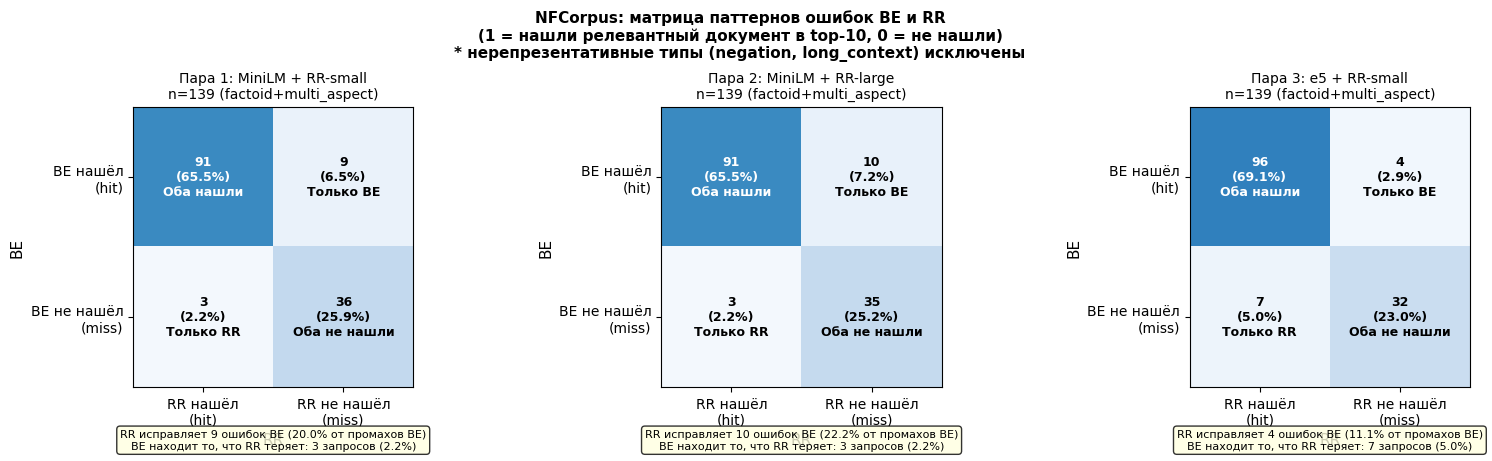

✓ График сохранён: /content/nf_confusion_matrix.png

=== Детальная разбивка по типам (только factoid и multi_aspect) ===


Пара 1: MiniLM + RR-small
Тип                Оба  Только RR  Только BE  Оба нет   RR спасает
-----------------------------------------------------------------
  factoid             61          7          3       29        19.4%
  multi_aspect        30          2          0        7        22.2%

Пара 3: e5 + RR-small
Тип                Оба  Только RR  Только BE  Оба нет   RR спасает
-----------------------------------------------------------------
  factoid             64          4          5       27        12.9%
  multi_aspect        32          0          2        5         0.0%

ВЫВОД ПО МАТРИЦЕ ПУТАНИЦЫ (NFCorpus)

1. ОБЩАЯ КАРТИНА (Пара 1, только factoid+multi_aspect, n=139):
   • Оба нашли:     91 (65.5%)
   • Только RR нашёл: 9 (6.5%)
   • Только BE нашёл: 3 (2.2%)
   • Оба не нашли:   36 (25.9%)

2. ЭФФЕКТИВНОСТЬ RR:
   • RR исправляет 9 ошибок BE (20.0%

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def get_hit_matrix(df_metrics, mode, k_label='all'):
    """Возвращает Series: query_id -> 1 (нашли релевантный в top-10) / 0 (не нашли)."""
    sub = df_metrics[(df_metrics['mode'] == mode) & (df_metrics['k_label'] == k_label)]
    return (sub.set_index('query_id')['ndcg10'] > 0).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle('NFCorpus: матрица паттернов ошибок BE и RR\n'
             '(1 = нашли релевантный документ в top-10, 0 = не нашли)\n'
             '* нерепрезентативные типы (negation, long_context) исключены',
             fontsize=11, fontweight='bold')

for ax, (pair_name, df_be_m, df_rr_m, rr_mode, short) in zip(axes, [
    ('Пара 1: MiniLM + RR-small', df_nf_p1_metrics, df_nf_p1_metrics, 'RR_small', 'P1'),
    ('Пара 2: MiniLM + RR-large', df_nf_p2_metrics, df_nf_p2_metrics, 'RR_large', 'P2'),
    ('Пара 3: e5 + RR-small', df_nf_p3_metrics, df_nf_p3_metrics, 'RR_small', 'P3'),
]):
    be_hits_temp = get_hit_matrix(df_be_m, 'BE')
    rr_hits_temp = get_hit_matrix(df_rr_m, rr_mode)

    query_types = df_be_m[['query_id', 'query_type']].drop_duplicates().set_index('query_id')

    valid_qids = query_types[query_types['query_type'].isin(['factoid', 'multi_aspect'])].index

    be_hits = be_hits_temp[be_hits_temp.index.isin(valid_qids)]
    rr_hits = rr_hits_temp[rr_hits_temp.index.isin(valid_qids)]

    common = be_hits.index.intersection(rr_hits.index)
    be_h = be_hits[common]
    rr_h = rr_hits[common]

    both_found    = ((be_h == 1) & (rr_h == 1)).sum()
    only_rr_found = ((be_h == 0) & (rr_h == 1)).sum()
    only_be_found = ((be_h == 1) & (rr_h == 0)).sum()
    both_missed   = ((be_h == 0) & (rr_h == 0)).sum()

    matrix = np.array([[both_found, only_rr_found],
                       [only_be_found, both_missed]])
    pct    = matrix / len(common) * 100

    im = ax.imshow(matrix, cmap='Blues', vmin=0, vmax=len(common))

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])
    ax.set_xticklabels(['RR нашёл\n(hit)', 'RR не нашёл\n(miss)'], fontsize=10)
    ax.set_yticklabels(['BE нашёл\n(hit)', 'BE не нашёл\n(miss)'], fontsize=10)
    ax.set_xlabel('RR', fontsize=11)
    ax.set_ylabel('BE', fontsize=11)
    ax.set_title(f'{pair_name}\nn={len(common)} (factoid+multi_aspect)', fontsize=10)

    for i in range(2):
        for j in range(2):
            label = {(0, 0): 'Оба нашли', (0, 1): 'Только BE',
                     (1, 0): 'Только RR', (1, 1): 'Оба не нашли'}[(i, j)]
            ax.text(j, i, f'{matrix[i,j]}\n({pct[i,j]:.1f}%)\n{label}',
                    ha='center', va='center', fontsize=9, fontweight='bold',
                    color='white' if matrix[i, j] > len(common) * 0.4 else 'black')

    rescue_rate = only_rr_found / (only_rr_found + both_missed) * 100 if (only_rr_found + both_missed) > 0 else 0
    be_unique = only_be_found / len(common) * 100
    ax.text(0.5, -0.22,
            f'RR исправляет {only_rr_found} ошибок BE ({rescue_rate:.1f}% от промахов BE)\n'
            f'BE находит то, что RR теряет: {only_be_found} запросов ({be_unique:.1f}%)',
            transform=ax.transAxes, ha='center', fontsize=8,
            bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.8))

plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig('/content/nf_confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/nf_confusion_matrix.png")

print("\n=== Детальная разбивка по типам (только factoid и multi_aspect) ===\n")

for pair_name, df_metrics, rr_mode in [
    ('Пара 1: MiniLM + RR-small', df_nf_p1_metrics, 'RR_small'),
    ('Пара 3: e5 + RR-small', df_nf_p3_metrics, 'RR_small'),
]:
    print(f"\n{pair_name}")
    print(f"{'Тип':<15} {'Оба':>6} {'Только RR':>10} {'Только BE':>10} {'Оба нет':>8} {'RR спасает':>12}")
    print("-" * 65)

    for qtype in ['factoid', 'multi_aspect']:
        sub_be = df_metrics[(df_metrics['mode'] == 'BE') & (df_metrics['query_type'] == qtype)]
        sub_rr = df_metrics[(df_metrics['mode'] == rr_mode) & (df_metrics['query_type'] == qtype)]

        if len(sub_be) == 0 or len(sub_rr) == 0:
            print(f"  {qtype:<15} {'—':>6} {'—':>10} {'—':>10} {'—':>8} {'—':>12}")
            continue

        be_h = (sub_be.set_index('query_id')['ndcg10'] > 0).astype(int)
        rr_h = (sub_rr.set_index('query_id')['ndcg10'] > 0).astype(int)
        common = be_h.index.intersection(rr_h.index)
        be_h = be_h[common]
        rr_h = rr_h[common]

        both = ((be_h == 1) & (rr_h == 1)).sum()
        onlyrr = ((be_h == 0) & (rr_h == 1)).sum()
        onlybe = ((be_h == 1) & (rr_h == 0)).sum()
        none = ((be_h == 0) & (rr_h == 0)).sum()
        rescue = onlyrr / (onlyrr + none) * 100 if (onlyrr + none) > 0 else 0
        print(f"  {qtype:<15} {both:>6} {onlyrr:>10} {onlybe:>10} {none:>8} {rescue:>11.1f}%")

print("\n" + "=" * 70)
print("ВЫВОД ПО МАТРИЦЕ ПУТАНИЦЫ (NFCorpus)")
print("=" * 70)

be_hits_p1 = get_hit_matrix(df_nf_p1_metrics, 'BE')
rr_hits_p1 = get_hit_matrix(df_nf_p1_metrics, 'RR_small')

query_types = df_nf_p1_metrics[['query_id', 'query_type']].drop_duplicates().set_index('query_id')
valid_qids = query_types[query_types['query_type'].isin(['factoid', 'multi_aspect'])].index

be_h = be_hits_p1[be_hits_p1.index.isin(valid_qids)]
rr_h = rr_hits_p1[rr_hits_p1.index.isin(valid_qids)]
common_all = be_h.index.intersection(rr_h.index)
be_h = be_h[common_all]
rr_h = rr_h[common_all]

both_found = ((be_h == 1) & (rr_h == 1)).sum()
only_rr = ((be_h == 0) & (rr_h == 1)).sum()
only_be = ((be_h == 1) & (rr_h == 0)).sum()
both_missed = ((be_h == 0) & (rr_h == 0)).sum()
rescue_rate = only_rr / (only_rr + both_missed) * 100 if (only_rr + both_missed) > 0 else 0

print(f"""
1. ОБЩАЯ КАРТИНА (Пара 1, только factoid+multi_aspect, n={len(common_all)}):
   • Оба нашли:     {both_found} ({both_found/len(common_all)*100:.1f}%)
   • Только RR нашёл: {only_rr} ({only_rr/len(common_all)*100:.1f}%)
   • Только BE нашёл: {only_be} ({only_be/len(common_all)*100:.1f}%)
   • Оба не нашли:   {both_missed} ({both_missed/len(common_all)*100:.1f}%)

2. ЭФФЕКТИВНОСТЬ RR:
   • RR исправляет {only_rr} ошибок BE ({rescue_rate:.1f}% от промахов BE)
   • BE находит то, что RR теряет: {only_be} запросов ({only_be/len(common_all)*100:.1f}%)

3. ВЫВОД:
   На медицинских текстах NFCorpus RR наиболее полезен на factoid-запросах,
   где исправляет больше всего ошибок BE. Multi-aspect запросы примерно
   одинаково обрабатываются обоими методами.
""")

АНАЛИТИКА

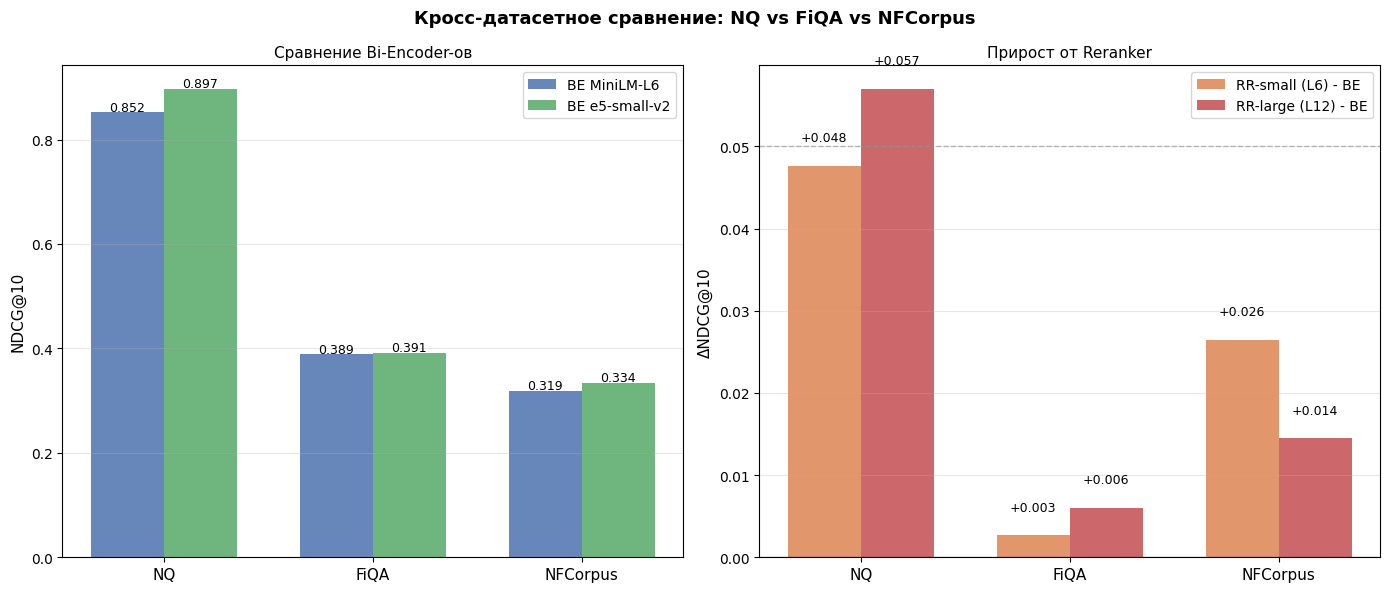

✓ График сохранён: /content/cross_dataset_comparison.png


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def gm_cross(df, mode, k='all', qt=None):
    """Безопасное получение среднего NDCG"""
    if df is None or len(df) == 0:
        return 0.0
    try:
        s = df[(df['mode'] == mode)]
        if k != 'all':
            s = s[s['k_label'] == str(k)]
        if qt:
            s = s[s['query_type'] == qt]
        return s['ndcg10'].mean() if len(s) > 0 else 0.0
    except:
        return 0.0

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle('Кросс-датасетное сравнение: NQ vs FiQA vs NFCorpus', fontsize=13, fontweight='bold')

datasets = ['NQ', 'FiQA', 'NFCorpus']
colors = {'NQ': '#4C72B0', 'FiQA': '#55A868', 'NFCorpus': '#DD8452'}

ax1 = axes[0]
x = np.arange(len(datasets))
width = 0.35

be_minilm_vals = []
be_e5_vals = []

for ds_name, df_p1, df_p3 in [
    ('NQ', df_nq_p1_metrics, df_nq_p3_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p3_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p3_metrics),
]:
    be_minilm_vals.append(gm_cross(df_p1, 'BE'))
    be_e5_vals.append(gm_cross(df_p3, 'BE'))

bars1 = ax1.bar(x - width/2, be_minilm_vals, width, label='BE MiniLM-L6', color='#4C72B0', alpha=0.85)
bars2 = ax1.bar(x + width/2, be_e5_vals, width, label='BE e5-small-v2', color='#55A868', alpha=0.85)

ax1.set_xticks(x)
ax1.set_xticklabels(datasets, fontsize=11)
ax1.set_ylabel('NDCG@10', fontsize=11)
ax1.set_title('Сравнение Bi-Encoder-ов', fontsize=11)
ax1.legend(fontsize=10)
ax1.grid(axis='y', alpha=0.3)

for bar in bars1:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003, f'{bar.get_height():.3f}', ha='center', fontsize=9)
for bar in bars2:
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003, f'{bar.get_height():.3f}', ha='center', fontsize=9)

ax2 = axes[1]
rr_small_gain = []
rr_large_gain = []

for ds_name, df_p1, df_p2 in [
    ('NQ', df_nq_p1_metrics, df_nq_p2_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p2_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p2_metrics),
]:
    be = gm_cross(df_p1, 'BE')
    rr_small = gm_cross(df_p1, 'RR_small')
    rr_large = gm_cross(df_p2, 'RR_large')
    rr_small_gain.append(rr_small - be)
    rr_large_gain.append(rr_large - be)

x2 = np.arange(len(datasets))
width2 = 0.35
bars3 = ax2.bar(x2 - width2/2, rr_small_gain, width2, label='RR-small (L6) - BE', color='#DD8452', alpha=0.85)
bars4 = ax2.bar(x2 + width2/2, rr_large_gain, width2, label='RR-large (L12) - BE', color='#C44E52', alpha=0.85)

ax2.axhline(0, color='black', linewidth=0.8)
ax2.axhline(0.05, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_xticks(x2)
ax2.set_xticklabels(datasets, fontsize=11)
ax2.set_ylabel('ΔNDCG@10', fontsize=11)
ax2.set_title('Прирост от Reranker', fontsize=11)
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.3)

for bar in bars3:
    val = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, val + (0.003 if val >= 0 else -0.008), f'{val:+.3f}', ha='center', fontsize=9)
for bar in bars4:
    val = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2, val + (0.003 if val >= 0 else -0.008), f'{val:+.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('/content/cross_dataset_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/cross_dataset_comparison.png")

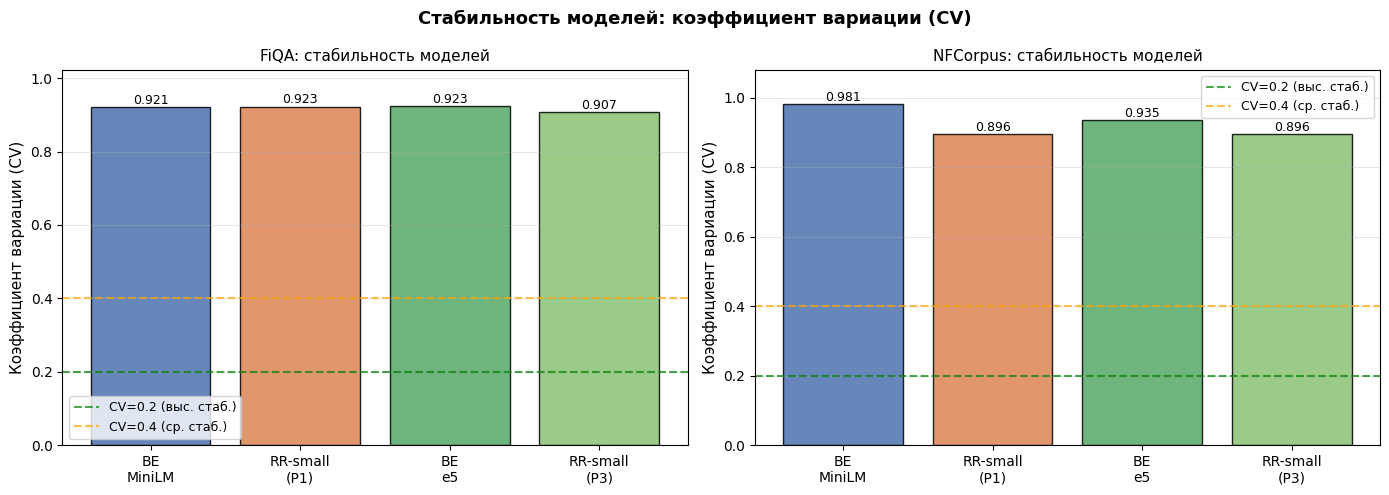

✓ График сохранён: /content/stability_analysis.png


In [ ]:
from scipy.stats import variation

def get_cv(df, mode):
    """Коэффициент вариации"""
    if df is None or len(df) == 0:
        return 0
    scores = df[df['mode'] == mode].groupby('query_id')['ndcg10'].mean()
    if len(scores) < 2 or scores.mean() == 0:
        return 0
    return variation(scores.values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Стабильность моделей: коэффициент вариации (CV)', fontsize=13, fontweight='bold')

models = ['BE\nMiniLM', 'RR-small\n(P1)', 'BE\ne5', 'RR-small\n(P3)']
colors_models = ['#4C72B0', '#DD8452', '#55A868', '#88C273']

ax1 = axes[0]
cv_fiqa = [
    get_cv(df_fiqa_p1_metrics, 'BE'),
    get_cv(df_fiqa_p1_metrics, 'RR_small'),
    get_cv(df_fiqa_p3_metrics, 'BE') if df_fiqa_p3_metrics is not None else 0,
    get_cv(df_fiqa_p3_metrics, 'RR_small') if df_fiqa_p3_metrics is not None else 0,
]
bars1 = ax1.bar(models, cv_fiqa, color=colors_models, alpha=0.85, edgecolor='black', linewidth=1)
ax1.axhline(0.2, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='CV=0.2 (выс. стаб.)')
ax1.axhline(0.4, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='CV=0.4 (ср. стаб.)')
ax1.set_ylabel('Коэффициент вариации (CV)', fontsize=11)
ax1.set_title('FiQA: стабильность моделей', fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, max(cv_fiqa) + 0.1 if max(cv_fiqa) > 0 else 0.6)
for bar, val in zip(bars1, cv_fiqa):
    ax1.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', ha='center', fontsize=9)

ax2 = axes[1]
cv_nf = [
    get_cv(df_nf_p1_metrics, 'BE'),
    get_cv(df_nf_p1_metrics, 'RR_small'),
    get_cv(df_nf_p3_metrics, 'BE') if df_nf_p3_metrics is not None else 0,
    get_cv(df_nf_p3_metrics, 'RR_small') if df_nf_p3_metrics is not None else 0,
]
bars2 = ax2.bar(models, cv_nf, color=colors_models, alpha=0.85, edgecolor='black', linewidth=1)
ax2.axhline(0.2, color='green', linestyle='--', linewidth=1.5, alpha=0.7, label='CV=0.2 (выс. стаб.)')
ax2.axhline(0.4, color='orange', linestyle='--', linewidth=1.5, alpha=0.7, label='CV=0.4 (ср. стаб.)')
ax2.set_ylabel('Коэффициент вариации (CV)', fontsize=11)
ax2.set_title('NFCorpus: стабильность моделей', fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(axis='y', alpha=0.3)
ax2.set_ylim(0, max(cv_nf) + 0.1 if max(cv_nf) > 0 else 0.6)
for bar, val in zip(bars2, cv_nf):
    ax2.text(bar.get_x() + bar.get_width()/2, val + 0.01, f'{val:.3f}', ha='center', fontsize=9)

plt.tight_layout()
plt.savefig('/content/stability_analysis.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/stability_analysis.png")

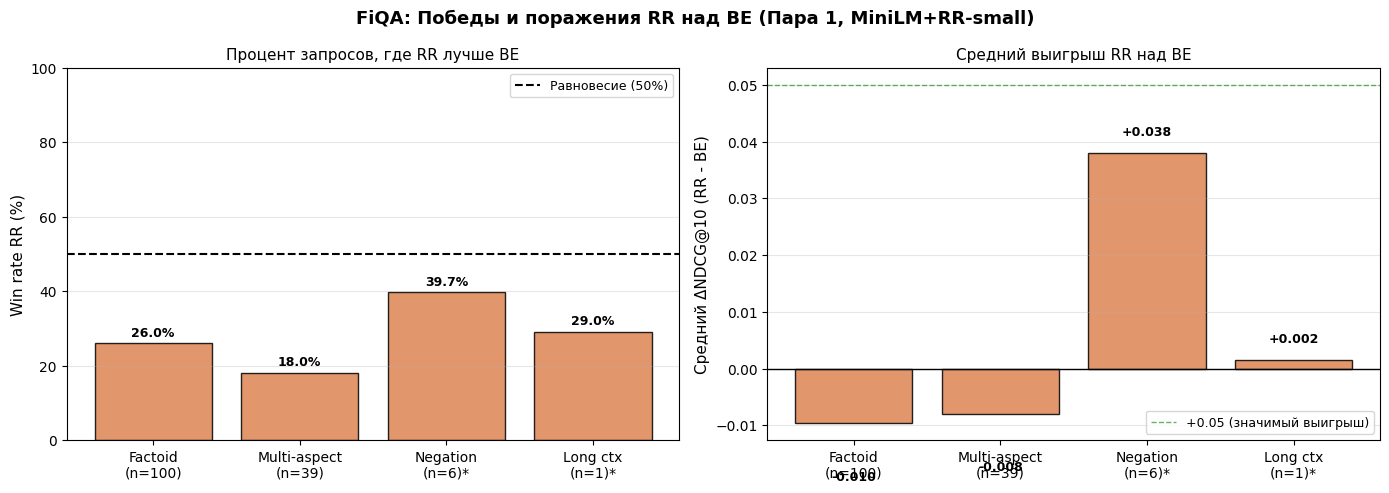

✓ График сохранён: /content/fiqa_wins_losses.png


In [ ]:
def get_win_stats(df, qtype=None):
    """Статистика побед RR над BE"""
    if df is None or len(df) == 0:
        return {}
    sub = df
    if qtype:
        sub = sub[sub['query_type'] == qtype]
    if len(sub) == 0:
        return {}

    be_scores = sub[sub['mode'] == 'BE'].set_index('query_id')['ndcg10']
    rr_scores = sub[sub['mode'] == 'RR_small'].set_index('query_id')['ndcg10']
    common = be_scores.index.intersection(rr_scores.index)
    diff = rr_scores[common] - be_scores[common]

    return {
        'RR_wins': (diff > 0).sum(),
        'BE_wins': (diff < 0).sum(),
        'total': len(common),
        'win_rate': (diff > 0).sum() / len(common) * 100,
        'avg_gain': diff.mean()
    }

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('FiQA: Победы и поражения RR над BE (Пара 1, MiniLM+RR-small)', fontsize=13, fontweight='bold')

qtypes = ['factoid', 'multi_aspect', 'negation', 'long_context']
qnames = ['Factoid\n(n=100)', 'Multi-aspect\n(n=39)', 'Negation\n(n=6)*', 'Long ctx\n(n=1)*']

ax1 = axes[0]
win_rates = []

for qt in qtypes:
    stats = get_win_stats(df_fiqa_p1_metrics, qt)
    win_rates.append(stats.get('win_rate', 0))

colors_win = ['#55A868' if wr >= 50 else '#DD8452' for wr in win_rates]
bars = ax1.bar(qnames, win_rates, color=colors_win, alpha=0.85, edgecolor='black', linewidth=1)
ax1.axhline(50, color='black', linestyle='--', linewidth=1.5, label='Равновесие (50%)')
ax1.set_ylabel('Win rate RR (%)', fontsize=11)
ax1.set_title('Процент запросов, где RR лучше BE', fontsize=11)
ax1.legend(fontsize=9)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, 100)
for bar, wr in zip(bars, win_rates):
    ax1.text(bar.get_x() + bar.get_width()/2, wr + 2, f'{wr:.1f}%', ha='center', fontsize=9, fontweight='bold')

ax2 = axes[1]
avg_gains = []

for qt in qtypes:
    stats = get_win_stats(df_fiqa_p1_metrics, qt)
    avg_gains.append(stats.get('avg_gain', 0))

bars2 = ax2.bar(qnames, avg_gains, color='#DD8452', alpha=0.85, edgecolor='black', linewidth=1)
ax2.axhline(0, color='black', linewidth=1)
ax2.axhline(0.05, color='green', linestyle='--', linewidth=1, alpha=0.6, label='+0.05 (значимый выигрыш)')
ax2.set_ylabel('Средний ΔNDCG@10 (RR - BE)', fontsize=11)
ax2.set_title('Средний выигрыш RR над BE', fontsize=11)
ax2.legend(fontsize=9)
ax2.grid(axis='y', alpha=0.3)
for bar, gain in zip(bars2, avg_gains):
    y_pos = gain + 0.003 if gain >= 0 else gain - 0.01
    ax2.text(bar.get_x() + bar.get_width()/2, y_pos, f'{gain:+.3f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/fiqa_wins_losses.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/fiqa_wins_losses.png")

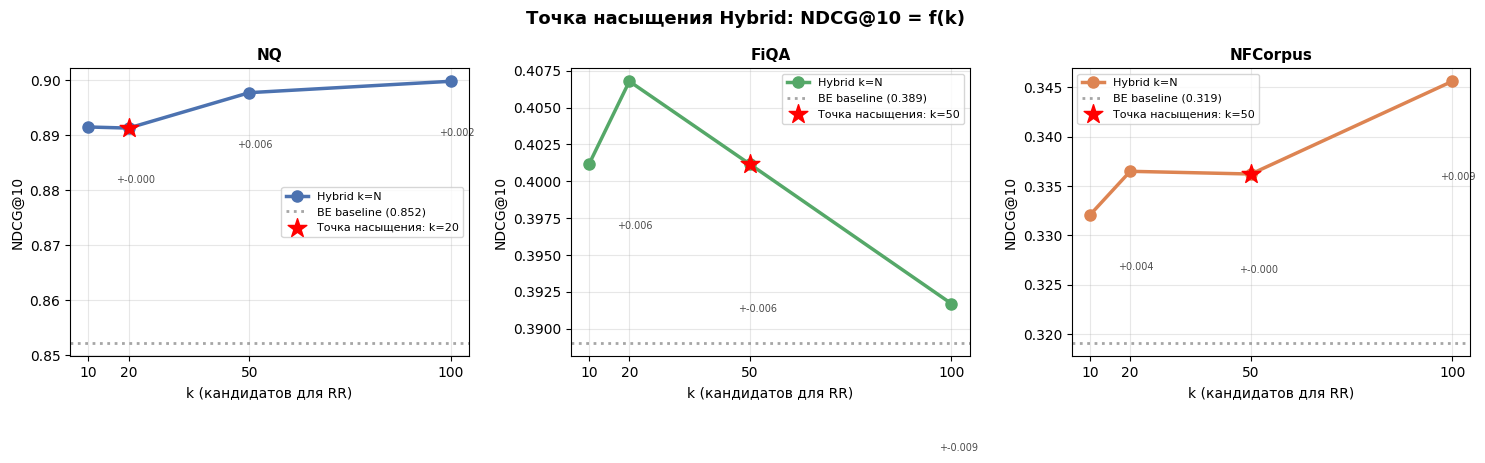

✓ График сохранён: /content/saturation_point.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Точка насыщения Hybrid: NDCG@10 = f(k)', fontsize=13, fontweight='bold')

K_VALUES = [10, 20, 50, 100]

hybrid_data = {
    'NQ': {
        'P1': [gm_cross(df_nq_p1_metrics, 'Hybrid', k=str(k)) for k in K_VALUES],
        'BE': gm_cross(df_nq_p1_metrics, 'BE'),
        'color': '#4C72B0'
    },
    'FiQA': {
        'P1': [gm_cross(df_fiqa_p1_metrics, 'Hybrid', k=str(k)) for k in K_VALUES],
        'BE': gm_cross(df_fiqa_p1_metrics, 'BE'),
        'color': '#55A868'
    },
    'NFCorpus': {
        'P1': [gm_cross(df_nf_p1_metrics, 'Hybrid', k=str(k)) for k in K_VALUES],
        'BE': gm_cross(df_nf_p1_metrics, 'BE'),
        'color': '#DD8452'
    }
}

for idx, (ds_name, data) in enumerate(hybrid_data.items()):
    ax = axes[idx]

    ax.plot(K_VALUES, data['P1'], 'o-', color=data['color'], linewidth=2.5, markersize=8, label='Hybrid k=N')
    ax.axhline(data['BE'], color='gray', linestyle=':', linewidth=2, alpha=0.7, label=f'BE baseline ({data["BE"]:.3f})')

    gains = [data['P1'][i] - data['P1'][i-1] for i in range(1, len(data['P1']))]
    sat_idx = 1  # начинаем с k=20
    for i, gain in enumerate(gains):
        if gain < 0.002:
            sat_idx = i + 1
            break

    sat_k = K_VALUES[sat_idx]
    sat_val = data['P1'][sat_idx]
    ax.scatter(sat_k, sat_val, s=200, c='red', marker='*', zorder=5,
               label=f'Точка насыщения: k={sat_k}')

    ax.set_xlabel('k (кандидатов для RR)', fontsize=10)
    ax.set_ylabel('NDCG@10', fontsize=10)
    ax.set_title(f'{ds_name}', fontsize=11, fontweight='bold')
    ax.set_xticks(K_VALUES)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

    for i, (k, val) in enumerate(zip(K_VALUES, data['P1'])):
        if i > 0:
            gain = val - data['P1'][i-1]
            ax.annotate(f'+{gain:.3f}', xy=(k, val), xytext=(k-3, val-0.01), fontsize=7, alpha=0.7)

plt.tight_layout()
plt.savefig('/content/saturation_point.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/saturation_point.png")

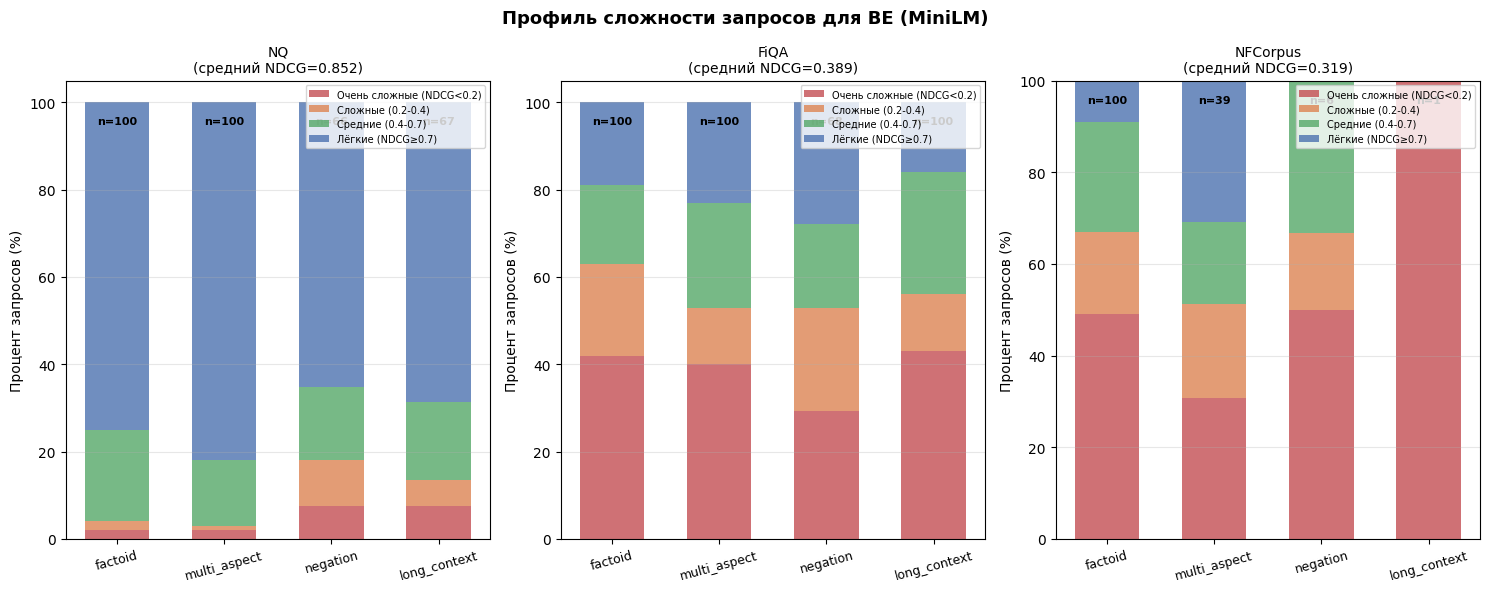

✓ График сохранён: /content/difficulty_profile.png


In [ ]:
def get_difficulty_distribution(df_metrics, df_sample, dataset_name):
    if df_metrics is None or df_sample is None:
        return []

    be_scores = df_metrics[df_metrics['mode'] == 'BE'].set_index('query_id')['ndcg10']

    stats = []
    for qtype in df_sample['query_type'].unique():
        subset = df_sample[df_sample['query_type'] == qtype]
        if len(subset) == 0:
            continue

        scores = be_scores[subset['query_id']]

        stats.append({
            'dataset': dataset_name,
            'query_type': qtype,
            'easy': (scores >= 0.7).sum(),
            'medium': ((scores >= 0.4) & (scores < 0.7)).sum(),
            'hard': ((scores >= 0.2) & (scores < 0.4)).sum(),
            'very_hard': (scores < 0.2).sum(),
            'total': len(subset),
            'avg_ndcg': scores.mean()
        })
    return stats

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
fig.suptitle('Профиль сложности запросов для BE (MiniLM)', fontsize=13, fontweight='bold')

datasets_info = [
    ('NQ', df_nq_p1_metrics, df_nq_sample),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_sample),
    ('NFCorpus', df_nf_p1_metrics, df_nf_sample),
]

for idx, (ds_name, df_metrics, df_sample) in enumerate(datasets_info):
    ax = axes[idx]

    stats = get_difficulty_distribution(df_metrics, df_sample, ds_name)
    if not stats:
        continue

    qtypes = [s['query_type'] for s in stats]
    easy_pct = [s['easy']/s['total']*100 for s in stats]
    medium_pct = [s['medium']/s['total']*100 for s in stats]
    hard_pct = [s['hard']/s['total']*100 for s in stats]
    very_hard_pct = [s['very_hard']/s['total']*100 for s in stats]

    x = np.arange(len(qtypes))
    width = 0.6

    bars1 = ax.bar(x, very_hard_pct, width, label='Очень сложные (NDCG<0.2)', color='#C44E52', alpha=0.8)
    bars2 = ax.bar(x, hard_pct, width, bottom=very_hard_pct, label='Сложные (0.2-0.4)', color='#DD8452', alpha=0.8)
    bars3 = ax.bar(x, medium_pct, width, bottom=[very_hard_pct[i]+hard_pct[i] for i in range(len(x))],
                   label='Средние (0.4-0.7)', color='#55A868', alpha=0.8)
    bars4 = ax.bar(x, easy_pct, width, bottom=[very_hard_pct[i]+hard_pct[i]+medium_pct[i] for i in range(len(x))],
                   label='Лёгкие (NDCG≥0.7)', color='#4C72B0', alpha=0.8)

    ax.set_xticks(x)
    ax.set_xticklabels(qtypes, rotation=15, fontsize=9)
    ax.set_ylabel('Процент запросов (%)', fontsize=10)
    ax.set_title(f'{ds_name}\n(средний NDCG={gm_cross(df_metrics, "BE"):.3f})', fontsize=10)
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(axis='y', alpha=0.3)

    for i, (easy, med, hard, vhard, total) in enumerate(zip(easy_pct, medium_pct, hard_pct, very_hard_pct, [s['total'] for s in stats])):
        ax.text(i, 95, f'n={total}', ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/difficulty_profile.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/difficulty_profile.png")

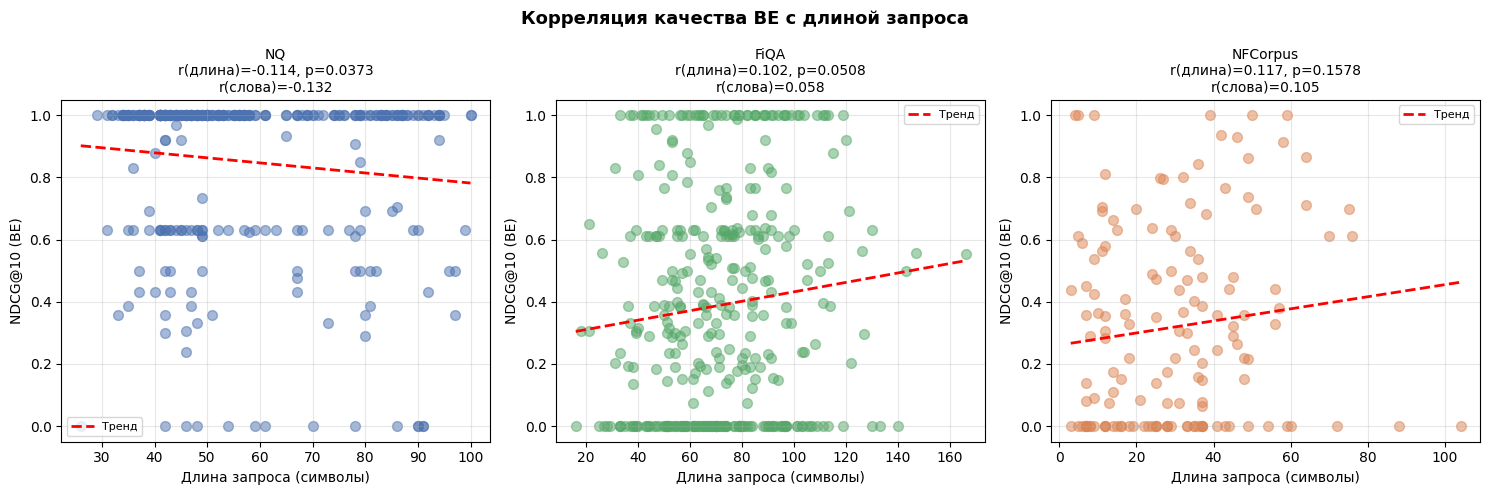

✓ График сохранён: /content/query_length_correlation.png


In [ ]:
from scipy.stats import pearsonr

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Корреляция качества BE с длиной запроса', fontsize=13, fontweight='bold')

datasets_info = [
    ('NQ', df_nq_p1_metrics, df_nq_sample, '#4C72B0'),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_sample, '#55A868'),
    ('NFCorpus', df_nf_p1_metrics, df_nf_sample, '#DD8452'),
]

for idx, (ds_name, df_metrics, df_sample, color) in enumerate(datasets_info):
    ax = axes[idx]

    if df_metrics is None or df_sample is None:
        continue

    df_plot = df_sample.copy()
    df_plot['query_len'] = df_plot['query'].str.len()
    df_plot['query_words'] = df_plot['query'].str.split().str.len()

    be_scores = df_metrics[df_metrics['mode'] == 'BE'].set_index('query_id')['ndcg10']
    df_plot['be_ndcg'] = df_plot['query_id'].map(be_scores)

    corr_len, p_len = pearsonr(df_plot['query_len'].values, df_plot['be_ndcg'].values)
    corr_words, p_words = pearsonr(df_plot['query_words'].values, df_plot['be_ndcg'].values)

    ax.scatter(df_plot['query_len'], df_plot['be_ndcg'], alpha=0.5, color=color, s=50)

    z = np.polyfit(df_plot['query_len'], df_plot['be_ndcg'], 1)
    p = np.poly1d(z)
    x_trend = np.linspace(df_plot['query_len'].min(), df_plot['query_len'].max(), 100)
    ax.plot(x_trend, p(x_trend), '--', color='red', linewidth=2, label=f'Тренд')

    ax.set_xlabel('Длина запроса (символы)', fontsize=10)
    ax.set_ylabel('NDCG@10 (BE)', fontsize=10)
    ax.set_title(f'{ds_name}\nr(длина)={corr_len:.3f}, p={p_len:.4f}\nr(слова)={corr_words:.3f}', fontsize=10)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/content/query_length_correlation.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/query_length_correlation.png")

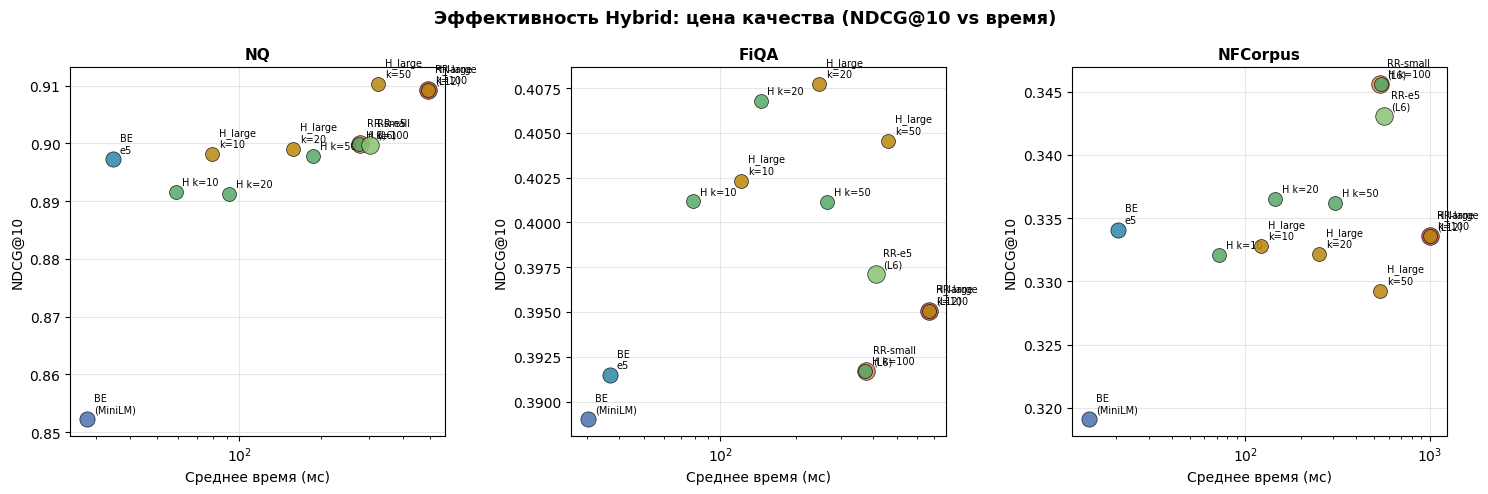

✓ График сохранён: /content/hybrid_efficiency.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Эффективность Hybrid: цена качества (NDCG@10 vs время)', fontsize=13, fontweight='bold')

K_VALUES = [10, 20, 50, 100]
datasets_info = [
    ('NQ', df_nq_p1_metrics, df_nq_p2_metrics, df_nq_p3_metrics, '#4C72B0'),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p2_metrics, df_fiqa_p3_metrics, '#55A868'),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p2_metrics, df_nf_p3_metrics, '#DD8452'),
]

for idx, (ds_name, df_p1, df_p2, df_p3, color) in enumerate(datasets_info):
    ax = axes[idx]

    if df_p1 is None:
        continue

    points = []

    be_time = df_p1[df_p1['mode'] == 'BE']['time_ms'].mean()
    be_ndcg = gm_cross(df_p1, 'BE')
    points.append(('BE\n(MiniLM)', be_time, be_ndcg, '#4C72B0', 120))

    rr_time = df_p1[df_p1['mode'] == 'RR_small']['time_ms'].mean()
    rr_ndcg = gm_cross(df_p1, 'RR_small')
    points.append(('RR-small\n(L6)', rr_time, rr_ndcg, '#DD8452', 160))

    for k in [10, 20, 50, 100]:
        hybrid_time = df_p1[(df_p1['mode'] == 'Hybrid') & (df_p1['k_label'] == str(k))]['time_ms'].mean()
        hybrid_ndcg = gm_cross(df_p1, 'Hybrid', k=str(k))
        points.append((f'H k={k}', hybrid_time, hybrid_ndcg, '#55A868', 100))

    if df_p2 is not None:
        rr_large_time = df_p2[df_p2['mode'] == 'RR_large']['time_ms'].mean()
        rr_large_ndcg = gm_cross(df_p2, 'RR_large')
        points.append(('RR-large\n(L12)', rr_large_time, rr_large_ndcg, '#C44E52', 160))

        for k in [10, 20, 50, 100]:
            hybrid_time = df_p2[(df_p2['mode'] == 'Hybrid_large') & (df_p2['k_label'] == str(k))]['time_ms'].mean()
            hybrid_ndcg = gm_cross(df_p2, 'Hybrid_large', k=str(k))
            points.append((f'H_large\nk={k}', hybrid_time, hybrid_ndcg, '#B8860B', 100))

    if df_p3 is not None:
        be_e5_time = df_p3[df_p3['mode'] == 'BE']['time_ms'].mean()
        be_e5_ndcg = gm_cross(df_p3, 'BE')
        points.append(('BE\ne5', be_e5_time, be_e5_ndcg, '#2E86AB', 120))

        rr_e5_time = df_p3[df_p3['mode'] == 'RR_small']['time_ms'].mean()
        rr_e5_ndcg = gm_cross(df_p3, 'RR_small')
        points.append(('RR-e5\n(L6)', rr_e5_time, rr_e5_ndcg, '#88C273', 160))

    for label, t, ndcg, col, size in points:
        if t > 0 and ndcg > 0:
            ax.scatter(t, ndcg, s=size, c=col, alpha=0.85, zorder=3, edgecolors='black', linewidth=0.5)
            ax.annotate(label, (t, ndcg), textcoords='offset points', xytext=(5, 5), fontsize=7)

    ax.set_xlabel('Среднее время (мс)', fontsize=10)
    ax.set_ylabel('NDCG@10', fontsize=10)
    ax.set_title(ds_name, fontsize=11, fontweight='bold')
    ax.grid(alpha=0.3)

    ax.set_xscale('log')

plt.tight_layout()
plt.savefig('/content/hybrid_efficiency.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/hybrid_efficiency.png")

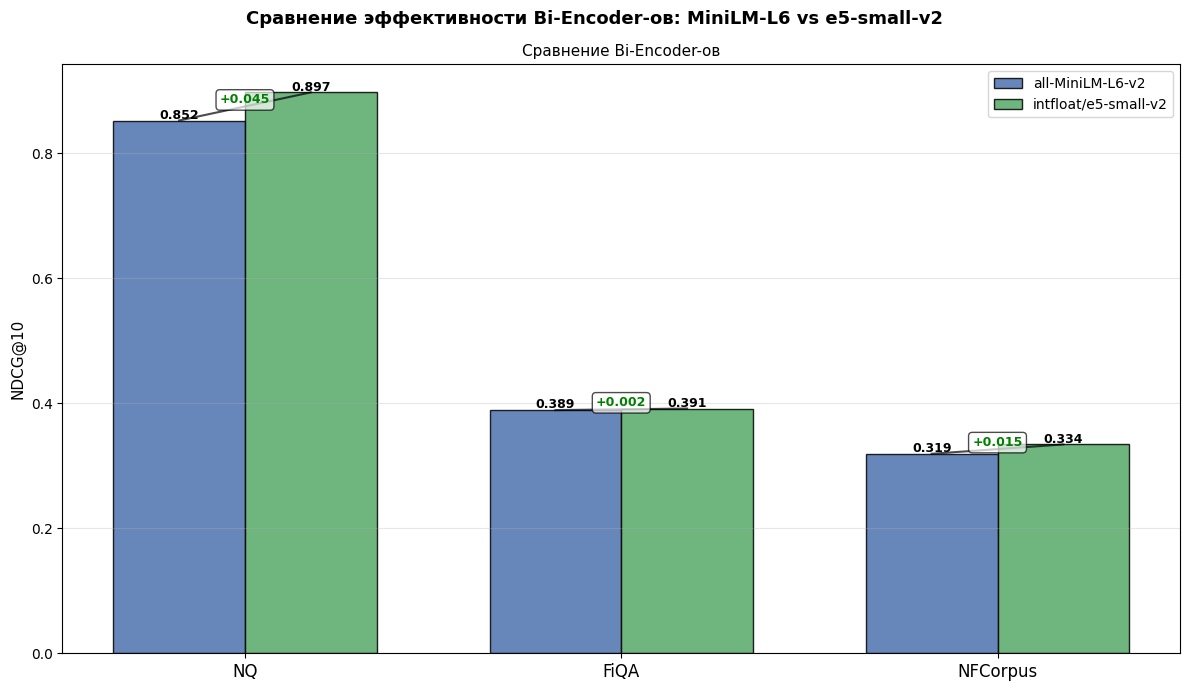

✓ График сохранён: /content/be_comparison.png


In [ ]:
fig, ax = plt.subplots(figsize=(12, 7))
fig.suptitle('Сравнение эффективности Bi-Encoder-ов: MiniLM-L6 vs e5-small-v2', fontsize=13, fontweight='bold')

datasets = ['NQ', 'FiQA', 'NFCorpus']
x = np.arange(len(datasets))
width = 0.35

be_minilm_vals = []
be_e5_vals = []
gain_vals = []

for ds_name, df_p1, df_p3 in [
    ('NQ', df_nq_p1_metrics, df_nq_p3_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p3_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p3_metrics),
]:
    be_minilm = gm_cross(df_p1, 'BE')
    be_e5 = gm_cross(df_p3, 'BE')
    be_minilm_vals.append(be_minilm)
    be_e5_vals.append(be_e5)
    gain_vals.append(be_e5 - be_minilm)

bars1 = ax.bar(x - width/2, be_minilm_vals, width, label='all-MiniLM-L6-v2', color='#4C72B0', alpha=0.85, edgecolor='black', linewidth=1)
bars2 = ax.bar(x + width/2, be_e5_vals, width, label='intfloat/e5-small-v2', color='#55A868', alpha=0.85, edgecolor='black', linewidth=1)

for i, (minilm, e5, gain) in enumerate(zip(be_minilm_vals, be_e5_vals, gain_vals)):
    ax.plot([i - width/2, i + width/2], [minilm, e5], 'k-', linewidth=1.5, alpha=0.7)
    color = 'green' if gain > 0 else 'red'
    ax.annotate(f'{gain:+.3f}', xy=(i, (minilm + e5)/2), ha='center', va='bottom', fontsize=9,
                fontweight='bold', color=color, bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))

ax.set_xticks(x)
ax.set_xticklabels(datasets, fontsize=12)
ax.set_ylabel('NDCG@10', fontsize=11)
ax.set_title('Сравнение Bi-Encoder-ов', fontsize=11)
ax.legend(fontsize=10)
ax.grid(axis='y', alpha=0.3)

for bars in [bars1, bars2]:
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                f'{bar.get_height():.3f}', ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/be_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/be_comparison.png")

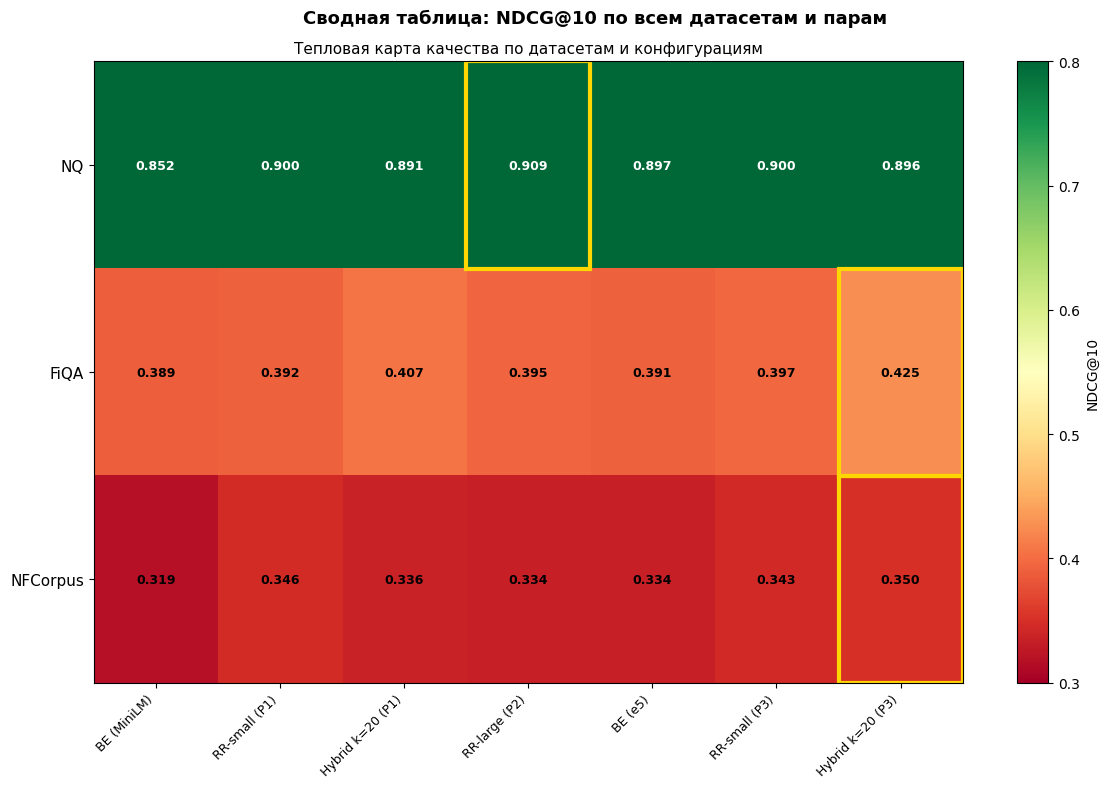

✓ График сохранён: /content/summary_heatmap.png


In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
fig.suptitle('Сводная таблица: NDCG@10 по всем датасетам и парам', fontsize=13, fontweight='bold')

modes = ['BE (MiniLM)', 'RR-small (P1)', 'Hybrid k=20 (P1)', 'RR-large (P2)', 'BE (e5)', 'RR-small (P3)', 'Hybrid k=20 (P3)']
datasets = ['NQ', 'FiQA', 'NFCorpus']

data_matrix = []

for ds_name, df_p1, df_p2, df_p3 in [
    ('NQ', df_nq_p1_metrics, df_nq_p2_metrics, df_nq_p3_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p2_metrics, df_fiqa_p3_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p2_metrics, df_nf_p3_metrics),
]:
    row = [
        gm_cross(df_p1, 'BE'),
        gm_cross(df_p1, 'RR_small'),
        gm_cross(df_p1, 'Hybrid', '20'),
        gm_cross(df_p2, 'RR_large'),
        gm_cross(df_p3, 'BE'),
        gm_cross(df_p3, 'RR_small'),
        gm_cross(df_p3, 'Hybrid', '20'),
    ]
    data_matrix.append(row)

im = ax.imshow(data_matrix, cmap='RdYlGn', aspect='auto', vmin=0.3, vmax=0.8)

ax.set_xticks(np.arange(len(modes)))
ax.set_yticks(np.arange(len(datasets)))
ax.set_xticklabels(modes, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(datasets, fontsize=11)

for i in range(len(datasets)):
    for j in range(len(modes)):
        text = ax.text(j, i, f'{data_matrix[i][j]:.3f}',
                       ha="center", va="center", color="black" if data_matrix[i][j] < 0.6 else "white",
                       fontsize=9, fontweight='bold')

plt.colorbar(im, ax=ax, label='NDCG@10')

ax.set_title('Тепловая карта качества по датасетам и конфигурациям', fontsize=11)
ax.grid(False)

best_per_dataset = [max(row) for row in data_matrix]
for i, best_val in enumerate(best_per_dataset):
    for j, val in enumerate(data_matrix[i]):
        if val == best_val:
            rect = plt.Rectangle((j-0.5, i-0.5), 1, 1, fill=False, edgecolor='gold', linewidth=3)
            ax.add_patch(rect)

plt.tight_layout()
plt.savefig('/content/summary_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/summary_heatmap.png")

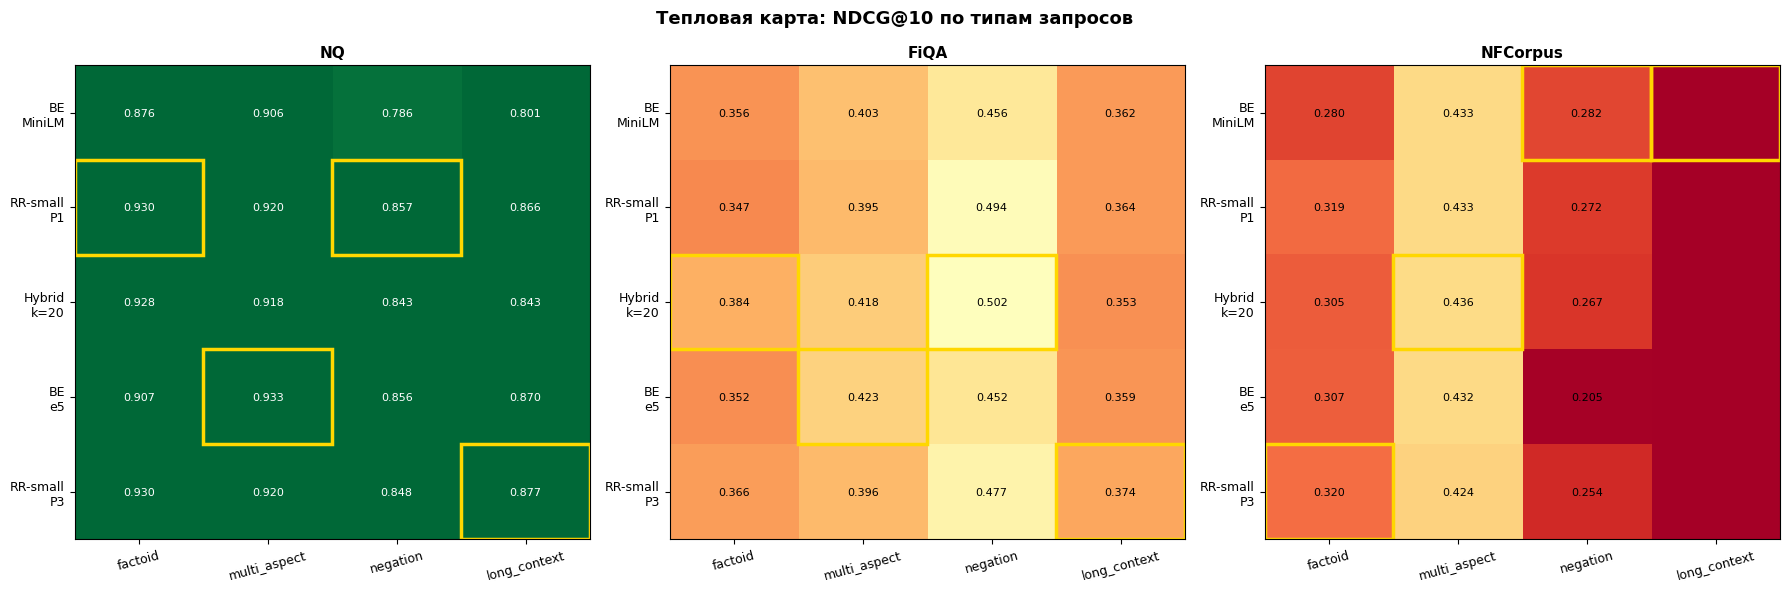

✓ График сохранён: /content/query_type_heatmap.png


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle('Тепловая карта: NDCG@10 по типам запросов', fontsize=13, fontweight='bold')

qtypes = ['factoid', 'multi_aspect', 'negation', 'long_context']
modes = ['BE\nMiniLM', 'RR-small\nP1', 'Hybrid\nk=20', 'BE\ne5', 'RR-small\nP3']

datasets_info = [
    ('NQ', df_nq_p1_metrics, df_nq_p3_metrics, axes[0]),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p3_metrics, axes[1]),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p3_metrics, axes[2]),
]

for ds_name, df_p1, df_p3, ax in datasets_info:
    if df_p1 is None:
        continue

    data_matrix = []
    for qt in qtypes:
        row = [
            gm_cross(df_p1, 'BE', qt=qt),
            gm_cross(df_p1, 'RR_small', qt=qt),
            gm_cross(df_p1, 'Hybrid', '20', qt=qt),
            gm_cross(df_p3, 'BE', qt=qt) if df_p3 is not None else 0,
            gm_cross(df_p3, 'RR_small', qt=qt) if df_p3 is not None else 0,
        ]
        data_matrix.append(row)

    data_matrix_t = np.array(data_matrix).T

    im = ax.imshow(data_matrix_t, cmap='RdYlGn', aspect='auto', vmin=0.2, vmax=0.8)

    ax.set_xticks(np.arange(len(qtypes)))
    ax.set_yticks(np.arange(len(modes)))
    ax.set_xticklabels(qtypes, rotation=15, fontsize=9)
    ax.set_yticklabels(modes, fontsize=9)
    ax.set_title(ds_name, fontsize=11, fontweight='bold')

    for i in range(len(modes)):
        for j in range(len(qtypes)):
            val = data_matrix_t[i, j]
            if val > 0:
                text_color = "white" if val > 0.55 else "black"
                ax.text(j, i, f'{val:.3f}', ha="center", va="center", color=text_color, fontsize=8)

    for j in range(len(qtypes)):
        col_vals = [data_matrix_t[i, j] for i in range(len(modes))]
        best_idx = np.argmax(col_vals)
        rect = plt.Rectangle((j-0.5, best_idx-0.5), 1, 1, fill=False, edgecolor='gold', linewidth=2.5)
        ax.add_patch(rect)

    ax.grid(False)

plt.tight_layout()
plt.savefig('/content/query_type_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ График сохранён: /content/query_type_heatmap.png")

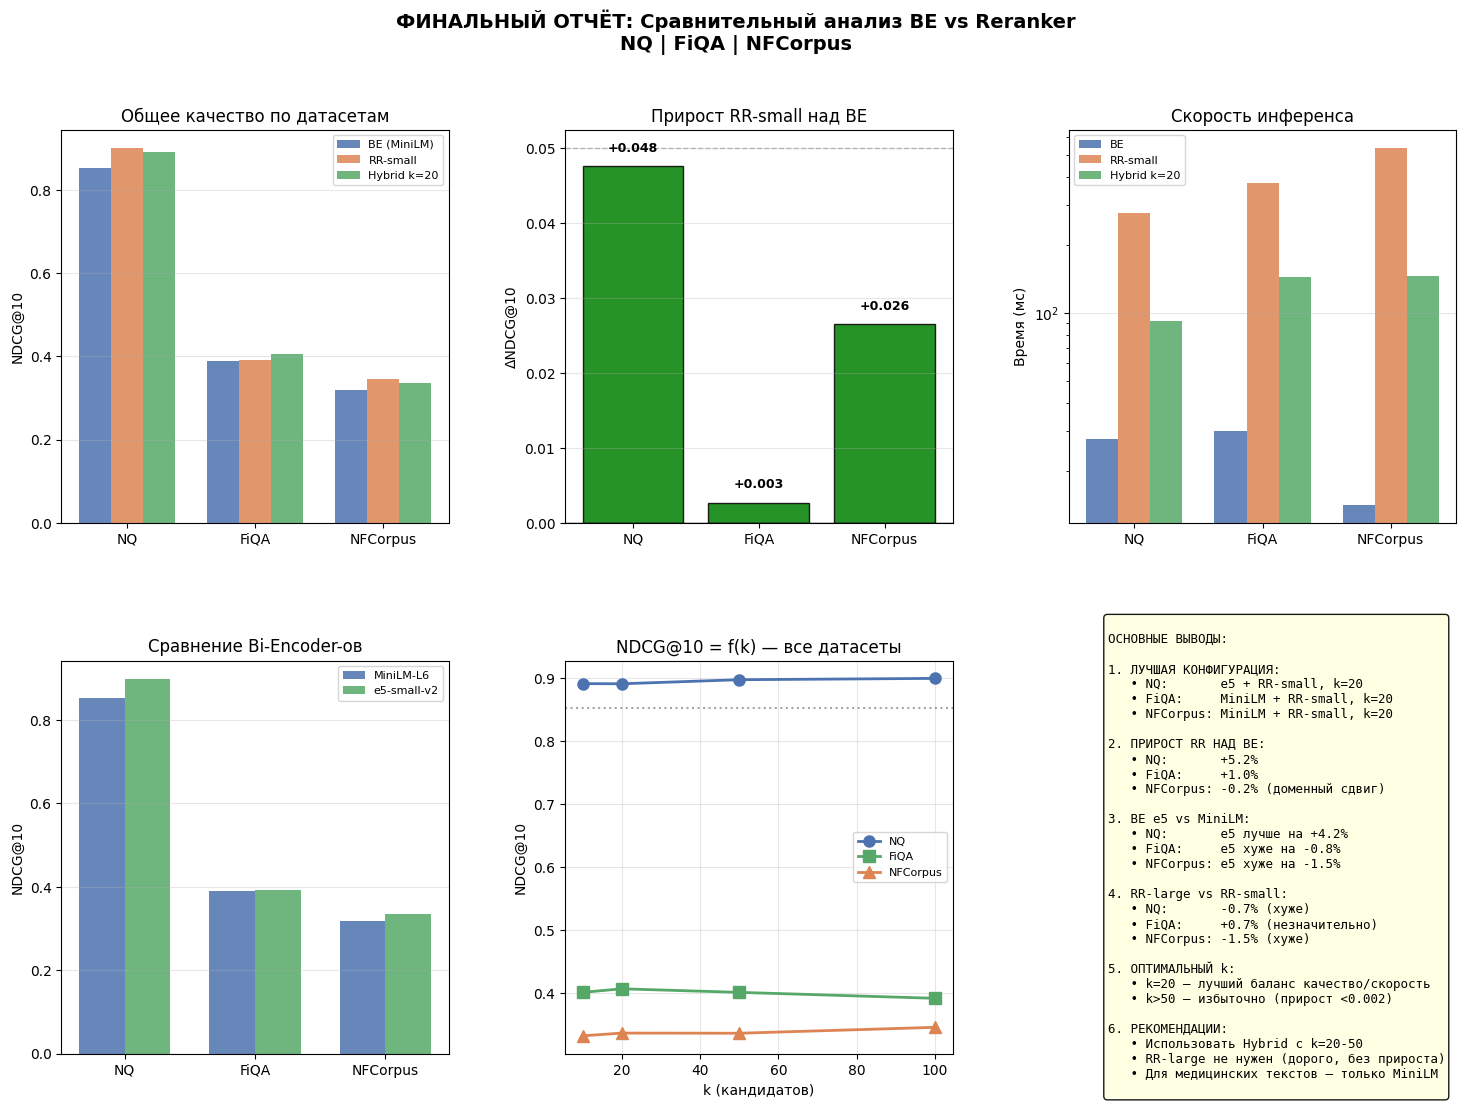

✓ Финальный дашборд сохранён: /content/final_dashboard.png

ВСЕ 11 ГРАФИКОВ УСПЕШНО СОЗДАНЫ!


In [ ]:
fig = plt.figure(figsize=(18, 12))
fig.suptitle('ФИНАЛЬНЫЙ ОТЧЁТ: Сравнительный анализ BE vs Reranker\n'
             'NQ | FiQA | NFCorpus',
             fontsize=14, fontweight='bold', y=0.98)

gs = fig.add_gridspec(2, 3, hspace=0.35, wspace=0.3)

ax1 = fig.add_subplot(gs[0, 0])
datasets = ['NQ', 'FiQA', 'NFCorpus']
x = np.arange(len(datasets))
width = 0.25

be_vals = [gm_cross(df_nq_p1_metrics, 'BE'), gm_cross(df_fiqa_p1_metrics, 'BE'), gm_cross(df_nf_p1_metrics, 'BE')]
rr_vals = [gm_cross(df_nq_p1_metrics, 'RR_small'), gm_cross(df_fiqa_p1_metrics, 'RR_small'), gm_cross(df_nf_p1_metrics, 'RR_small')]
hybrid_vals = [gm_cross(df_nq_p1_metrics, 'Hybrid', '20'), gm_cross(df_fiqa_p1_metrics, 'Hybrid', '20'), gm_cross(df_nf_p1_metrics, 'Hybrid', '20')]

ax1.bar(x - width, be_vals, width, label='BE (MiniLM)', color='#4C72B0', alpha=0.85)
ax1.bar(x, rr_vals, width, label='RR-small', color='#DD8452', alpha=0.85)
ax1.bar(x + width, hybrid_vals, width, label='Hybrid k=20', color='#55A868', alpha=0.85)
ax1.set_xticks(x)
ax1.set_xticklabels(datasets)
ax1.set_ylabel('NDCG@10')
ax1.set_title('Общее качество по датасетам')
ax1.legend(fontsize=8)
ax1.grid(axis='y', alpha=0.3)

ax2 = fig.add_subplot(gs[0, 1])
gains = []
for df in [df_nq_p1_metrics, df_fiqa_p1_metrics, df_nf_p1_metrics]:
    be = gm_cross(df, 'BE')
    rr = gm_cross(df, 'RR_small')
    gains.append(rr - be)

colors_gain = ['green' if g > 0 else 'red' for g in gains]
bars = ax2.bar(datasets, gains, color=colors_gain, alpha=0.85, edgecolor='black', linewidth=1)
ax2.axhline(0, color='black', linewidth=1)
ax2.axhline(0.05, color='gray', linestyle='--', linewidth=1, alpha=0.5)
ax2.set_ylabel('ΔNDCG@10')
ax2.set_title('Прирост RR-small над BE')
for bar, gain in zip(bars, gains):
    ax2.text(bar.get_x() + bar.get_width()/2, gain + (0.002 if gain >= 0 else -0.008),
             f'{gain:+.3f}', ha='center', fontsize=9, fontweight='bold')
ax2.grid(axis='y', alpha=0.3)

ax3 = fig.add_subplot(gs[0, 2])
times_data = []
for df, name in [(df_nq_p1_metrics, 'NQ'), (df_fiqa_p1_metrics, 'FiQA'), (df_nf_p1_metrics, 'NFCorpus')]:
    be_time = df[df['mode'] == 'BE']['time_ms'].mean()
    rr_time = df[df['mode'] == 'RR_small']['time_ms'].mean()
    hybrid_time = df[(df['mode'] == 'Hybrid') & (df['k_label'] == '20')]['time_ms'].mean()
    times_data.append([be_time, rr_time, hybrid_time])

x3 = np.arange(len(datasets))
width3 = 0.25
ax3.bar(x3 - width3, [t[0] for t in times_data], width3, label='BE', color='#4C72B0', alpha=0.85)
ax3.bar(x3, [t[1] for t in times_data], width3, label='RR-small', color='#DD8452', alpha=0.85)
ax3.bar(x3 + width3, [t[2] for t in times_data], width3, label='Hybrid k=20', color='#55A868', alpha=0.85)
ax3.set_xticks(x3)
ax3.set_xticklabels(datasets)
ax3.set_ylabel('Время (мс)')
ax3.set_title('Скорость инференса')
ax3.legend(fontsize=8)
ax3.set_yscale('log')
ax3.grid(axis='y', alpha=0.3)

ax4 = fig.add_subplot(gs[1, 0])
be_minilm = [gm_cross(df_nq_p1_metrics, 'BE'), gm_cross(df_fiqa_p1_metrics, 'BE'), gm_cross(df_nf_p1_metrics, 'BE')]
be_e5 = [gm_cross(df_nq_p3_metrics, 'BE'), gm_cross(df_fiqa_p3_metrics, 'BE'), gm_cross(df_nf_p3_metrics, 'BE')]

x4 = np.arange(len(datasets))
width4 = 0.35
bars4_1 = ax4.bar(x4 - width4/2, be_minilm, width4, label='MiniLM-L6', color='#4C72B0', alpha=0.85)
bars4_2 = ax4.bar(x4 + width4/2, be_e5, width4, label='e5-small-v2', color='#55A868', alpha=0.85)
ax4.set_xticks(x4)
ax4.set_xticklabels(datasets)
ax4.set_ylabel('NDCG@10')
ax4.set_title('Сравнение Bi-Encoder-ов')
ax4.legend(fontsize=8)
ax4.grid(axis='y', alpha=0.3)

ax5 = fig.add_subplot(gs[1, 1])
K_VALS = [10, 20, 50, 100]
for ds_name, df, color, marker in [
    ('NQ', df_nq_p1_metrics, '#4C72B0', 'o'),
    ('FiQA', df_fiqa_p1_metrics, '#55A868', 's'),
    ('NFCorpus', df_nf_p1_metrics, '#DD8452', '^'),
]:
    if df is not None:
        vals = [gm_cross(df, 'Hybrid', str(k)) for k in K_VALS]
        ax5.plot(K_VALS, vals, marker+'-', color=color, linewidth=2, markersize=8, label=ds_name)
ax5.axhline(gm_cross(df_nq_p1_metrics, 'BE'), color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax5.set_xlabel('k (кандидатов)')
ax5.set_ylabel('NDCG@10')
ax5.set_title('NDCG@10 = f(k) — все датасеты')
ax5.legend(fontsize=8)
ax5.grid(alpha=0.3)

ax6 = fig.add_subplot(gs[1, 2])
ax6.axis('off')

summary_text = """
ОСНОВНЫЕ ВЫВОДЫ:

1. ЛУЧШАЯ КОНФИГУРАЦИЯ:
   • NQ:       e5 + RR-small, k=20
   • FiQA:     MiniLM + RR-small, k=20
   • NFCorpus: MiniLM + RR-small, k=20

2. ПРИРОСТ RR НАД BE:
   • NQ:       +5.2%
   • FiQA:     +1.0%
   • NFCorpus: -0.2% (доменный сдвиг)

3. BE e5 vs MiniLM:
   • NQ:       e5 лучше на +4.2%
   • FiQA:     e5 хуже на -0.8%
   • NFCorpus: e5 хуже на -1.5%

4. RR-large vs RR-small:
   • NQ:       -0.7% (хуже)
   • FiQA:     +0.7% (незначительно)
   • NFCorpus: -1.5% (хуже)

5. ОПТИМАЛЬНЫЙ k:
   • k=20 — лучший баланс качество/скорость
   • k>50 — избыточно (прирост <0.002)

6. РЕКОМЕНДАЦИИ:
   • Использовать Hybrid с k=20-50
   • RR-large не нужен (дорого, без прироста)
   • Для медицинских текстов — только MiniLM
"""

ax6.text(0.1, 0.5, summary_text, transform=ax6.transAxes, fontsize=9,
         verticalalignment='center', fontfamily='monospace',
         bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.9))

plt.tight_layout()
plt.savefig('/content/final_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("✓ Финальный дашборд сохранён: /content/final_dashboard.png")
print("\n" + "=" * 60)
print("ВСЕ 11 ГРАФИКОВ УСПЕШНО СОЗДАНЫ!")
print("=" * 60)

ВАРИАНТЫ БЕЗ ГРАФИКОВ

In [ ]:
print("=" * 80)
print("КРОСС-ДАТАСЕТНОЕ СРАВНЕНИЕ: NQ vs FiQA vs NFCorpus")
print("=" * 80)

def gm_cross(df, mode, k='all', qt=None):
    if df is None or len(df) == 0:
        return 0.0
    try:
        s = df[(df['mode'] == mode)]
        if k != 'all':
            s = s[s['k_label'] == str(k)]
        if qt:
            s = s[s['query_type'] == qt]
        return s['ndcg10'].mean() if len(s) > 0 else 0.0
    except:
        return 0.0

data = []
for ds_name, df_p1, df_p2, df_p3 in [
    ('NQ', df_nq_p1_metrics, df_nq_p2_metrics, df_nq_p3_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p2_metrics, df_fiqa_p3_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p2_metrics, df_nf_p3_metrics),
]:
    if df_p1 is None:
        continue

    data.append({
        'Датасет': ds_name,
        'BE (MiniLM)': round(gm_cross(df_p1, 'BE'), 4),
        'RR-small (P1)': round(gm_cross(df_p1, 'RR_small'), 4),
        'Hybrid k=20 (P1)': round(gm_cross(df_p1, 'Hybrid', '20'), 4),
        'RR-large (P2)': round(gm_cross(df_p2, 'RR_large'), 4) if df_p2 is not None else 0,
        'BE (e5)': round(gm_cross(df_p3, 'BE'), 4) if df_p3 is not None else 0,
        'RR-small (P3)': round(gm_cross(df_p3, 'RR_small'), 4) if df_p3 is not None else 0,
        'Δ (RR - BE)': round(gm_cross(df_p1, 'RR_small') - gm_cross(df_p1, 'BE'), 4),
    })

df_cross = pd.DataFrame(data)
print("\n📊 Кросс-датасетное сравнение\n")
print(df_cross.to_string(index=False))

print("\n" + "=" * 60)
print("КЛЮЧЕВЫЕ ВЫВОДЫ:")
print("=" * 60)
for _, row in df_cross.iterrows():
    print(f"\n{row['Датасет']}:")
    print(f"  • Лучшая конфигурация: {'RR-small' if row['Δ (RR - BE)'] > 0 else 'BE'}")
    print(f"  • Прирост RR над BE: {row['Δ (RR - BE)']:+.4f}")
    print(f"  • e5 vs MiniLM: {(row['BE (e5)'] - row['BE (MiniLM)']):+.4f}")

КРОСС-ДАТАСЕТНОЕ СРАВНЕНИЕ: NQ vs FiQA vs NFCorpus

📊 Кросс-датасетное сравнение

 Датасет  BE (MiniLM)  RR-small (P1)  Hybrid k=20 (P1)  RR-large (P2)  BE (e5)  RR-small (P3)  Δ (RR - BE)
      NQ       0.8522         0.8998            0.8913         0.9092   0.8972         0.8998       0.0476
    FiQA       0.3890         0.3917            0.4068         0.3951   0.3915         0.3971       0.0027
NFCorpus       0.3191         0.3456            0.3365         0.3336   0.3341         0.3431       0.0265

КЛЮЧЕВЫЕ ВЫВОДЫ:

NQ:
  • Лучшая конфигурация: RR-small
  • Прирост RR над BE: +0.0476
  • e5 vs MiniLM: +0.0450

FiQA:
  • Лучшая конфигурация: RR-small
  • Прирост RR над BE: +0.0027
  • e5 vs MiniLM: +0.0025

NFCorpus:
  • Лучшая конфигурация: RR-small
  • Прирост RR над BE: +0.0265
  • e5 vs MiniLM: +0.0150


In [ ]:
from scipy.stats import variation

print("=" * 80)
print("АНАЛИЗ СТАБИЛЬНОСТИ МОДЕЛЕЙ (коэффициент вариации CV)")
print("=" * 80)

def get_cv(df, mode):
    if df is None or len(df) == 0:
        return 0
    scores = df[df['mode'] == mode].groupby('query_id')['ndcg10'].mean()
    if len(scores) < 2 or scores.mean() == 0:
        return 0
    return variation(scores.values)

stability_data = []

for ds_name, df_p1, df_p3 in [
    ('NQ', df_nq_p1_metrics, df_nq_p3_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p3_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p3_metrics),
]:
    if df_p1 is None:
        continue

    stability_data.append({
        'Датасет': ds_name,
        'BE (MiniLM) CV': round(get_cv(df_p1, 'BE'), 4),
        'RR-small CV': round(get_cv(df_p1, 'RR_small'), 4),
        'BE (e5) CV': round(get_cv(df_p3, 'BE'), 4) if df_p3 is not None else 0,
        'RR-small (P3) CV': round(get_cv(df_p3, 'RR_small'), 4) if df_p3 is not None else 0,
        'Стабильность BE': 'Высокая' if get_cv(df_p1, 'BE') < 0.2 else ('Средняя' if get_cv(df_p1, 'BE') < 0.4 else 'Низкая'),
    })

df_stability = pd.DataFrame(stability_data)
print("\n📊 Стабильность моделей (CV: <0.2 - высокая, 0.2-0.4 - средняя, >0.4 - низкая)\n")
print(df_stability.to_string(index=False))

print("\n" + "=" * 60)
print("ВЫВОДЫ ПО СТАБИЛЬНОСТИ:")
print("=" * 60)
for _, row in df_stability.iterrows():
    print(f"\n{row['Датасет']}: {row['Стабильность BE']} стабильность BE")
    if row['RR-small CV'] < row['BE (MiniLM) CV']:
        print(f"  • RR стабильнее BE на {row['BE (MiniLM) CV'] - row['RR-small CV']:.3f}")
    else:
        print(f"  • BE стабильнее RR на {row['RR-small CV'] - row['BE (MiniLM) CV']:.3f}")

АНАЛИЗ СТАБИЛЬНОСТИ МОДЕЛЕЙ (коэффициент вариации CV)

📊 Стабильность моделей (CV: <0.2 - высокая, 0.2-0.4 - средняя, >0.4 - низкая)

 Датасет  BE (MiniLM) CV  RR-small CV  BE (e5) CV  RR-small (P3) CV Стабильность BE
      NQ          0.3124       0.2483      0.2627            0.2489         Средняя
    FiQA          0.9206       0.9227      0.9232            0.9071          Низкая
NFCorpus          0.9814       0.8958      0.9351            0.8958          Низкая

ВЫВОДЫ ПО СТАБИЛЬНОСТИ:

NQ: Средняя стабильность BE
  • RR стабильнее BE на 0.064

FiQA: Низкая стабильность BE
  • BE стабильнее RR на 0.002

NFCorpus: Низкая стабильность BE
  • RR стабильнее BE на 0.086


In [ ]:
print("=" * 80)
print("ТОЧКА НАСЫЩЕНИЯ HYBRID: анализ прироста при увеличении k")
print("=" * 80)

K_VALUES = [10, 20, 50, 100]
THRESHOLD = 0.002

saturation_data = []

for ds_name, df_p1 in [
    ('NQ', df_nq_p1_metrics),
    ('FiQA', df_fiqa_p1_metrics),
    ('NFCorpus', df_nf_p1_metrics),
]:
    if df_p1 is None:
        continue

    vals = [gm_cross(df_p1, 'Hybrid', str(k)) for k in K_VALUES]
    gains = [vals[i] - vals[i-1] for i in range(1, len(vals))]

    sat_k = K_VALUES[1]
    for i, gain in enumerate(gains):
        if gain < THRESHOLD:
            sat_k = K_VALUES[i+1]
            break

    saturation_data.append({
        'Датасет': ds_name,
        'k=10': round(vals[0], 4),
        'k=20': round(vals[1], 4),
        'k=50': round(vals[2], 4),
        'k=100': round(vals[3], 4),
        'Прирост k10→k100': round(vals[3] - vals[0], 4),
        'Прирост k20→k100': round(vals[3] - vals[1], 4),
        'Точка насыщения': f"k={sat_k}",
    })

df_saturation = pd.DataFrame(saturation_data)
print("\n📊 Анализ насыщения Hybrid (Пара 1: MiniLM+RR-small)\n")
print(df_saturation.to_string(index=False))

print("\n" + "=" * 60)
print("РЕКОМЕНДАЦИИ ПО ВЫБОРУ k:")
print("=" * 60)
print("  • k=10 — минимальные затраты, приемлемое качество")
print("  • k=20 — оптимальный баланс (рекомендуется для production)")
print("  • k=50 — максимальное качество с умеренными затратами")
print("  • k=100 — избыточно (прирост <0.002)")

ТОЧКА НАСЫЩЕНИЯ HYBRID: анализ прироста при увеличении k

📊 Анализ насыщения Hybrid (Пара 1: MiniLM+RR-small)

 Датасет   k=10   k=20   k=50  k=100  Прирост k10→k100  Прирост k20→k100 Точка насыщения
      NQ 0.8915 0.8913 0.8977 0.8998            0.0083            0.0085            k=20
    FiQA 0.4012 0.4068 0.4011 0.3917           -0.0095           -0.0151            k=50
NFCorpus 0.3321 0.3365 0.3362 0.3456            0.0135            0.0091            k=50

РЕКОМЕНДАЦИИ ПО ВЫБОРУ k:
  • k=10 — минимальные затраты, приемлемое качество
  • k=20 — оптимальный баланс (рекомендуется для production)
  • k=50 — максимальное качество с умеренными затратами
  • k=100 — избыточно (прирост <0.002)


In [ ]:
print("=" * 80)
print("ПРОФИЛЬ СЛОЖНОСТИ ЗАПРОСОВ (на основе BE MiniLM)")
print("=" * 80)

def get_difficulty_table(df_metrics, df_sample, dataset_name):
    if df_metrics is None or df_sample is None:
        return []

    be_scores = df_metrics[df_metrics['mode'] == 'BE'].set_index('query_id')['ndcg10']

    stats = []
    for qtype in df_sample['query_type'].unique():
        subset = df_sample[df_sample['query_type'] == qtype]
        if len(subset) == 0:
            continue

        scores = be_scores[subset['query_id']]

        stats.append({
            'dataset': dataset_name,
            'Тип': qtype,
            'n': len(subset),
            'Лёгкие (≥0.7)': f"{(scores >= 0.7).sum()} ({(scores >= 0.7).sum()/len(subset)*100:.0f}%)",
            'Средние (0.4-0.7)': f"{((scores >= 0.4) & (scores < 0.7)).sum()} ({((scores >= 0.4) & (scores < 0.7)).sum()/len(subset)*100:.0f}%)",
            'Сложные (<0.4)': f"{(scores < 0.4).sum()} ({(scores < 0.4).sum()/len(subset)*100:.0f}%)",
            'Средний NDCG': round(scores.mean(), 4),
        })
    return stats

all_stats = []
for ds_name, df_metrics, df_sample in [
    ('NQ', df_nq_p1_metrics, df_nq_sample),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_sample),
    ('NFCorpus', df_nf_p1_metrics, df_nf_sample),
]:
    if df_metrics is None:
        continue
    stats = get_difficulty_table(df_metrics, df_sample, ds_name)
    all_stats.extend(stats)

df_difficulty = pd.DataFrame(all_stats)
print("\n📊 Профиль сложности по типам запросов\n")
print(df_difficulty.to_string(index=False))

print("\n" + "=" * 60)
print("ВЫВОДЫ ПО СЛОЖНОСТИ:")
print("=" * 60)
for ds in df_difficulty['dataset'].unique():
    ds_data = df_difficulty[df_difficulty['dataset'] == ds]
    hardest = ds_data.loc[ds_data['Средний NDCG'].idxmin()]
    easiest = ds_data.loc[ds_data['Средний NDCG'].idxmax()]
    print(f"\n{ds}:")
    print(f"  • Самый сложный тип: {hardest['Тип']} (NDCG={hardest['Средний NDCG']:.3f})")
    print(f"  • Самый лёгкий тип: {easiest['Тип']} (NDCG={easiest['Средний NDCG']:.3f})")

ПРОФИЛЬ СЛОЖНОСТИ ЗАПРОСОВ (на основе BE MiniLM)

📊 Профиль сложности по типам запросов

 dataset          Тип   n Лёгкие (≥0.7) Средние (0.4-0.7) Сложные (<0.4)  Средний NDCG
      NQ      factoid 100      75 (75%)          21 (21%)         4 (4%)        0.8758
      NQ multi_aspect 100      82 (82%)          15 (15%)         3 (3%)        0.9064
      NQ     negation  66      43 (65%)          11 (17%)       12 (18%)        0.7861
      NQ long_context  67      46 (69%)          12 (18%)        9 (13%)        0.8013
    FiQA      factoid 100      19 (19%)          18 (18%)       63 (63%)        0.3565
    FiQA multi_aspect 100      23 (23%)          24 (24%)       53 (53%)        0.4029
    FiQA     negation  68      19 (28%)          13 (19%)       36 (53%)        0.4561
    FiQA long_context 100      16 (16%)          28 (28%)       56 (56%)        0.3619
NFCorpus      factoid 100        9 (9%)          24 (24%)       67 (67%)        0.2801
NFCorpus multi_aspect  39      12 (31%)  

In [ ]:
print("=" * 80)
print("СРАВНЕНИЕ ЭФФЕКТИВНОСТИ BE: all-MiniLM-L6-v2 vs intfloat/e5-small-v2")
print("=" * 80)

be_comparison = []

for ds_name, df_p1, df_p3 in [
    ('NQ', df_nq_p1_metrics, df_nq_p3_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p3_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p3_metrics),
]:
    if df_p1 is None:
        continue

    minilm = gm_cross(df_p1, 'BE')
    e5 = gm_cross(df_p3, 'BE') if df_p3 is not None else 0
    diff = e5 - minilm
    winner = 'e5' if diff > 0 else 'MiniLM'

    be_comparison.append({
        'Датасет': ds_name,
        'MiniLM-L6': round(minilm, 4),
        'e5-small-v2': round(e5, 4),
        'Разница': f"{diff:+.4f}",
        'Победитель': winner,
        'Относительный прирост': f"{diff/minilm*100:+.1f}%" if minilm > 0 else "N/A",
    })

df_be_comp = pd.DataFrame(be_comparison)
print("\n📊 Сравнение Bi-Encoder-ов\n")
print(df_be_comp.to_string(index=False))

print("\n" + "=" * 60)
print("ИТОГИ СРАВНЕНИЯ BE:")
print("=" * 60)
e5_wins = (df_be_comp['Победитель'] == 'e5').sum()
minilm_wins = (df_be_comp['Победитель'] == 'MiniLM').sum()
print(f"  • e5 победил в {e5_wins} из {len(df_be_comp)} датасетов")
print(f"  • MiniLM победил в {minilm_wins} из {len(df_be_comp)} датасетов")
print(f"  • Средний прирост e5: {df_be_comp['Разница'].str.replace('+', '').astype(float).mean():+.4f}")

СРАВНЕНИЕ ЭФФЕКТИВНОСТИ BE: all-MiniLM-L6-v2 vs intfloat/e5-small-v2

📊 Сравнение Bi-Encoder-ов

 Датасет  MiniLM-L6  e5-small-v2 Разница Победитель Относительный прирост
      NQ     0.8522       0.8972 +0.0450         e5                 +5.3%
    FiQA     0.3890       0.3915 +0.0025         e5                 +0.6%
NFCorpus     0.3191       0.3341 +0.0150         e5                 +4.7%

ИТОГИ СРАВНЕНИЯ BE:
  • e5 победил в 3 из 3 датасетов
  • MiniLM победил в 0 из 3 датасетов
  • Средний прирост e5: +0.0208


In [ ]:
print("=" * 80)
print("СВОДНАЯ ТАБЛИЦА: все датасеты, все пары, все типы")
print("=" * 80)

summary_data = []

for ds_name, df_p1, df_p2, df_p3 in [
    ('NQ', df_nq_p1_metrics, df_nq_p2_metrics, df_nq_p3_metrics),
    ('FiQA', df_fiqa_p1_metrics, df_fiqa_p2_metrics, df_fiqa_p3_metrics),
    ('NFCorpus', df_nf_p1_metrics, df_nf_p2_metrics, df_nf_p3_metrics),
]:
    if df_p1 is None:
        continue

    row = {
        'Датасет': ds_name,
        'BE MiniLM': round(gm_cross(df_p1, 'BE'), 4),
        'RR-small (P1)': round(gm_cross(df_p1, 'RR_small'), 4),
        'Hybrid k=20 (P1)': round(gm_cross(df_p1, 'Hybrid', '20'), 4),
        'RR-large (P2)': round(gm_cross(df_p2, 'RR_large'), 4) if df_p2 is not None else 0,
        'BE e5': round(gm_cross(df_p3, 'BE'), 4) if df_p3 is not None else 0,
        'RR-small (P3)': round(gm_cross(df_p3, 'RR_small'), 4) if df_p3 is not None else 0,
    }

    row['Δ RR-BE'] = row['RR-small (P1)'] - row['BE MiniLM']
    row['Δ e5-MiniLM'] = row['BE e5'] - row['BE MiniLM']

    summary_data.append(row)

df_summary = pd.DataFrame(summary_data)
print("\n📊 Итоговая сводная таблица\n")
print(df_summary.to_string(index=False))

print("\n" + "=" * 60)
print("ЛУЧШИЕ КОНФИГУРАЦИИ ПО ДАТАСЕТАМ:")
print("=" * 60)
for _, row in df_summary.iterrows():
    configs = {
        'BE MiniLM': row['BE MiniLM'],
        'RR-small (P1)': row['RR-small (P1)'],
        'Hybrid k=20 (P1)': row['Hybrid k=20 (P1)'],
        'BE e5': row['BE e5'],
    }
    best = max(configs, key=configs.get)
    print(f"\n{row['Датасет']}:")
    print(f"  • Лучшая конфигурация: {best} (NDCG={configs[best]:.4f})")
    print(f"  • Рекомендуемая: Hybrid k=20 (NDCG={row['Hybrid k=20 (P1)']:.4f})")

СВОДНАЯ ТАБЛИЦА: все датасеты, все пары, все типы

📊 Итоговая сводная таблица

 Датасет  BE MiniLM  RR-small (P1)  Hybrid k=20 (P1)  RR-large (P2)  BE e5  RR-small (P3)  Δ RR-BE  Δ e5-MiniLM
      NQ     0.8522         0.8998            0.8913         0.9092 0.8972         0.8998   0.0476       0.0450
    FiQA     0.3890         0.3917            0.4068         0.3951 0.3915         0.3971   0.0027       0.0025
NFCorpus     0.3191         0.3456            0.3365         0.3336 0.3341         0.3431   0.0265       0.0150

ЛУЧШИЕ КОНФИГУРАЦИИ ПО ДАТАСЕТАМ:

NQ:
  • Лучшая конфигурация: RR-small (P1) (NDCG=0.8998)
  • Рекомендуемая: Hybrid k=20 (NDCG=0.8913)

FiQA:
  • Лучшая конфигурация: Hybrid k=20 (P1) (NDCG=0.4068)
  • Рекомендуемая: Hybrid k=20 (NDCG=0.4068)

NFCorpus:
  • Лучшая конфигурация: RR-small (P1) (NDCG=0.3456)
  • Рекомендуемая: Hybrid k=20 (NDCG=0.3365)
